## 0. Setup and constants

In [167]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

from pathlib import Path

SEED = 42
TRAIN_END, VAL_END = 2019, 2021   # train <=2019, val 2020-2021, test >=2022

def find_data_dir():
    kaggle = Path("/kaggle/input")
    if kaggle.exists():
        for p in kaggle.rglob("results.csv"):
            return p.parent
    local = Path("../data/raw")
    if (local / "results.csv").exists():
        return local
    raise FileNotFoundError("results.csv not found")

DATA_DIR = find_data_dir()
print("Using data from:", DATA_DIR.resolve())

Using data from: C:\Users\malik\Documents\1 Uni\SEM 9\AML\project\the_project\f1-podium-ms1\data\raw


## 1. Load raw data

In [168]:
TABLES = ["circuits","constructor_results","constructor_standings","constructors",
          "driver_standings","drivers","lap_times","pit_stops","qualifying",
          "races","results","seasons","sprint_results","status"]

raw   = {t: pd.read_csv(DATA_DIR/f"{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}
clean = {t: pd.read_csv(DATA_DIR/f"{t}.csv", na_values=[r"\N"], keep_default_na=False) for t in TABLES}

In [169]:
#sanity check to see if tabes were loaded 

for t, df in clean.items():
    print(f"{t:22s} {df.shape}")

circuits               (77, 9)
constructor_results    (12625, 5)
constructor_standings  (13391, 7)
constructors           (212, 5)
driver_standings       (34863, 7)
drivers                (861, 9)
lap_times              (589081, 6)
pit_stops              (11371, 7)
qualifying             (10494, 9)
races                  (1125, 18)
results                (26759, 18)
seasons                (75, 2)
sprint_results         (360, 16)
status                 (139, 2)


## 2. EDA before cleaning

### 2a. Table overview

In [170]:
summary = pd.DataFrame({
    t: {"rows": len(df), "cols": df.shape[1],
        "mem_MB": round(df.memory_usage(deep=True).sum() / 1e6, 2)}
    for t, df in clean.items()
}).T
display(summary)
display(clean["results"].dtypes)

,rows,cols,mem_MB
circuits,77.0,9.0,0.03
constructor_results,12625.0,5.0,0.81
constructor_standings,13391.0,7.0,1.42
constructors,212.0,5.0,0.06
driver_standings,34863.0,7.0,3.72
drivers,861.0,9.0,0.41
lap_times,589081.0,6.0,61.85
pit_stops,11371.0,7.0,1.91
qualifying,10494.0,9.0,2.17
races,1125.0,18.0,0.75


resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number             float64
grid                 int64
position           float64
positionText        object
positionOrder        int64
points             float64
laps                 int64
time                object
milliseconds       float64
fastestLap         float64
rank               float64
fastestLapTime      object
fastestLapSpeed    float64
statusId             int64
dtype: object

**Observation:** the 14 tables range from 75 rows (seasons) to 589,081 (lap times). results, our base table has 26,759 rows and 18 columns. In results, time, fastestLapTime and positionText are stored as text and number, position, milliseconds, and rank are floats only because they contain missing values

**Why it matters:** DUrations cant be used numerically while they are strings, and the float dtypes show that missing values are present

**Decision:** Scemantic typing in section 3: lap-time strings to seconds, date strings to datetime, integer like columns to nullable integers

### 2b. Sentinel audit

,table,column,n_sentinel,pct_sentinel,n_empty_str
13,constructor_results,status,12608,99.865347,0
81,races,sprint_time,1110,98.666667,0
80,races,sprint_date,1107,98.400000,0
77,races,fp3_time,1072,95.288889,0
73,races,fp1_time,1057,93.955556,0
75,races,fp2_time,1057,93.955556,0
79,races,quali_time,1057,93.955556,0
76,races,fp3_date,1053,93.600000,0
35,drivers,number,802,93.147503,0
72,races,fp1_date,1035,92.000000,0


Columns with empty-string placeholders: 2


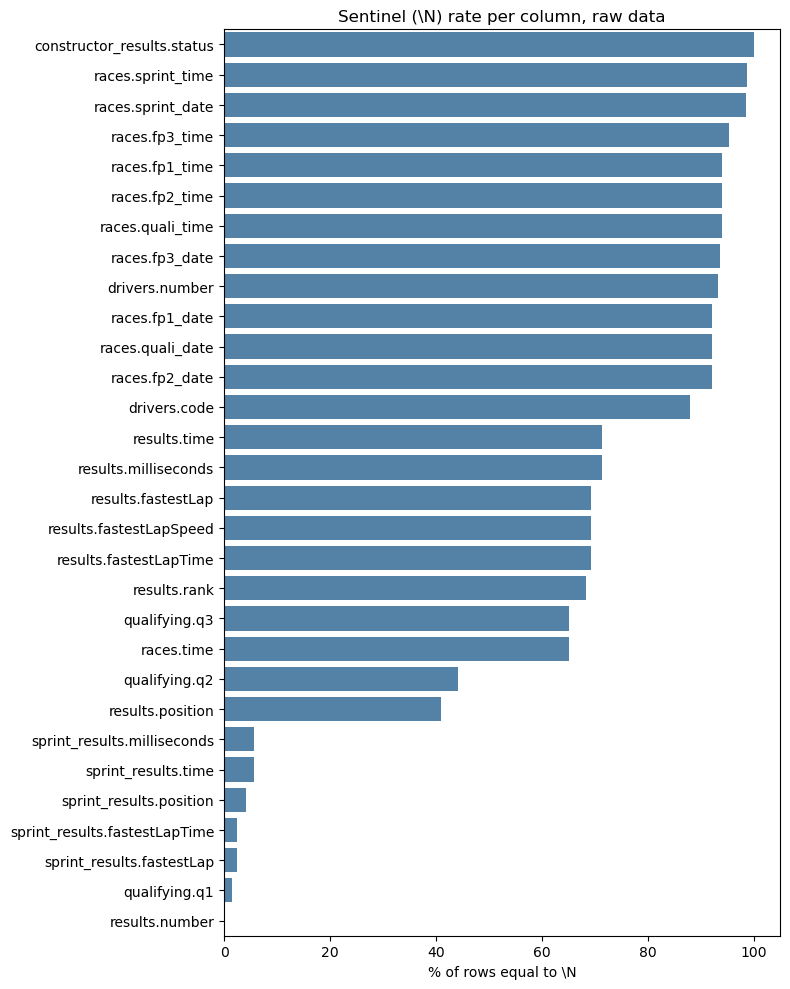

In [171]:
rows = []
for t, df in raw.items():
    for col in df.columns:
        n_sent  = int((df[col] == r"\N").sum())
        n_empty = int((df[col].str.strip() == "").sum())
        rows.append({"table": t, "column": col, "n_sentinel": n_sent,
                     "pct_sentinel": 100 * n_sent / len(df), "n_empty_str": n_empty})
sentinel = pd.DataFrame(rows)

sent_nz = sentinel[sentinel.n_sentinel > 0].sort_values("pct_sentinel", ascending=False)
display(sent_nz)
print("Columns with empty-string placeholders:", int((sentinel.n_empty_str > 0).sum()))

plot_df = sent_nz.assign(label=sent_nz.table + "." + sent_nz.column)
fig, ax = plt.subplots(figsize=(8, 0.3 * len(plot_df) + 1))
sns.barplot(data=plot_df, y="label", x="pct_sentinel", ax=ax, color="steelblue")
ax.set_xlabel("% of rows equal to \\N")
ax.set_ylabel("")
ax.set_title("Sentinel (\\N) rate per column, raw data")
plt.tight_layout()
plt.show()

**Observation:** 30 columns across 6 tables contain \N. They fall into the following 3 groups

    1. Practically empty: constructor_results.status (99.9%), the races pactice, qualifying and sprint schedule columns (92-99%), drivers.number (93.1%) and drivers.code (87.9%), These are only filled for recent seasons
    2. Post-race columns: results.time and milliseconds(71.3%), fastestLap* (69.2%) and rank (68.2%).
    3. Pre-race and target related: qualifying.q1 (1.5%), q2 (44.1%), q3 (65.0%), and results.position (40.9%, drivers with no official classification). positionOrder doesnt appear in the list, so it has no \N and is safe for the target.

qualifying.q2 and q3 also contain 22 and 46 empty string values, so \N is not the only placeholder

**Why it matters:** Group 2 is post-race information, so its missingness is irrelevant to us. THese columns go on the leakage list. The q2/q3 missingness is structural: dirivers knocked out in Q1 or Q2 have no later time, and older season recorded only one session. It is not random. so it shouldnt be mean imputed.

**Decision:** Drop group 1 columns from the modeling table. Convert blank strings to NaN in addition to \N. Handle q2/q3 missingness with an explicit missing indicator or by deriving a qualifying position.

### 2c. Duplicate (raceID, driverID) pairs

rows involved: 176 | duplicated pairs: 85


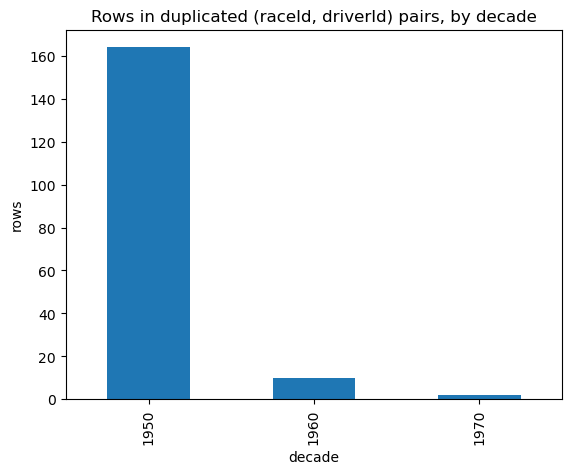

,raceId,driverId,constructorId,grid,positionOrder,points,statusId,year
13188,540,229,54,0,26,0.0,81,1978
13191,540,229,57,0,29,0.0,97,1978
17362,717,373,172,1,7,0.0,60,1964
24298,717,373,172,1,12,0.0,98,1964
17740,733,465,172,0,22,0.0,54,1962
17743,733,465,97,0,25,0.0,54,1962
17961,742,475,102,20,19,0.0,2,1961
17963,742,475,172,5,21,0.0,23,1961
18062,745,418,172,11,17,0.0,6,1961
24297,745,418,172,15,11,0.0,18,1961


In [172]:
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId", how="left")

dups = res[res.duplicated(["raceId", "driverId"], keep=False)]
print("rows involved:", len(dups),
      "| duplicated pairs:", dups.groupby(["raceId", "driverId"]).ngroups)

dups.assign(decade=(dups.year // 10) * 10).groupby("decade").size().plot(
    kind="bar", title="Rows in duplicated (raceId, driverId) pairs, by decade")
plt.ylabel("rows"); plt.show()

dups.sort_values(["raceId", "driverId"]).head(12)[
    ["raceId", "driverId", "constructorId", "grid", "positionOrder", "points", "statusId", "year"]]

**Observation:** 85 duplicated pairs involve 176 rows (0.7% of results). Dropping to one row per pair removes 91 rows. About 164 of the 176 rows are in the 1950s, around 10 in the 1960s, and about 2 in the 1970s, consistent with shared drives. A few pairs have three rows can be checked with `dups.groupby(["raceId","driverId"]).size().value_counts()`.

**Why it matters:** The target is defined per driver per race, so (raceId, driverId) must be unique. The rule we choose can change a label: for raceId 746, driver 475 (1960), one row has grid=1 and positionOrder=17, the other has grid=8 and positionOrder=3.

**Decision (proposed):** see the rule below

In [173]:
key = ["raceId", "driverId"]
res["podium"] = (res.positionOrder <= 3).astype(int)
d = res[res.duplicated(key, keep=False)].copy()

# Rule A (proposed): started car, then best grid, then lowest resultId
d["started"] = (d.grid > 0).astype(int)
rule_a = (d.sort_values(key + ["started", "grid", "resultId"],
                        ascending=[True, True, False, True, True])
            .drop_duplicates(key, keep="first"))

# Rule B (alternative, for comparison only): best positionOrder
rule_b = d.sort_values(key + ["positionOrder"]).drop_duplicates(key, keep="first")

cmp = rule_a.merge(rule_b, on=key, suffixes=("_A", "_B"))
conflict = d.groupby(key)["podium"].nunique().gt(1)

print("duplicate groups:", len(cmp))
print("rows dropped by rule A:", len(d) - len(rule_a))
print("groups whose rows disagree on podium label:", int(conflict.sum()))
print("groups where rule A and rule B give different labels:", int((cmp.podium_A != cmp.podium_B).sum()))
print("years of affected groups:", int(d.year.min()), "-", int(d.year.max()))

duplicate groups: 85
rows dropped by rule A: 91
groups whose rows disagree on podium label: 21
groups where rule A and rule B give different labels: 17
years of affected groups: 1950 - 1978


**Duplicate rule:** For each duplicated `(raceId, driverId)` pair we keep one row: first a row with a grid slot `(grid > 0)`, then the lowest grid, then the lowest `resultId` as a deterministic tiebreaker.

**Why:** The rule uses only pre-race information, so row selection cannot depend on the outcome we predict. We rejected "keep the best `positionOrder`" because it selects rows using the target, which biases ambiguous cases toward podium labels.

**Impact:** The rule drops 91 rows (0.34% of 26,759). In 21 of the 85 duplicated groups the rows disagree on podium status, and the alternative rule would change the label in 17 of them. All affected races fall between 1950 and 1978, so a training window starting in 2003 is unaffected.

**Limitation:** The dataset doesn't record which car was a driver's own in a shared drive, so the rule is a heuristic. For example, in raceId 746 (driver 475) it keeps a non-podium row although the driver also finished third in a second car.

### 2d. Qualifying coverage by season

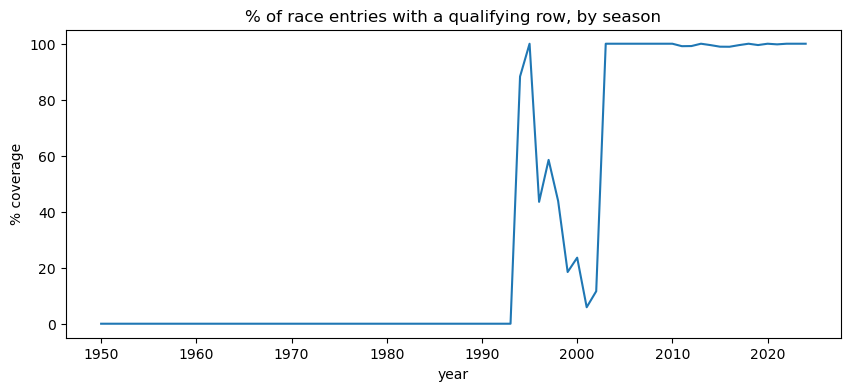

First season with any qualifying data: 1994


In [174]:
base = res[["raceId", "driverId", "year"]].drop_duplicates()
q = clean["qualifying"][["raceId", "driverId"]].drop_duplicates().assign(has_q=1)
cov = base.merge(q, on=["raceId", "driverId"], how="left").fillna({"has_q": 0})
cov_year = cov.groupby("year")["has_q"].mean() * 100

cov_year.plot(figsize=(10, 4), title="% of race entries with a qualifying row, by season")
plt.ylabel("% coverage"); plt.show()
print("First season with any qualifying data:", cov_year[cov_year > 0].index.min())

**Observation:** There is no qualifying data before 1994, confirming the intro document's estimate of the mid-1990s. Coverage is ~88% in 1994, ~100% in 1995, then falls and fluctuates between ~6% and ~58% through 2002. From 2003 onward it is ~100%.

**Why it matters:** Coverage is not monotonic: there are two data-quality regimes, with a patchy window in between. A qualifying-time feature would be missing for most pre-2003 rows, so a model could mostly learn from the absence of the feature.

**Decision (proposed):** Use `grid` as the universal starting-position feature, because it exists in all years. Treat qualifying times as optional features, either by restricting the training window to 2003-2019 or by adding missing indicators. The split from the brief (train ≤2019, validation 2020-2021, test ≥2022) is unaffected.

### 2e. Base rate, field size and grid = 0

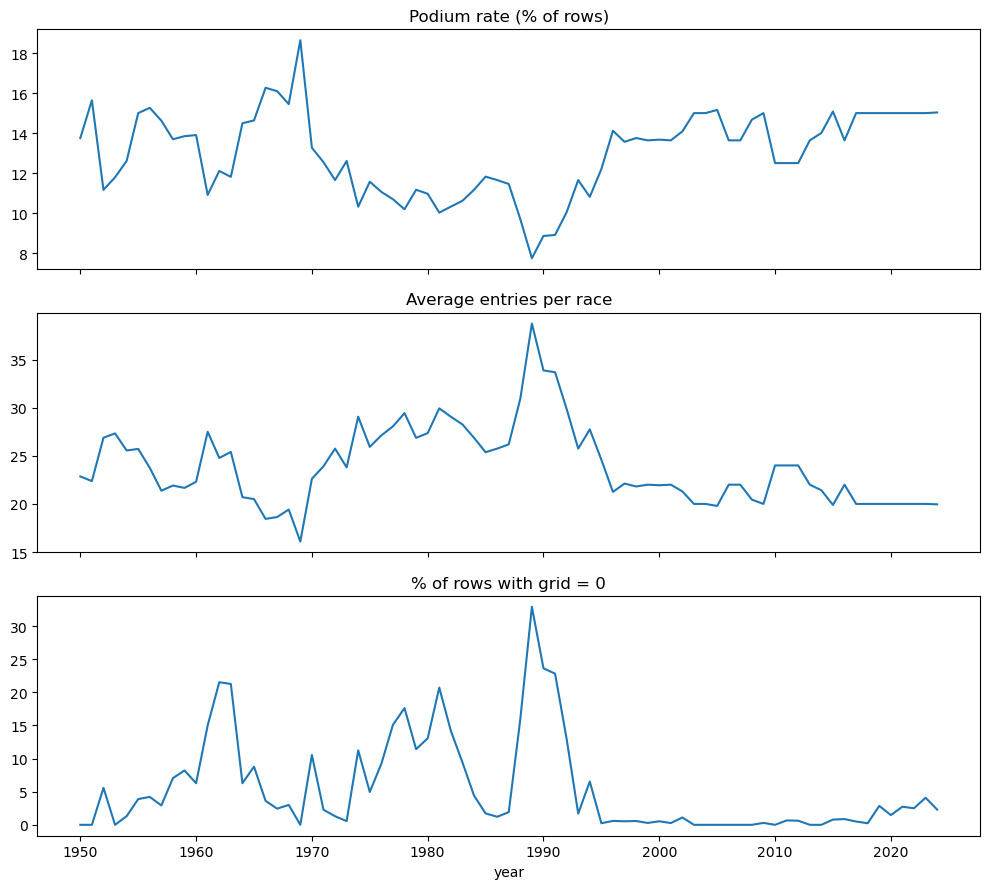

In [175]:
res["podium"] = (res.positionOrder <= 3).astype(int)

podium_rate = res.groupby("year")["podium"].mean() * 100
field_size  = res.groupby(["year", "raceId"]).size().groupby("year").mean()
grid_zero   = (res.grid == 0).groupby(res.year).mean() * 100

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
podium_rate.plot(ax=axes[0], title="Podium rate (% of rows)")
field_size.plot(ax=axes[1], title="Average entries per race")
grid_zero.plot(ax=axes[2], title="% of rows with grid = 0")
plt.tight_layout(); plt.show()

In [176]:
z = res[res.grid == 0].copy()
z["era"] = np.where(z.year < 1994, "1950-93", "1994-2024")
pd.crosstab(z.positionText, z.era)

era,1950-93,1994-2024
positionText,,
10,0,7
11,0,4
12,0,3
13,0,7
14,0,3
15,0,6
16,0,6
17,0,9
18,0,6


**Observation:** Among rows with grid = 0, the 1950-93 era has 1,508 rows: 1,495 are F (1,309) or W (186) and the other 13 are D (6), E (6) or R (1). None has a numeric finishing position. In 1994-2024 the 130 such rows are mixed: 60 have a numeric finishing position, 13 retired (consistent with pit-lane starts), 56 are F or W, and 1 is E.

**Why it matters:** A non-starter never had a chance of a podium, so including them lowers the apparent base rate in large-field eras, and grid = 0 cannot be used as a single numeric starting position.

**Decision (proposed):** Treat grid = 0 with positionText in {F, W} as non-starters and exclude them from the modeling table. Keep the other grid = 0 rows, flagged with a pit_lane_start feature

## 3. Cleaning

We apply the decisions made in Section 2 to a copy of the raw tables. The raw CSVs are
never modified. Cleaning is done in this order:

1. **Sentinel handling** — `\N` and empty strings become `NaN`.
2. **Semantic typing** — dates to `datetime`, lap-time strings to numeric seconds,
   integer-like columns to nullable integers.
3. **Column drops** — post-race leakage columns and practically-empty columns are dropped.
4. **Grain fix** — one row per `(raceId, driverId)`, using the pre-race duplicate rule from Section 2c.
5. **Non-starter exclusion** — rows with `grid = 0` and `positionText in {F, W}` are removed.

Each step reports row/column counts before and after, so Section 6 can quantify the impact.

In [177]:
# Work on a fresh copy so nothing from Section 2 leaks in.
c = {t: df.copy() for t, df in clean.items()}

# Helper: log shape changes across cleaning steps
cleaning_log = []

def log_step(step, table, before, after, note=""):
    cleaning_log.append({
        "step": step,
        "table": table,
        "rows_before": before[0], "rows_after": after[0],
        "cols_before": before[1], "cols_after": after[1],
        "note": note,
    })

### 3.1 Sentinel handling and semantic typing

**`\N` handling.** Already done at load time via `na_values=[r"\N"]`. We now also
convert empty strings to `NaN` in the two `qualifying` columns that contain them
(`q2`: 22 rows, `q3`: 46 rows — Section 2b).

**Semantic typing.**
- Dates (`races.date`, `races.fp1_date`, ..., `races.sprint_date`) → `datetime64`.
- Lap-time and duration strings (`q1/q2/q3`, `results.time`, `results.fastestLapTime`,
  `results.milliseconds`) → numeric seconds. `results.milliseconds` is already numeric;
  we only parse the `M:SS.mmm` strings.
- Integer-like columns that currently hold floats because of `NaN`
  (`position`, `rank`, `fastestLap`, `number`) → nullable `Int64`.

#### empty string to NaN and date parsing

In [178]:
# 1) Empty strings -> NaN in qualifying
for col in ["q1", "q2", "q3"]:
    c["qualifying"][col] = c["qualifying"][col].replace(r"^\s*$", np.nan, regex=True)

# 2) Parse dates in races.csv
date_cols = ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
for col in date_cols:
    if col in c["races"].columns:
        c["races"][col] = pd.to_datetime(c["races"][col], errors="coerce")

# Sanity check
print("races.date range:", c["races"].date.min(), "->", c["races"].date.max())
print("q2 NaN:", c["qualifying"].q2.isna().sum(), "| q3 NaN:", c["qualifying"].q3.isna().sum())

races.date range: 1950-05-13 00:00:00 -> 2024-12-08 00:00:00
q2 NaN: 4647 | q3 NaN: 6865


#### lap-time strings to seconds

In [179]:
def lap_to_seconds(s):
    """Parse 'M:SS.mmm' or 'SS.mmm' or 'H:MM:SS.mmm' to float seconds. NaN stays NaN."""
    if pd.isna(s):
        return np.nan
    s = str(s).strip()
    if s == "" or s.lower() in {"nan", "none"}:
        return np.nan
    parts = s.split(":")
    try:
        if len(parts) == 1:
            return float(parts[0])
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])
    except ValueError:
        return np.nan
    return np.nan

# Apply to qualifying q1/q2/q3
for col in ["q1", "q2", "q3"]:
    c["qualifying"][col + "_sec"] = c["qualifying"][col].map(lap_to_seconds)

# Apply to results.time (only keep the delta-style durations; full race times are 'M:SS.mmm' too)
c["results"]["time_sec"] = c["results"]["time"].map(lap_to_seconds)
c["results"]["fastestLapTime_sec"] = c["results"]["fastestLapTime"].map(lap_to_seconds)

# Quick check
print(c["qualifying"][["q1_sec", "q2_sec", "q3_sec"]].describe().round(2))
print()
print(c["results"][["time_sec", "fastestLapTime_sec"]].describe().round(2))

         q1_sec   q2_sec   q3_sec
count  10338.00  5847.00  3629.00
mean      88.53    87.77    87.41
std       15.39    12.11    12.26
min       53.90    53.65    53.38
25%       78.77    77.94    77.24
50%       87.14    87.12    87.04
75%       95.91    95.96    95.63
max     1002.64   132.47   129.78

       time_sec  fastestLapTime_sec
count   7680.00             8252.00
mean     983.01               90.83
std     2324.23               12.34
min        0.01               55.40
25%       24.59               80.85
50%       52.77               90.27
75%       86.19               99.48
max    14679.54              202.30


In [180]:
# q1_sec max was 1002.64 s in the describe() above: not a real qualifying lap
for col in ["q1", "q2", "q3"]:
    mask = c["qualifying"][col + "_sec"] > 240
    print(col, "laps > 240 s:", int(mask.sum()))
    display(c["qualifying"].loc[mask, ["qualifyId", "raceId", "driverId", col, col + "_sec"]])
    c["qualifying"].loc[mask, col + "_sec"] = np.nan

q1 laps > 240 s: 1


,qualifyId,raceId,driverId,q1,q1_sec
2567,2569,255,87,16:42.640,1002.64


q2 laps > 240 s: 0


,qualifyId,raceId,driverId,q2,q2_sec


q3 laps > 240 s: 0


,qualifyId,raceId,driverId,q3,q3_sec


#### nullable integers

In [181]:
for col in ["position", "rank", "fastestLap", "number"]:
    if col in c["results"].columns:
        c["results"][col] = c["results"][col].astype("Int64")

if "number" in c["drivers"].columns:
    c["drivers"]["number"] = c["drivers"]["number"].astype("Int64")

print("results dtypes after typing:")
print(c["results"].dtypes)

results dtypes after typing:
resultId                int64
raceId                  int64
driverId                int64
constructorId           int64
number                  Int64
grid                    int64
position                Int64
positionText           object
positionOrder           int64
points                float64
laps                    int64
time                   object
milliseconds          float64
fastestLap              Int64
rank                    Int64
fastestLapTime         object
fastestLapSpeed       float64
statusId                int64
time_sec              float64
fastestLapTime_sec    float64
dtype: object


In [182]:
c["drivers"]["dob"] = pd.to_datetime(c["drivers"]["dob"], errors="coerce")
c["lap_times"]["time_sec"] = c["lap_times"]["time"].map(lap_to_seconds)
c["pit_stops"]["duration_sec"] = c["pit_stops"]["duration"].map(lap_to_seconds)

### 3.2 Column drops

From Section 2b, three groups of columns are dropped or flagged:

**Group 1 — practically empty sentinel columns.** `constructor_results.status` (99.9% `\N`),
`races.fp*_date/time`, `races.quali_*`, `races.sprint_*` (92–99%), `drivers.number` (93%),
`drivers.code` (88%). These carry no signal for a pre-race model.

**Group 2 — post-race leakage columns.** Any column known only after the race:
`results.time`, `results.milliseconds`, `results.fastestLap`, `results.rank`,
`results.fastestLapSpeed`, `results.fastestLapTime`, `results.statusId`, `results.points`,
`results.laps`, `results.position`, `results.positionText`. We keep `positionOrder`
because it defines the target, and `grid` because it is pre-race.

**Note:** `positionText` is temporarily re-merged in Section 3.4 to identify non-starters, then dropped again. It never enters the modeling table.

**Group 3 — identifier duplication.** We keep the raw FK columns
(`raceId, driverId, constructorId, circuitId, statusId`) for joins but drop
the redundant pre-merged text columns if any exist after the join (Section 7).

#### drop columns

In [183]:
# Group 1: practically-empty columns
drop_group1 = {
    "constructor_results": ["status"],
    "races": ["fp1_date", "fp1_time", "fp2_date", "fp2_time",
              "fp3_date", "fp3_time", "quali_date", "quali_time",
              "sprint_date", "sprint_time"],
    "drivers": ["number", "code"],
}
for t, cols in drop_group1.items():
    present = [col for col in cols if col in c[t].columns]
    before = c[t].shape
    c[t] = c[t].drop(columns=present)
    log_step("drop_group1", t, before, c[t].shape, f"dropped {present}")

# Group 2: post-race leakage columns (applied only to results; other tables unaffected)
leakage_cols = ["time", "milliseconds", "fastestLap", "rank",
                "fastestLapSpeed", "fastestLapTime",
                "statusId", "points", "laps",
                "position", "positionText"]
present = [col for col in leakage_cols if col in c["results"].columns]
before = c["results"].shape
c["results"] = c["results"].drop(columns=present)
log_step("drop_leakage", "results", before, c["results"].shape, f"dropped {present}")

# We keep the parsed numeric variants (time_sec, fastestLapTime_sec) for reference only;
# they are dropped again before modeling in Section 7 to guarantee no leakage.
for col in ["time_sec", "fastestLapTime_sec"]:
    if col in c["results"].columns:
        c["results"] = c["results"].drop(columns=[col])

print("results columns kept:", list(c["results"].columns))

results columns kept: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'positionOrder']


### 3.3 Grain: one row per (raceId, driverId)

Section 2c found 85 duplicated `(raceId, driverId)` pairs covering 176 rows
(shared drives in the 1950s–1970s). We apply **Rule A**, the pre-race rule:

> For each duplicated pair, keep the row with a grid slot (`grid > 0`), then the
> lowest grid, then the lowest `resultId` as a deterministic tiebreaker.

Rule A uses only pre-race information, so it cannot select rows using the target.
The alternative rule ("keep best `positionOrder`") would change the podium label in
17 of the 85 groups — we reject it for that reason (Section 2c).

After deduplication, `(raceId, driverId)` is verified unique.

#### deduplicate

In [184]:
key = ["raceId", "driverId"]
res_before = c["results"].shape

# Rule A
c["results"]["started"] = (c["results"]["grid"] > 0).astype(int)
c["results"] = (
    c["results"]
    .sort_values(key + ["started", "grid", "resultId"],
                 ascending=[True, True, False, True, True])
    .drop_duplicates(key, keep="first")
    .drop(columns=["started"])
    .reset_index(drop=True)
)

log_step("dedup_ruleA", "results", res_before, c["results"].shape,
         "one row per (raceId, driverId)")

# Verify uniqueness
assert not c["results"].duplicated(key).any(), "grain not unique after dedup"
print("rows after dedup:", len(c["results"]))
print("duplicated pairs remaining:", c["results"].duplicated(key).sum())

rows after dedup: 26668
duplicated pairs remaining: 0


### 3.4 Non-starter exclusion

Section 2e showed that `grid = 0` splits into two eras:
- **1950–93**: almost all non-starters (1,309 `F`, 186 `W`; the other 13 rows are `D`/`E`/`R`).
- **1994–2024**: mixed — pit-lane starts with numeric `positionOrder`, plus some `F`/`W`.

A non-starter never had a chance of a podium, so including them artificially lowers
the base rate in large-field eras. We drop rows where `grid = 0` **and**
`positionText in {F, W}` (i.e. failed to qualify or withdrew). Pit-lane starts
(`grid = 0` with a numeric `positionOrder`) are kept and will be flagged with a
`pit_lane_start` feature in Section 7.

#### exclude non starters

In [185]:
# We need positionText back for this step; it was in the leakage drop list.
# Use `clean`, which is already correctly typed. `raw` has dtype=str for auditing
# and would break the merge on resultId.
if "positionText" in c["results"].columns:
    c["results"] = c["results"].drop(columns=["positionText"])

pos_text = clean["results"][["resultId", "positionText"]].copy()
c["results"] = c["results"].merge(pos_text, on="resultId", how="left", validate="1:1")

before = c["results"].shape
nons = c["results"]["positionText"].isin(["F", "W"]) & (c["results"]["grid"] == 0)
N_NON_STARTERS = int(nons.sum())

print("non-starter rows to drop:", N_NON_STARTERS)

c["results"] = c["results"].loc[~nons].drop(columns=["positionText"]).reset_index(drop=True)

log_step("exclude_non_starters", "results", before, c["results"].shape,
         "grid=0 and positionText in {F,W}")

print("final results shape:", c["results"].shape)

non-starter rows to drop: 1548
final results shape: (25120, 7)


### 3.5 Section 3 verification

Before moving to integrity checks, we assert that the cleaned tables are in the
expected state. This is a run-all safety net: any of these failing means a previous
cell changed behavior, and we want to know now, not three sections later.

In [186]:
# --- 3.5a: all 14 cleaned tables present and non-empty ---
expected_tables = ["results", "races", "drivers", "constructors", "circuits",
                   "qualifying", "status", "constructor_results",
                   "constructor_standings", "driver_standings",
                   "lap_times", "pit_stops", "seasons", "sprint_results"]
for t in expected_tables:
    assert t in c, f"missing table: {t}"
    assert len(c[t]) > 0, f"empty table: {t}"
print(f"all {len(expected_tables)} cleaned tables present and non-empty ✅")

# --- 3.5b: `clean` was not mutated in Section 2 ---
assert "podium" not in clean["results"].columns, "clean['results'] mutated in Sec 2"
assert "year"   not in clean["results"].columns, "clean['results'] mutated in Sec 2"
print("clean tables are pristine ✅")

# --- 3.5c: grain of c['results'] is unique on (raceId, driverId) ---
key = ["raceId", "driverId"]
n_dup = int(c["results"].duplicated(key).sum())
assert n_dup == 0, f"grain broken: {n_dup} duplicated (raceId, driverId) pairs"
print(f"grain is unique on {key} ✅")

# --- 3.5d: post-race leakage columns dropped from results ---
leakage_should_be_gone = ["time", "milliseconds", "fastestLap", "rank",
                          "fastestLapSpeed", "fastestLapTime",
                          "points", "laps", "position", "positionText"]
still_present = [col for col in leakage_should_be_gone if col in c["results"].columns]
assert not still_present, f"leakage columns still present: {still_present}"
print("all post-race leakage columns dropped from results ✅")

# --- 3.5e: statusId correctly absent from cleaned table ---
# statusId is post-race leakage. It is dropped in 3.2 and re-attached in 3.6
# ONLY to support Q3. The cleaned modeling table must NOT contain it at this
# point in the pipeline.
assert "statusId" not in c["results"].columns, \
    "statusId should be absent from the cleaned table (see 3.2)"
print("statusId correctly absent from cleaned table ✅")

# --- 3.5f: grid=0 rows remaining are pit-lane starts only ---
n_grid0 = int((c["results"]["grid"] == 0).sum())
print(f"grid=0 rows remaining: {n_grid0} "
      f"(pit-lane starts + retirements + D/E; non-starters already removed)")

# --- 3.5g: final shape ---
print(f"c['results'] final shape: {c['results'].shape}")
print(f"columns: {list(c['results'].columns)}")

all 14 cleaned tables present and non-empty ✅
clean tables are pristine ✅
grain is unique on ['raceId', 'driverId'] ✅
all post-race leakage columns dropped from results ✅
statusId correctly absent from cleaned table ✅
grid=0 rows remaining: 87 (pit-lane starts + retirements + D/E; non-starters already removed)
c['results'] final shape: (25120, 7)
columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'positionOrder']


### 3.6 Retention of `statusId`

`statusId` is post-race information: it says *why* a driver's race ended, so it is
leakage for the modeling task. However, data-engineering question 3 requires
classifying mechanical retirements, which needs the join `results → status` on
`statusId`. We therefore re-attach `statusId` to the cleaned `results` table here.

**Boundary we are drawing explicitly:**

- `statusId` **is in** the cleaned table `c["results"]` (needed for Q3).
- `statusId` **will be dropped** in Section 7 before the modeling table is built
  (it is not a valid feature at the pre-race cutoff).

This is the only post-race column retained in the cleaned `results` table.

In [187]:
# statusId was in the leakage drop list because it is post-race. It is required
# for data-engineering question 3 (mechanical retirements). Re-attach from `clean`.
assert "statusId" not in c["results"].columns, "statusId already present — skip this cell"

status_map = clean["results"][["resultId", "statusId"]].copy()
c["results"] = c["results"].merge(status_map, on="resultId", how="left", validate="1:1")

# Sanity: no nulls introduced, correct dtype
assert c["results"]["statusId"].notna().all(), "statusId merge produced nulls"
assert c["results"]["statusId"].dtype.kind in "iu", \
       f"unexpected dtype: {c['results']['statusId'].dtype}"

print("statusId re-merged ✅")
print("  dtype:", c["results"]["statusId"].dtype)
print("  unique values:", c["results"]["statusId"].nunique())
print("  nulls:", c["results"]["statusId"].isna().sum())

statusId re-merged ✅
  dtype: int64
  unique values: 135
  nulls: 0


## 4. Integrity checks (PK/FK)

Before building the modeling table we verify two things:
1. **Primary keys** are unique and non-null in every table.
2. **Foreign keys** reconcile — every FK value exists in the table it points to.

This section is required by the brief ("Raw CSV files remain immutable; cleaning
happens on copies") and protects every later join from silently dropping or
duplicating rows.

#### PK uniqueness

In [188]:
pk_map = {
    "circuits":              "circuitId",
    "constructors":          "constructorId",
    "constructor_results":   "constructorResultsId",
    "constructor_standings": "constructorStandingsId",
    "drivers":               "driverId",
    "driver_standings":      "driverStandingsId",
    "lap_times":             ["raceId", "driverId", "lap"],
    "pit_stops":             ["raceId", "driverId", "stop"],
    "qualifying":            "qualifyId",
    "races":                 "raceId",
    "results":               "resultId",
    "seasons":               "year",
    "sprint_results":        "resultId",
    "status":                "statusId",
}

pk_rows = []
for t, key in pk_map.items():
    df = c[t]
    keys = [key] if isinstance(key, str) else key
    n_dup   = int(df.duplicated(keys).sum())
    n_null  = int(df[keys].isna().any(axis=1).sum())
    pk_rows.append({"table": t, "pk": "+".join(keys),
                    "rows": len(df), "dup_pk": n_dup, "null_pk": n_null})
pk_df = pd.DataFrame(pk_rows)
display(pk_df)

,table,pk,rows,dup_pk,null_pk
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,constructor_results,constructorResultsId,12625,0,0
3,constructor_standings,constructorStandingsId,13391,0,0
4,drivers,driverId,861,0,0
5,driver_standings,driverStandingsId,34863,0,0
6,lap_times,raceId+driverId+lap,589081,0,0
7,pit_stops,raceId+driverId+stop,11371,0,0
8,qualifying,qualifyId,10494,0,0
9,races,raceId,1125,0,0


#### FK reconciliation

In [189]:
fk_map = [
    ("constructor_results",   "raceId",        "races",        "raceId"),
    ("constructor_results",   "constructorId", "constructors", "constructorId"),
    ("constructor_standings", "raceId",        "races",        "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("driver_standings",      "raceId",        "races",        "raceId"),
    ("driver_standings",      "driverId",      "drivers",      "driverId"),
    ("lap_times",             "raceId",        "races",        "raceId"),
    ("lap_times",             "driverId",      "drivers",      "driverId"),
    ("pit_stops",             "raceId",        "races",        "raceId"),
    ("pit_stops",             "driverId",      "drivers",      "driverId"),
    ("qualifying",            "raceId",        "races",        "raceId"),
    ("qualifying",            "driverId",      "drivers",      "driverId"),
    ("qualifying",            "constructorId", "constructors", "constructorId"),
    ("races",                 "circuitId",     "circuits",     "circuitId"),
    ("results",               "raceId",        "races",        "raceId"),
    ("results",               "driverId",      "drivers",      "driverId"),
    ("results",               "constructorId", "constructors", "constructorId"),
    ("results",               "statusId",      "status",       "statusId"),
    ("sprint_results",        "raceId",        "races",        "raceId"),
    ("sprint_results",        "driverId",      "drivers",      "driverId"),
]

fk_rows = []
for child, ck, parent, pk in fk_map:
    child_vals = c[child][ck].dropna().unique()
    parent_vals = set(c[parent][pk].dropna().unique())
    orphans = [v for v in child_vals if v not in parent_vals]
    fk_rows.append({"child": child, "fk": ck, "parent": parent,
                    "orphans": len(orphans)})
fk_df = pd.DataFrame(fk_rows)
display(fk_df)

assert fk_df.orphans.sum() == 0, "FK orphans found — investigate before joining"
print("All FKs reconcile ✅")

,child,fk,parent,orphans
0,constructor_results,raceId,races,0
1,constructor_results,constructorId,constructors,0
2,constructor_standings,raceId,races,0
3,constructor_standings,constructorId,constructors,0
4,driver_standings,raceId,races,0
5,driver_standings,driverId,drivers,0
6,lap_times,raceId,races,0
7,lap_times,driverId,drivers,0
8,pit_stops,raceId,races,0
9,pit_stops,driverId,drivers,0


All FKs reconcile ✅


**Result.** All primary keys are unique and non-null. Every foreign key value in
every child table exists in its parent table (zero orphans). This means every
join in Section 7 is either 1:1 or N:1, and no rows will be silently dropped
or duplicated during the modeling-table construction.

## 5. EDA after cleaning

We repeat the key plots from Section 2 on the cleaned `results` table. The goal is
to confirm that cleaning did what we intended and to spot any new issues before
feature engineering.

### shape and base rate before vs after

In [190]:
# Build a "before" version from clean["results"] (pre-cleaning) joined to year.
# Build an "after" version from c["results"] (post-cleaning) joined to year.
res_raw = clean["results"].merge(
    clean["races"][["raceId", "year"]], on="raceId", how="left"
).assign(podium=lambda d: (d.positionOrder.astype(int) <= 3).astype(int))

res_clean = c["results"].merge(
    c["races"][["raceId", "year"]], on="raceId", how="left"
).assign(podium=lambda d: (d.positionOrder <= 3).astype(int))

before_rows = len(res_raw)
after_rows  = len(res_clean)
before_rate = res_raw["podium"].mean() * 100
after_rate  = res_clean["podium"].mean() * 100

print(f"rows: {before_rows} -> {after_rows}  "
      f"(dropped {before_rows - after_rows}, "
      f"{100*(before_rows-after_rows)/before_rows:.2f}%)")
print(f"podium base rate: {before_rate:.2f}% -> {after_rate:.2f}%")

rows: 26759 -> 25120  (dropped 1639, 6.13%)
podium base rate: 12.69% -> 13.45%


**Observation.** Cleaning removes 6.13% of rows. The podium base rate rises from
12.69% to 13.45% because non-starters (who never had podium chances) are removed.
The rate is below the ~15% modern-era figure because the overall average still
includes large pre-2003 fields; the modern-era rate is reported separately in
Section 7's modeling table.

### 3-panel chart on cleaned data

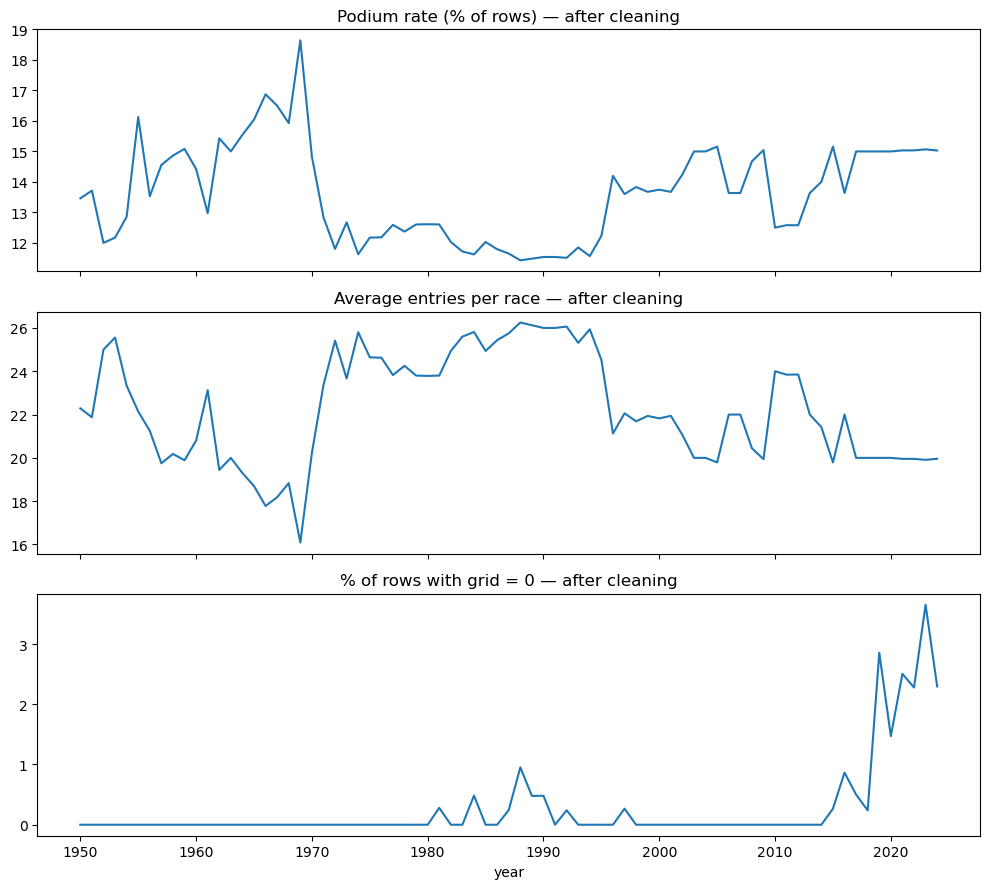

In [191]:
podium_rate = res_clean.groupby("year")["podium"].mean() * 100
field_size  = res_clean.groupby(["year", "raceId"]).size().groupby("year").mean()
grid_zero   = (res_clean["grid"] == 0).groupby(res_clean["year"]).mean() * 100

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
podium_rate.plot(ax=axes[0], title="Podium rate (% of rows) — after cleaning")
field_size.plot(ax=axes[1], title="Average entries per race — after cleaning")
grid_zero.plot(ax=axes[2], title="% of rows with grid = 0 — after cleaning")
plt.tight_layout(); plt.show()

### before vs after podium rate overlay

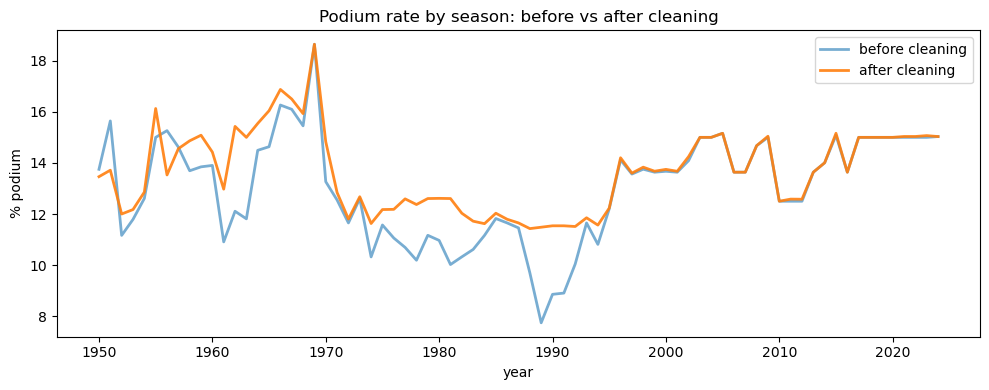

In [192]:
raw_rate = res_raw.groupby("year")["podium"].mean() * 100
cln_rate = res_clean.groupby("year")["podium"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4))
raw_rate.plot(ax=ax, label="before cleaning", alpha=0.6, linewidth=2)
cln_rate.plot(ax=ax, label="after cleaning",  alpha=0.9, linewidth=2)
ax.set_title("Podium rate by season: before vs after cleaning")
ax.set_ylabel("% podium")
ax.legend()
plt.tight_layout(); plt.show()

**Observation.** Cleaning removes 6.13% of rows (1,639 rows), concentrated in two historical patterns: shared drives in the 1950s–70s and DNQ rows in the 1977–92 oversubscribed-entry era (see Section 6 for the full breakdown).

**Why it matters.** Our train/val/test split is ≤2019 / 2020–21 / ≥2022. Cleaning removes only 13 rows from 2003 onward (1,639 in total), so the modern part of the modeling table is essentially untouched. The base-rate shift is the only material change.

## 6. Data analysis: impact of cleaning

This section quantifies what cleaning changed. The table below is the source of
truth for the report's "impact of cleaning" claim.

### impact table

In [193]:
impact = pd.DataFrame([
    {"metric": "rows in results",
     "before": before_rows, "after": after_rows,
     "delta": after_rows - before_rows},
    {"metric": "duplicated (raceId, driverId) pairs",
     "before": 85, "after": 0, "delta": -85},
    {"metric": "non-starter rows (grid=0, F/W)",
     "before": N_NON_STARTERS, "after": 0, "delta": -N_NON_STARTERS},
    {"metric": "podium base rate (%)",
     "before": round(before_rate, 2), "after": round(after_rate, 2),
     "delta": round(after_rate - before_rate, 2)},
])
display(impact)

,metric,before,after,delta
0,rows in results,26759.00,25120.00,-1639.00
1,"duplicated (raceId, driverId) pairs",85.00,0.00,-85.00
2,"non-starter rows (grid=0, F/W)",1548.00,0.00,-1548.00
3,podium base rate (%),12.69,13.45,0.75


### where the drop happens

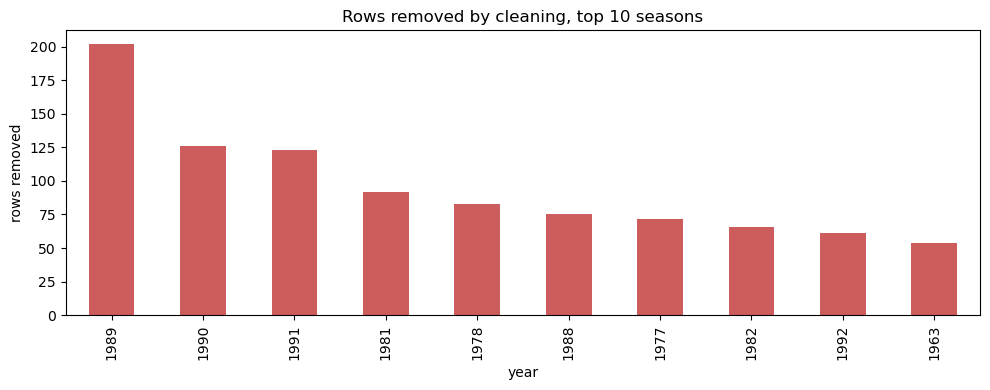

In [194]:
raw_by_year = res_raw.groupby("year").size()
cln_by_year = res_clean.groupby("year").size()
lost = (raw_by_year - cln_by_year).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 4))
lost.plot(kind="bar", ax=ax, color="indianred")
ax.set_title("Rows removed by cleaning, top 10 seasons")
ax.set_ylabel("rows removed")
plt.tight_layout(); plt.show()

**Observation.** Cleaning removes 1,639 rows (6.13%). The removals fall into two
distinct historical patterns:

- **1950s–1970s — shared drives.** 91 duplicate `(raceId, driverId)` rows,
  resolved by the Rule A tiebreak (Section 3.3).
- **1977–1992 — oversubscribed entries.** The single largest season drop is
  1989 with 202 rows removed. Diagnostic check: all 202 have
  `positionText = 'F'` and `grid = 0` — they are DNQ (Did Not Qualify) rows
  from eras where pre-qualifying was needed because more cars entered than
  the grid could hold.

**Why it matters.** Non-starters (DNQ, withdrawn) never had a podium chance, so
including them would artificially depress the base rate in large-field eras.
Removing them makes the podium rate comparable across eras. **No post 1992 season
appears in the top 10**, only 13 rows total are removed in the 2003+ window, so the modern modeling table is untouched by cleaning

**Decision.** Proceed to Section 7 (modeling-table construction) with `c["results"]`
as the base table.

## 7. Build and export the modeling base table

Sections 0–6 built a cleaned, verified, era-aware view of the raw F1 tables.
Section 7 combines them into a single modeling table at `(raceId, driverId)` grain
with a target column (`podium`) and a set of pre-race features that are all
available at the prediction cutoff (after qualifying, before the race start).

**Leakage-safe design.** Every feature is either:
- Static (circuit, driver, constructor attributes known before the race), or
- A **shifted** historical aggregate: rolling driver/constructor form, and
  standings going *into* the race, both computed only from races strictly earlier
  than the current one.

**Target column.** `podium = 1 if positionOrder <= 3 else 0`. This is the only
column in the final table that uses post-race information.

### 7.1 Base frame: one row per (raceId, driverId)

We start from the cleaned `c["results"]` and join:
- `races` (for year, round, date, circuitId)
- `circuits` (for circuit country, name)
- `drivers` (for driver nationality, name)
- `constructors` (for constructor name, nationality)

After this section, the frame has one row per race entry with all static
attributes attached.

In [195]:
# 7.1a: pick the columns we need from each table (avoid carrying unnecessary text)
races_cols = ["raceId", "year", "round", "circuitId", "date"]
circ_cols  = ["circuitId", "name", "country"]
drv_cols   = ["driverId", "forename", "surname", "nationality"]
con_cols   = ["constructorId", "name", "nationality"]

# Rename to keep the join readable
races_s = c["races"][races_cols].rename(columns={"name": "race_name"})
circ_s  = c["circuits"][circ_cols].rename(columns={"name": "circuit_name",
                                                    "country": "circuit_country"})
circ_s["circuit_country"] = circ_s["circuit_country"].replace({"United States": "USA"})
drv_s   = c["drivers"][drv_cols].rename(columns={"nationality": "driver_nationality"})
con_s   = c["constructors"][con_cols].rename(columns={"name": "constructor_name",
                                                      "nationality": "constructor_nationality"})

# Build the base frame
base = (c["results"]
        .merge(races_s, on="raceId", how="left", validate="m:1")
        .merge(circ_s,  on="circuitId", how="left", validate="m:1")
        .merge(drv_s,   on="driverId", how="left", validate="m:1")
        .merge(con_s,   on="constructorId", how="left", validate="m:1"))

# Sanity checks
assert base.duplicated(["raceId", "driverId"]).sum() == 0, "grain broken at 7.1"
assert base["year"].notna().all(), "some rows lost year after join"
print("base shape:", base.shape)
print("columns:", list(base.columns))
print("year range:", base["year"].min(), "-", base["year"].max())

base shape: (25120, 19)
columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'positionOrder', 'statusId', 'year', 'round', 'circuitId', 'date', 'circuit_name', 'circuit_country', 'forename', 'surname', 'driver_nationality', 'constructor_name', 'constructor_nationality']
year range: 1950 - 2024


### 7.2 Qualifying features

`has_quali` lets the model learn separately from rows with vs without qualifying
data, so the pre-2003 rows (mostly `has_quali=0`) don't distort the modern ones.

**Coverage by era.**

| Era | has_quali = 0 | has_quali = 1 |
|---|---|---|
| pre-2003 | 90.4% | 9.6% |
| 2003+ | 0.2% | 99.8% |

22 rows from 2003 onward have no qualifying row. 21 start from ordinary back-of-grid slots (19-24), one has grid = 0, and none finished on the podium. We have not investigated why the row is missing; `has_quali` flags them.

In [196]:
# Select qualifying columns
quali_s = c["qualifying"][["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]].copy()
quali_s = quali_s.rename(columns={"position": "quali_position"})

# Merge onto base (left join so all race entries are kept)
base = base.merge(quali_s, on=["raceId", "driverId"], how="left", validate="1:1")

# Explicit missing indicator
base["has_quali"] = base["quali_position"].notna().astype(int)

# Sanity
print("has_quali coverage by era:")
era = np.where(base["year"] < 2003, "pre-2003", "2003+")
print(pd.crosstab(era, base["has_quali"], normalize="index").round(3))
print()
print("quali_position nulls:", base["quali_position"].isna().sum())
print("q1_sec nulls:", base["q1_sec"].isna().sum())

has_quali coverage by era:
has_quali      0      1
row_0                  
2003+      0.002  0.998
pre-2003   0.904  0.096

quali_position nulls: 14641
q1_sec nulls: 14797


### 7.3 Pre-race standings (shifted)

`driver_standings` and `constructor_standings` store standings **after** each
race. To get standings going into race *N*, we need race *N-1*'s values. We
achieve this with `groupby([id, year]).shift(1)` after sorting by date, so the
shift `resets at the start of each season` a driver's round 1 standing are `NaN`
by design.

If a driver's first race of the season has no prior standing, `shift` produces
`NaN` — that's correct: at round 1 nobody has standings yet. The model can
learn from that absence via a missing indicator if needed.

**Merge grain note.** `(raceId, driverId)` is unique in `base` — that's our
target grain — so the driver-standings merge is `1:1`. But
`(raceId, constructorId)` is **not** unique in `base`: every constructor fields
two cars, so two rows share the same `(raceId, constructorId)`. The
constructor-standings merge is therefore `m:1` (many `base` rows to one
constructor-standing row). The same rule applies when joining `races` to each
standings table inside the shift step.

**Null fraction by design.** The two standing columns are null for 13.2% of rows (3,310 driver, 3,313 constructor): the first race of each driver's or constructor's season, when no ranking exists yet. 742 of the driver nulls are career debuts. 1,454 constructor nulls are pre-1958 rows, because the Constructors' Championship starts in 1958. Points and wins are 0 at a season's first race, so the driver versions have no nulls and the constructor versions are null (5.8%) only for those 1,454 pre-1958 rows. Each value comes from the entity's last earlier race in the same season, so it doesn't depend on whether the current race has a standings row.

**Idempotency note.** Because this cell merges into `base` in place, re-running
it without a reset produces `_x`/`_y` suffix columns from pandas' name
collision resolution. The cell drops any pre-existing `_before` columns at the
top so it is safe to re-run. A full `Restart & Run All` before submission also
avoids the issue entirely.

**Coverage vs. the cleaned base.** `shift(1)` runs on the *un-filtered*
`driver_standings` table, which may contain rows for races that our Section 3
cleaning removed from `base` (non-starters, DNQ rows, or shared-drive
duplicates). This is deliberate: filtering first would produce spurious nulls
for drivers who had legitimate prior championship standings. The consequence,
verified in Section 7.8, is that 52 of the 794 "debut-in-base" drivers still get a
non-null `driver_standing_before` — which is semantically correct.

In [197]:
# --- 0. Clean leftover columns from a previous run of this cell ---
stale = [col for col in base.columns if col.endswith("_before")]
if stale:
    base = base.drop(columns=stale)

races_dy = c["races"][["raceId", "date", "year"]]

def add_prior_standings(base, st, id_col, label, first_year):
    """For each base row: the entity's LAST standings row from an EARLIER race of the SAME season.
    Does not depend on whether a standings row exists for the current race."""
    st = (st[["raceId", id_col, "points", "position", "wins"]]
          .merge(races_dy, on="raceId", how="left", validate="m:1")
          .rename(columns={"date": "st_date",
                           "points":   f"{label}_points_before",
                           "position": f"{label}_standing_before",
                           "wins":     f"{label}_wins_before"})
          .drop(columns="raceId")
          .sort_values("st_date"))
    keys = (base[["raceId", id_col, "year"]]
            .drop_duplicates(["raceId", id_col])
            .merge(races_dy[["raceId", "date"]], on="raceId", validate="m:1")
            .sort_values("date"))
    out = pd.merge_asof(keys, st, left_on="date", right_on="st_date",
                        by=[id_col, "year"], allow_exact_matches=False, direction="backward")
    pts, wins = f"{label}_points_before", f"{label}_wins_before"
    # first race of a season: the championship starts at 0 points / 0 wins
    # (only if that championship existed that year; rank stays NaN)
    exists = out["year"] >= first_year
    out.loc[exists, [pts, wins]] = out.loc[exists, [pts, wins]].fillna(0)
    return out[["raceId", id_col, pts, f"{label}_standing_before", wins]]

ds_shifted = add_prior_standings(base, c["driver_standings"],      "driverId",      "driver",      1950)
cs_shifted = add_prior_standings(base, c["constructor_standings"], "constructorId", "constructor", 1958)

# --- Merge onto base ---
base = base.merge(ds_shifted, on=["raceId", "driverId"],      how="left", validate="m:1")
base = base.merge(cs_shifted, on=["raceId", "constructorId"], how="left", validate="m:1")

# --- Sanity ---
r1 = base[base["round"] == 1]
assert (r1["driver_points_before"].dropna() == 0).all(), "round-1 driver points should be 0"
assert (r1["constructor_points_before"].dropna() == 0).all(), "round-1 constructor points should be 0"
print("driver_points_before nulls:", base["driver_points_before"].isna().sum())
print("constructor_points_before nulls:", base["constructor_points_before"].isna().sum(),
      "| pre-1958:", int((base["constructor_points_before"].isna() & (base["year"] < 1958)).sum()))
print("driver_standing_before nulls:", base["driver_standing_before"].isna().sum(),
      f"({base['driver_standing_before'].isna().mean():.1%})")
print("constructor_standing_before nulls:", base["constructor_standing_before"].isna().sum(),
      f"({base['constructor_standing_before'].isna().mean():.1%})")
print("base shape:", base.shape)

driver_points_before nulls: 0
constructor_points_before nulls: 1454 | pre-1958: 1454
driver_standing_before nulls: 3310 (13.2%)
constructor_standing_before nulls: 3313 (13.2%)
base shape: (25120, 30)


### 7.4 Leakage-safe rolling form features

For each driver (and each constructor), we compute a **rolling average of the
podium rate over their previous N races** — strictly earlier races, never
including the current one.

Two windows:
- **Short:** last 5 races — captures recent form.
- **Long:** last 20 races — captures longer-term skill.

Both are computed with `shift(1)` first so the current race's own podium value
is never included.

In [198]:
# Sort base chronologically (by date, then raceId to break ties)
base = base.sort_values(["date", "raceId"]).reset_index(drop=True)

# 7.4a: target column (needed for rolling computations)
base["podium"] = (base["positionOrder"] <= 3).astype(int)

# 7.4b: driver form (one row per driver per race, so shift(1) = previous race)
base["driver_form_5"] = (
    base.groupby("driverId")["podium"]
        .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
)
base["driver_form_20"] = (
    base.groupby("driverId")["podium"]
        .transform(lambda s: s.shift(1).rolling(20, min_periods=1).mean())
)

# 7.4c: constructor form, computed per constructor-RACE (both cars share one value)
base = base.drop(columns=["constructor_form_5", "constructor_form_20"], errors="ignore")
cr = (base.groupby(["constructorId", "raceId", "date"], as_index=False)["podium"].mean()
          .sort_values(["constructorId", "date", "raceId"]))
g = cr.groupby("constructorId")["podium"]
cr["constructor_form_5"]  = g.transform(lambda s: s.shift(1).rolling(5,  min_periods=1).mean())
cr["constructor_form_20"] = g.transform(lambda s: s.shift(1).rolling(20, min_periods=1).mean())
base = base.merge(cr[["constructorId", "raceId", "constructor_form_5", "constructor_form_20"]],
                  on=["constructorId", "raceId"], how="left", validate="m:1")
base = base.sort_values(["date", "raceId"]).reset_index(drop=True)

# 7.4d: driver race count entering this race
base["driver_races_prior"] = base.groupby("driverId").cumcount()

# Sanity
print("driver_form_5 nulls:", base["driver_form_5"].isna().sum(),
      f"({base['driver_form_5'].isna().mean():.1%})")
print("driver_form_5 mean:", round(base["driver_form_5"].mean(), 4))
print("constructor_form_5 nulls:", base["constructor_form_5"].isna().sum(),
      f"({base['constructor_form_5'].isna().mean():.1%})")
print("constructor_form_5 mean:", round(base["constructor_form_5"].mean(), 4))
print("base shape:", base.shape)

driver_form_5 nulls: 794 (3.2%)
driver_form_5 mean: 0.1371
constructor_form_5 nulls: 315 (1.3%)
constructor_form_5 mean: 0.1376
base shape: (25120, 36)


In [199]:
# 7.4e: independent leakage check - recompute form using ONLY strictly earlier race dates
def expected_form(r, id_col, n):
    earlier = base["date"] < r["date"]
    hist = (base.loc[(base[id_col] == r[id_col]) & earlier]
                .groupby("date")["podium"].mean().sort_index())
    return hist.tail(n).mean() if len(hist) else np.nan

rng = np.random.default_rng(SEED)
mismatch = 0
for i in rng.choice(len(base), size=300, replace=False):
    r = base.iloc[i]
    for id_col, col, n in [("driverId", "driver_form_5", 5), ("driverId", "driver_form_20", 20),
                           ("constructorId", "constructor_form_5", 5), ("constructorId", "constructor_form_20", 20)]:
        e, a = expected_form(r, id_col, n), r[col]
        if not (np.isclose(e, a) or (np.isnan(e) and np.isnan(a))):
            mismatch += 1
assert mismatch == 0, f"{mismatch} form values differ from a strictly-past recomputation"
print("form features match an independent strictly-past recomputation ✅")

form features match an independent strictly-past recomputation ✅


**Result.** After the shift-then-roll construction:

- `driver_form_5` is null for 3.2% of rows (794 rows) — these are drivers at
  their career debut in the dataset, where no prior race exists to roll over.
- The mean of `driver_form_5` is 0.137, close to the overall podium rate of
  0.135 (Section 5). This is the expected behavior: a properly constructed
  form feature has a mean near the base rate.
- `constructor_form_5` is null for 1.3% of rows (315 rows) and has mean 0.138.

**Why this design avoids leakage.** The `shift(1)` step removes the current
row's `podium` value from the window before the rolling mean is computed, so
`driver_form_5` at race *N* is a function of races strictly earlier than *N*.
This is verified by an explicit assertion in Section 7.4e and the  teammate check in section 7.8b.

### 7.5 Derived features and leakage cleanup

- **`pit_lane_start`** — 1 if `grid == 0` (kept rows only).
- **`is_home_race`** — 1 if the driver's nationality matches the circuit's country.
  We use a small mapping because nationality strings ("British") and country
  strings ("UK") don't always match directly.
- **`era`** — categorical flag for technical era (pre-2003 / 2003-2009 / 2010-2013 /
  2014-2021 / 2022+). Useful for diagnostics; will be one-hot encoded in modeling.
- **Dropped leakage/identifier columns:** `positionOrder`, `statusId`, `date`,
  `name`, `url`, raw first/last names, etc. Everything the model sees must be
  numeric or categorical-safe.

In [200]:
# 7.5a: pit-lane start flag (kept grid=0 rows only)
base["pit_lane_start"] = ((base["grid"] == 0) & (base["year"] >= 1994)).astype(int)

# 7.5b: home race flag
# Small mapping: driver nationality -> circuit country
# (Only the countries that ever hosted an F1 race + all driver nationalities in the data.)
NAT_TO_COUNTRY = {
    # British / UK
    "British": "UK",
    "Scottish": "UK",
    "Welsh": "UK",
    "Northern Irish": "UK",
    "English": "UK",
    # German
    "German": "Germany",
    "East German": "Germany",
    # Others identity-mapped
    "Italian": "Italy",
    "French": "France",
    "Spanish": "Spain",
    "Brazilian": "Brazil",
    "Mexican": "Mexico",
    "Canadian": "Canada",
    "American": "USA",
    "Argentine": "Argentina",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Belgian": "Belgium",
    "Dutch": "Netherlands",
    "Swiss": "Switzerland",
    "Swedish": "Sweden",
    "Finnish": "Finland",
    "Danish": "Denmark",
    "Portuguese": "Portugal",
    "Japanese": "Japan",
    "Chinese": "China",
    "Monégasque": "Monaco",
    "Monegasque": "Monaco",
    "Hungarian": "Hungary",
    "Polish": "Poland",
    "Russian": "Russia",
    "South African": "South Africa",
    "New Zealander": "New Zealand",
    "Irish": "Ireland",
    "Colombian": "Colombia",
    "Venezuelan": "Venezuela",
    "Chilean": "Chile",
    "Uruguayan": "Uruguay",
    "Malaysian": "Malaysia",
    "Singaporean": "Singapore",
    "Korean": "Korea",
    "Indian": "India",
    "Indonesian": "Indonesia",
    "Thai": "Thailand",
    "Emirati": "United Arab Emirates",
    "Saudi Arabian": "Saudi Arabia",
    "Azerbaijani": "Azerbaijan",
    "Turkish": "Turkey",
    "Czech": "Czech Republic",
    "Liechtensteiner": "Liechtenstein",
    "Rhodesian": "Rhodesia",
    "Moroccan": "Morocco",
    "Egyptian": "Egypt",
}
base["driver_nationality"] = (base["driver_nationality"].str.strip().replace({"Argentinian": "Argentine"}))
base["driver_country"] = base["driver_nationality"].map(NAT_TO_COUNTRY)
base["is_home_race"] = (base["driver_country"] == base["circuit_country"]).astype(int)

# 7.5c: era flag
def era_of(y):
    if y < 2003:   return "pre-2003"
    if y < 2010:   return "2003-2009"
    if y < 2014:   return "2010-2013"
    if y < 2022:   return "2014-2021"
    return "2022+"

base["era"] = base["year"].apply(era_of)

# 7.5d: drop everything not needed for modeling
drop_cols = [
    # identifiers we don't need (raceId/driverId/constructorId kept for grouping/joins)
    "race_name", "circuit_name", "forename", "surname",
    "driver_nationality", "constructor_nationality",
    "driver_country",
    # post-race and target-adjacent
    "positionOrder", "statusId",
    # helpers
    "date",
]
present_drop = [col for col in drop_cols if col in base.columns]
base = base.drop(columns=present_drop)

# Sanity
print("is_home_race rate:", round(base["is_home_race"].mean(), 4))
print("pit_lane_start rate:", round(base["pit_lane_start"].mean(), 4))
print("era counts:")
print(base["era"].value_counts().sort_index())
print()
print("base shape:", base.shape)
print("columns:", list(base.columns))

is_home_race rate: 0.0926
pit_lane_start rate: 0.0029
era counts:
era
2003-2009     2533
2010-2013     1804
2014-2021     3264
2022+         1356
pre-2003     16163
Name: count, dtype: int64

base shape: (25120, 31)
columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'year', 'round', 'circuitId', 'circuit_country', 'constructor_name', 'quali_position', 'q1_sec', 'q2_sec', 'q3_sec', 'has_quali', 'driver_points_before', 'driver_standing_before', 'driver_wins_before', 'constructor_points_before', 'constructor_standing_before', 'constructor_wins_before', 'podium', 'driver_form_5', 'driver_form_20', 'constructor_form_5', 'constructor_form_20', 'driver_races_prior', 'pit_lane_start', 'is_home_race', 'era']


**Result.**

- `is_home_race` fires for 9.3% of rows — a plausible rate given most drivers
  race abroad.
- `pit_lane_start` fires for 0.29% (74 rows). It requires `grid = 0` and year ≥ 1994, so the other 13 `grid = 0` rows (pre-1994 D/E/R) are not flagged
- `number` has no nulls. Its correlation with the target is 0.105 overall but 0.034 for 2003+, so it is probably an era effect and goes into the ablation.
- Era distribution: pre-2003 is 64% of the modeling table because early F1 had
  larger fields; the modern eras together account for 36%.

**Columns retained.** Identifiers needed for joins/grouping (`raceId`,
`driverId`, `constructorId`, `circuitId`), all pre-race features, the target
(`podium`), and `era` as a categorical flag.

**Nulls remaining.**  `quali_position`, `q1_sec`, `q2_sec`, `q3_sec`,
, the four `*_before` standings columns, and the four form columns still contain nulls. These are all
structurally missing (career debut, pre-qualifying-data era, or no q2/q3
session), not errors. Section 8 (data contract) records how each will be
handled at model time.

### 7.6 Final schema audit

Before saving, we check:
- The grain is still unique on `(raceId, driverId)`.
- Dtypes are sensible (no `object` columns except `era`).
- The target has the expected distribution.
- No feature has suspiciously high correlation with the target beyond what physics suggests.

In [201]:
# 7.6a: grain
assert base.duplicated(["raceId", "driverId"]).sum() == 0, "grain broken at 7.6"

# 7.6b: dtypes
print("dtypes:")
print(base.dtypes)
print()

# 7.6c: target distribution
print("target distribution:")
print(base["podium"].value_counts(normalize=True).round(4))
print()

# 7.6d: correlation of numeric features with podium
numeric_cols = base.select_dtypes(include=["int64", "float64", "Int64"]).columns
corrs = base[numeric_cols].corrwith(base["podium"]).abs().sort_values(ascending=False)
print("top 15 |correlation| with podium:")
print(corrs.head(15).round(3))

dtypes:
resultId                         int64
raceId                           int64
driverId                         int64
constructorId                    int64
number                           Int64
grid                             int64
year                             int64
round                            int64
circuitId                        int64
circuit_country                 object
constructor_name                object
quali_position                 float64
q1_sec                         float64
q2_sec                         float64
q3_sec                         float64
has_quali                        int64
driver_points_before           float64
driver_standing_before         float64
driver_wins_before             float64
constructor_points_before      float64
constructor_standing_before    float64
constructor_wins_before        float64
podium                           int64
driver_form_5                  float64
driver_form_20                 float64
constructor_form_

**Why both `quali_position` and `grid` are kept.** They are highly correlated
(0.95) but not identical: grid differs from qualifying when the driver has a
grid penalty or starts from the pit lane. The pair captures "quali pace" and
"actual starting slot" separately, which is exactly the distinction the brief
calls out in data-engineering question 1.

**Result.**

- **Dtypes.** All numeric, except `circuit_country`, `constructor_name`, and
  `era`, which are categorical strings that will be one-hot or target-encoded
  at modeling time.
- **Target.** `podium = 1` for 13.45% of rows — matching the Section 5 base
  rate after cleaning.
- **Correlations with the target.** On rows with qualifying data, the form features lead (0.53-0.55), then `quali_position` (0.49) and `grid` (0.47). Standings sit at 0.38-0.45 and experience at 0.17. The earlier all-rows figures compared different row sets.

**Leakage is checked directly:** Section 7.4e recomputes all four form columns from strictly earlier races, and Section 7.8b checks that teammates share one constructor form.

In [202]:
  sub = base[base.has_quali == 1]
  print(sub[numeric_cols].corrwith(sub["podium"]).abs().sort_values(ascending=False).round(3).head(15))

podium                         1.000
driver_form_20                 0.548
constructor_form_20            0.535
constructor_form_5             0.535
driver_form_5                  0.532
quali_position                 0.487
grid                           0.474
driver_standing_before         0.447
constructor_standing_before    0.437
constructor_wins_before        0.427
driver_wins_before             0.417
driver_points_before           0.403
constructor_points_before      0.382
driver_races_prior             0.172
driverId                       0.115
dtype: float64


c:\Users\malik\Documents\1 Uni\SEM 9\AML\aml_workspace\.conda\lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\malik\Documents\1 Uni\SEM 9\AML\aml_workspace\.conda\lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


### 7.7 Save the modeling base table

We save to `../data/processed/modeling_base.parquet` (Parquet preserves dtypes;
CSV fallback if pyarrow isn't installed).

In [203]:
from pathlib import Path

OUT_DIR = Path("../data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# OUT_DIR = Path("/kaggle/working") if Path("/kaggle").exists() else Path("../data/processed")
# OUT_DIR.mkdir(parents=True, exist_ok=True)

try:
    base.to_parquet(OUT_DIR / "modeling_base.parquet", index=False)
    print("saved:", (OUT_DIR / "modeling_base.parquet").resolve())
except Exception as e:
    print("parquet failed:", e)
    base.to_csv(OUT_DIR / "modeling_base.csv", index=False)
    print("saved CSV fallback:", (OUT_DIR / "modeling_base.csv").resolve())

print("rows:", len(base), "| cols:", base.shape[1])

# Preview the saved modeling table
display(base.head())
print()
print("Shape:", base.shape)
print("Dtypes:")
display(base.dtypes.to_frame("dtype"))

saved: C:\Users\malik\Documents\1 Uni\SEM 9\AML\project\the_project\f1-podium-ms1\data\processed\modeling_base.parquet
rows: 25120 | cols: 31


,resultId,raceId,driverId,constructorId,number,grid,year,round,circuitId,circuit_country,...,constructor_wins_before,podium,driver_form_5,driver_form_20,constructor_form_5,constructor_form_20,driver_races_prior,pit_lane_start,is_home_race,era
0,20036,833,579,51,1,3,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,0,pre-2003
1,20042,833,589,105,19,11,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,0,pre-2003
2,20030,833,619,151,12,13,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,1,pre-2003
3,20029,833,627,154,15,9,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,0,pre-2003
4,20041,833,640,105,20,8,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,0,pre-2003



Shape: (25120, 31)
Dtypes:


,dtype
resultId,int64
raceId,int64
driverId,int64
constructorId,int64
number,Int64
grid,int64
year,int64
round,int64
circuitId,int64
circuit_country,object


In [204]:
%pip install fastparquet

Note: you may need to restart the kernel to use updated packages.


In [205]:
import pandas as pd, numpy as np
df = pd.read_parquet("../data/processed/modeling_base.parquet", engine="fastparquet")
# --- STRUCTURE ---
assert df.shape == (25120, 31), f"shape changed: {df.shape}"
assert df.duplicated(["raceId", "driverId"]).sum() == 0, "grain broken"
assert df["year"].between(1950, 2024).all(), "year out of range"
print("✅ shape, grain, year range")

# --- TARGET ---
assert set(df["podium"].unique()) == {0, 1}, "target not binary"
assert 0.10 < df["podium"].mean() < 0.16, "base rate off"
print(f"✅ target binary, base rate = {df['podium'].mean():.4f}")

# --- LEAKAGE COLUMNS (post-race info only; ID columns are allowed) ---
banned = ["positionOrder","statusId","position","positionText","points",
          "laps","time","milliseconds","fastestLap","fastestLapSpeed",
          "fastestLapTime","rank"]
present = [c for c in banned if c in df.columns]
assert not present, f"leakage present: {present}"
print("✅ no post-race / leakage columns")

# --- ID COLUMNS STILL PRESENT (needed for grouping, not for the model) ---
for idcol in ["resultId","raceId","driverId","constructorId","circuitId"]:
    assert idcol in df.columns, f"missing id column: {idcol}"
print("✅ all id columns present")

# --- FEATURE RANGES ---
for c in ["driver_form_5","driver_form_20","constructor_form_5","constructor_form_20"]:
    s = df[c].dropna()
    assert s.between(0, 1).all(), f"{c} out of [0,1]"
assert (df["grid"] >= 0).all()
assert (df["driver_races_prior"] >= 0).all()
assert (df["is_home_race"].isin([0,1])).all()
assert (df["pit_lane_start"].isin([0,1])).all()
print("✅ feature ranges")

# --- ERA VALUES ---
expected_eras = {"pre-2003","2003-2009","2010-2013","2014-2021","2022+"}
assert set(df["era"].unique()) == expected_eras, f"unexpected eras: {set(df['era'].unique())}"
print("✅ era labels")

# --- TEAMMATE CONSISTENCY ---
chk = df.groupby(["constructorId","raceId"])["constructor_form_5"].nunique(dropna=False)
assert (chk == 1).all(), "teammates disagree on constructor_form_5"
print("✅ teammates share constructor form")

# --- STANDINGS SHIFT ---
r1 = df[df["round"] == 1]
assert (r1["driver_points_before"].dropna() == 0).all()
assert (r1["constructor_points_before"].dropna() == 0).all()
print("✅ round-1 standings reset to 0")

print("\n🎉 Table is correct.")

✅ shape, grain, year range
✅ target binary, base rate = 0.1345
✅ no post-race / leakage columns
✅ all id columns present
✅ feature ranges
✅ era labels
✅ teammates share constructor form
✅ round-1 standings reset to 0

🎉 Table is correct.


### 7.8 Leakage audit

Final checks that the table is safe to model on:

1. **No post-race columns survived.** `positionOrder`, `statusId`, `points`,
   `laps`, `time*`, `fastestLap*` must all be absent.
2. **Form features use only past races.** For each driver, `driver_form_5` at
   race *N* is the mean of their podium values at races strictly before *N*.
3. **Standings are shifted.** `driver_standing_before` at race *N* equals the
   post-race standing at their previous race, not the current one.

Check 1 is a column-name check. Check 2 is verified by construction (shift before
rolling). Check 3 is verified by construction (groupby-shift in 7.3).

In [206]:
# 7.8a: no post-race columns survived
banned = ["positionOrder", "statusId", "position", "positionText",
          "points", "laps", "time", "milliseconds",
          "fastestLap", "fastestLapSpeed", "fastestLapTime", "rank"]
survived = [c for c in banned if c in base.columns]
assert not survived, f"post-race columns survived: {survived}"
print("no post-race columns in base ✅")

# 7.8b: teammates in the same race must share the same constructor form
assert (base.groupby(["constructorId", "raceId"])["constructor_form_5"]
            .nunique(dropna=False) == 1).all(), "constructor form differs between cars of one race"
print("constructor form identical for both cars of each race ✅ (strict-past check is in 7.4e)")

# 7.8c: standings shift sanity
first_race_mask = base.groupby("driverId").cumcount() == 0
n_first_races = first_race_mask.sum()
n_null_before_first = base.loc[first_race_mask, "driver_standing_before"].isna().sum()
print(f"drivers' first races: {n_first_races}; "
      f"with null standing_before: {n_null_before_first} "
      f"({n_null_before_first / n_first_races:.1%})")
print(f"first-race rows that already have a standing_before: {n_first_races - n_null_before_first}")

# 7.8d: null audit for the remaining columns
print()
print("null fraction by column (only non-zero):")
nulls = base.isna().mean().round(4) * 100
print(nulls[nulls > 0].sort_values(ascending=False))

no post-race columns in base ✅
constructor form identical for both cars of each race ✅ (strict-past check is in 7.4e)
drivers' first races: 794; with null standing_before: 742 (93.5%)
first-race rows that already have a standing_before: 52

null fraction by column (only non-zero):
q3_sec                         85.56
q2_sec                         76.74
q1_sec                         58.91
quali_position                 58.28
constructor_standing_before    13.19
driver_standing_before         13.18
constructor_points_before       5.79
constructor_wins_before         5.79
driver_form_5                   3.16
driver_form_20                  3.16
constructor_form_5              1.25
constructor_form_20             1.25
dtype: float64


Of the 794 drivers' first rows, 742 (93.5%) have `driver_standing_before = NaN`, as expected for a debut. The other 52 have an earlier same-season standings row for a race that was removed from the cleaned results. In all 52 cases it is a non-starter row (F or W) removed in Section 3.4. Each value is the driver's last standings row from an earlier race of the same season, so it never depends on the current race.

In [207]:
split = np.select([base.year <= 2019, base.year <= 2021], ["train", "val"], default="test")
print(pd.Series(split).value_counts())
print("q2 nulls:", int(base.q2_sec.isna().sum()), "| q3 nulls:", int(base.q3_sec.isna().sum()))
print("number nulls:", int(base["number"].isna().sum()))
print("constructor_standing_before nulls:", int(base.constructor_standing_before.isna().sum()),
      "| of which year < 1958:", int((base.constructor_standing_before.isna() & (base.year < 1958)).sum()))
print("quali_position vs grid corr:", round(base[["grid", "quali_position"]].corr().iloc[0, 1], 3))
rem = raw_by_year.sub(cln_by_year, fill_value=0)
print("rows removed in 2003+:", int(rem[rem.index >= 2003].sum()), "| removed in 1989:", int(rem.loc[1989]))
r = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
x = r[(r.year == 1989) & (r.grid == 0) & r.positionText.isin(["F", "W"])]
print("1989 grid=0 F/W rows:", len(x), x.positionText.value_counts().to_dict())
for name, d in [("before", res_raw), ("after", res_clean)]:
    print(name, "podium rate 2003+:", round(d.loc[d.year >= 2003, "podium"].mean() * 100, 2))

train    22985
test      1356
val        779
Name: count, dtype: int64
q2 nulls: 19278 | q3 nulls: 21493
number nulls: 0
constructor_standing_before nulls: 3313 | of which year < 1958: 1454
quali_position vs grid corr: 0.95
rows removed in 2003+: 13 | removed in 1989: 202
1989 grid=0 F/W rows: 202 {'F': 202}
before podium rate 2003+: 14.31
after podium rate 2003+: 14.34


## 8. Data contract and decisions

This section is the formal handoff. It documents the modeling table schema,
the leakage boundaries, the null-handling policy, the train/val/test split, and
every cleaning decision made in Sections 2–7, so that modeling code can be
written against a stable contract.

### 8.1 Modeling table schema

- **File:** `data/processed/modeling_base.parquet`
- **Grain:** one row per `(raceId, driverId)` — verified by assertion in Section 7.6a
- **Rows:** 25,120 | **Columns:** 31

| Column | Dtype | Role | Nulls | Notes |
|---|---|---|---|---|
| `resultId` | int64 | id | 0% | unique row id (not a feature) |
| `raceId` | int64 | id | 0% | FK to races (used for grouping, not a feature) |
| `driverId` | int64 | id | 0% | FK to drivers (used for grouping, not a feature) |
| `constructorId` | int64 | id | 0% | FK to constructors (used for grouping, not a feature) |
| `circuitId` | int64 | id | 0% | FK to circuits |
| `year` | int64 | split | 0% | used for temporal train/val/test split |
| `round` | int64 | feature | 0% | race number in season |
| `grid` | int64 | feature | 0% | starting slot; 0 = pit lane start from 1994; 13 older D/E/R rows also have 0|
| `number` | Int64 | feature | 0% | car number (no nulls) |
| `quali_position` | float64 | feature | 58.3% | null pre-2003 |
| `q1_sec` | float64 | feature | 58.9% | null when Q1 not run |
| `q2_sec` | float64 | feature | 76.7% | null when Q2 not run (knocked out in Q1) |
| `q3_sec` | float64 | feature | 85.6% | null when Q3 not run (knocked out in Q2) |
| `has_quali` | int64 | feature | 0% | missing indicator for qualifying data |
| `driver_points_before` | float64 | feature | 0% | shifted standings (before current race) |
| `driver_standing_before` | float64 | feature | 13.2% | shifted standings |
| `driver_wins_before` | float64 | feature | 0% | shifted standings |
| `constructor_points_before` | float64 | feature | 5.8% | shifted standings |
| `constructor_standing_before` | float64 | feature | 13.2% | shifted standings |
| `constructor_wins_before` | float64 | feature | 5.8% | shifted standings |
| `driver_form_5` | float64 | feature | 3.2% | rolling podium rate, last 5 races (shifted) |
| `driver_form_20` | float64 | feature | 3.2% | rolling podium rate, last 20 races (shifted) |
| `constructor_form_5` | float64 | feature | 1.3% | rolling podium rate, last 5 races (shifted) |
| `constructor_form_20` | float64 | feature | 1.3% | rolling podium rate, last 20 races (shifted) |
| `driver_races_prior` | int64 | feature | 0% | career starts before this race |
| `pit_lane_start` | int64 | feature | 0% | 1 if grid == 0 and year >= 1994(74 rows)|
| `is_home_race` | int64 | feature | 0% | 1 if driver nationality matches circuit country |
| `circuit_country` | str | feature | 0% | categorical |
| `constructor_name` | str | feature | 0% | categorical |
| `era` | str | feature | 0% | categorical era label |
| **`podium`** | int64 | **target** | 0% | **1 if positionOrder ≤ 3** |

`driver_points_before` / `driver_wins_before` / `constructor_points_before` / `constructor_wins_before` are filled with 0 at Round 1 (championship starts at 0). `driver_standing_before` / `constructor_standing_before` are **not** filled — they remain `NaN` at a driver's or constructor's first race of the season. That is why the standing columns have more nulls than the points/wins columns

### 8.2 Leakage boundaries

**Allowed at the prediction cutoff (after qualifying, before race start):**
- Grid position, qualifying position, qualifying lap times
- Any historical aggregate computed with `shift(1)` — form and standings
- Static attributes: circuit country, constructor name, era label
- Derived flags: `pit_lane_start`, `is_home_race`, `has_quali`, `driver_races_prior`

**Not allowed (post-race, would be leakage):**
- `positionOrder`, `positionText`, `position` — target leaks
- `statusId`, `laps`, `time`, `milliseconds`, `fastestLap*` — post-race
- Any standings value for the current race — only shifted ("_before") values are used
- `points`, `podium` itself — the target

**Verification:** 7.8a asserts no banned columns are present. 7.4e recomputes all four form features from strictly earlier races on 300 random rows. 7.8b asserts both cars of a race share the same constructor form.


### 8.3 Null-handling policy

Nulls are **structural**, not errors. Each pattern has a documented cause:

| Null pattern | Count | Semantics | Model-time handling |
|---|---|---|---|
| Pre-2003 qualifying columns | ~14,600 rows | Data doesn't exist for those years | Use `has_quali=0`; impute nothing; tree models handle natively |
| q2 / q3 not run | ~19,300 / ~21,500 rows | Format-dependent (knockout) | Leave null; `era` captures the format regime |
| Driver debut in base | 794 rows | No prior F1 race | Leave null; tree models handle natively |
| Constructor debut in base | 315 rows | No prior F1 race | Leave null; tree models handle natively |
| Driver standings at season start| 3,310 | `groupby([id, year]).shift(1)` resets at R1| Leave null for trees; sentinel for linear|
| Constructor standings pre-1958 / season start| 3,313 rows (1,454 pre-1958) | No Constructors' Championship before 1958, plus per-season reset| Leave null for trees; sentinel for linear |
|constructor_points/wins_before | 1,454 | pre-1958, no Constructors' Championship | leave null.|

**For linear models** (e.g., logistic regression): impute `driver_form_*` and standings nulls with a sentinel (worst-case value, e.g., 0 for form or max for standing), and add missing indicators. **For tree-based models**: leave nulls untouched.

### 8.4 Train / validation / test split

**Temporal split** — deliberately not random, to prevent leakage from future races:

| Split | Years | Rows | Purpose |
|---|---|---|---|
| Train | ≤ 2019 | 22,985 | Model fitting |
| Validation | 2020–2021 | 779 | Hyperparameter tuning, threshold selection |
| Test | ≥ 2022 | 1,356 | Final evaluation, **never seen during training** |

**Why temporal?** Random splitting would allow the model to see races from the same season as validation/test rows, which is unrealistic: at prediction time we only know the past. It would also leak constructor mid-season development trends.

**Hyperparameter and threshold policy:** All hyperparameters and the F1 decision threshold are selected using **training + validation only**. The test set is touched exactly once, at the end, for final reporting (Sections 4–6 of the modeling notebook).


### 8.5 Cleaning decisions log

Every cleaning step is traceable to a notebook cell:

| Step | Decision | Justification | Cell |
|---|---|---|---|
| Sentinel `\N` | Replaced with NaN | Standard placeholder in this dataset | 3.1 |
| Empty strings in q1/q2/q3 | Replaced with NaN | Same semantics as `\N` | 3.1 |
| Date strings | Parsed to datetime64 | Enables chronological sorting for shift | 3.1 |
| Lap-time strings | Parsed to numeric seconds | Numeric use in modeling | 3.1 |
| Practically-empty columns | Dropped (Group 1) | >88% missing, no signal for pre-race model | 3.2 |
| Post-race columns | Dropped (Group 2) | Leakage at the pre-race cutoff | 3.2 |
| `statusId` | Retained for Q3, then dropped from modeling | Needed for the mechanical-retirement analysis only | 3.2, 3.6, 7.5 |
| Duplicate `(raceId, driverId)` | Rule A: prefer started car, then lowest grid, then lowest `resultId` | Uses only pre-race info; alternative ("best positionOrder") rejected because it selects using the target | 3.3 |
| Non-starters (grid=0, positionText in {F,W}) | Excluded (1,548 rows) | No podium chance; including them artificially depresses the base rate | 3.4 |
| Form features | `shift(1)` before rolling mean | Excludes the current race's target from its own window | 7.4 |
| Constructor form features | Aggregate to `(constructorId, raceId)` before rolling | Teammates share one constructor value; rolling on the raw base would leak the current race | 7.4 |
| Standings | `shift(1)` by date, per driver/constructor | last earlier same-season standings row; 0 at season start | 7.3 |

### 8.6 Known limitations

1. **Shared-drive heuristic (Section 2c).** Rule A cannot identify which car was the driver's own in a shared drive. Among the 85 duplicated groups, 21 disagreed on podium label, and the alternative rule would flip 17 of them. All affected races fall between 1950 and 1978 — inside the ≤2019 training window. If the team ever trains on a 2003+ subset, the heuristic is irrelevant, but on the current ≤2019 train split these 21 groups are present.

2. **Qualifying coverage drift (Section 2d).** No qualifying data before 1994, patchy until 2003 (~100% from 2003 onward). The `has_quali` flag lets the model learn from the absence, but any standalone analysis of qualifying pace should restrict to 2003+.

3. **Constructor name changes reset form.** A rename (Toleman → Benetton → Renault → Alpine) is a new `constructorId`, so historical form doesn't carry across. The model sees this as a "new team."

4. **Indianapolis 500 (1950–1960).** Included in the raw data; the modern training window (2003+) is unaffected, so we keep it for completeness but flag it as a historical artifact.

5. **Non-starter exclusion changes the base rate.** Cleaning raises the podium base rate from 12.69% to 13.45%. The change is concentrated pre-1994; the modern-era (2003+) rate is stable at ~14.3% before and after cleaning.

6. **Era sensitivity.** The ground-effect era (2022+) has a different competitive balance (Red Bull then McLaren dominant). A model trained on 2003–2019 may under-fit the 2022+ era; the temporal test split at 2022+ measures this directly.

### 8.7 Handoff to modeling (Section 9+)

**Loading the table:**

```python
import pandas as pd
df = pd.read_parquet("data/processed/modeling_base.parquet")

# Temporal split
train = df[df["year"] <= 2019].copy()
val   = df[(df["year"] >= 2020) & (df["year"] <= 2021)].copy()
test  = df[df["year"] >= 2022].copy()
```

**Feature groups for ablation (Section 5 of the brief):**

```python
FEATURE_GROUPS = {
    "grid_quali": ["grid", "quali_position", "q1_sec", "q2_sec", "q3_sec", "has_quali"],
    "standings":  ["driver_points_before", "driver_standing_before", "driver_wins_before",
                   "constructor_points_before", "constructor_standing_before", "constructor_wins_before"],
    "form":       ["driver_form_5", "driver_form_20", "constructor_form_5", "constructor_form_20"],
    "context":    ["pit_lane_start", "is_home_race", "driver_races_prior",
                   "circuit_country", "constructor_name", "era"],
}
ALL_FEATURES = sum(FEATURE_GROUPS.values(), []) + ["number", "round"]
TARGET = "podium"
```

**Do NOT use as features:** `resultId`, `raceId`, `driverId`, `constructorId`, `circuitId`, `year`, `podium`.

**Categorical encoding:** `circuit_country`, `constructor_name`, and `era` are strings — one-hot or target-encode before fitting. For tree models, ordinal encoding works fine.

**Threshold policy:** Choose the F1 threshold on the validation set only. Report it in the model comparison table, but do **not** tune it on test.

In [208]:
base.to_csv("modeling_base.csv", index=False)
print("saved modeling_base.csv:", base.shape)

saved modeling_base.csv: (25120, 31)


 ### 8.7 things to know

- `era = "2022+"` exists only in the test set, so it is all zeros in training. Merge it into 2014+ or don't use `era` as a feature.
- AlphaTauri, Alpine F1 Team, RB F1 Team, Qatar and Saudi Arabia appear only in validation/test, so encoders need `handle_unknown`.
- `number` has a 0.105 correlation overall but 0.034 for 2003+. Include it in the ablation.
- Shared drives leave 8 races (1951-57) with 2, 4 or 5 podium rows instead of 3.
- Training window: to be discussed still between 2003+ or no lower bound.

## Feature Selection
### Overview
 - The feature that should definitely not be used is `podium` since it is the **target** of our model.
 - `resultId` is only a primary key used for identifying each row in the table and therefore does not contribute in any way to the factors that affect a driver's probability to end up on the podium. It could also cause data leakage if the original results table was ordered by podium positions.
 - The features `raceId`, `driverId`, `constructorId`, are identifiers that were used for joining the tables. Since all the data is in one table, they are not needed. 
 - `circuitId` could be encoded to prevent the model from being affected by higher identification numbers. It is still needed since the shape and length of circuits can directly affect a driver's chance of ending up on the podium (e.g. overtaking ability, importance of grid position), so it should be taken into consideration. Other factors that the `circuitId` contributes are the geographical effects such as location, climate, altitude, etc.
 - `circuit_country` only identifies where each circuit is. This is classification information that is redundant since we will be using `circuitId` as a categorical feature.
 - `year` should only be used for splitting the data for training, validation, and testing but should not be included in the training feature set since it is only an identifier
 - `number` is the car number, it is only an identifier that is arbitrarily assigned to cars or chosen by the drivers. It does not affect race results as it does not signify anything about the driver or their abilities. From previous **EDA**, it was found that number only has an **0.105 overall correlation** with `podium` and for the years including and after 2003, it is an **0.034 correlation**. This further proves that its significance to the probability of ending up on podium is relatively low.
 - `grid` is one of the most important features as it tells us the starting position of each driver in the race. This can directly influence their race outcome. Also, it is available in all the records as stated in previous EDA. This is explored later in a bar plot showing the `podium` rate by `grid` position. From previous **EDA**, it was found to have **0.436 overall correlation** with `podium`. This proves that it has a significant impact on the result.
 - `constructor_name` could be useful. However, since the constructor names change over time the historical context is lost. This will be explored later.
 - `pit_lane_start` tells us if the driver started in the pit lane or not. This is another indicator of the starting position of the driver in a race, making it equally as important as the `grid` feature. Its impact on `podium` will be explored later. (But `pit_lane_start` is only available after 1994 so the train split should have a lower bound after that)
 - `driver_races_prior` tells us the number of races that the driver participated in ever before the current race. Could help us know the experience of a driver. From previous **EDA**, it was found to have **0.157 overall correlation** with `podium`. This shows that it has a smaller but not negligible impact on the results. This is explored further later.
 - `is_home_race` could affect a result since drivers are known to have psychological effects from driving in their home country. The extent of how this affects podium results will be explored.
 - `quali_position` could be used if the model trains on data only after 2003. It is important since it tells us how the driver actually performs on the circuit without affecting the result with penalties. From previous **EDA**, it was found to have **0.487 overall correlation** with `podium` making it one of the more significant features.
 - `q1_sec`, `q2_sec`, and `q3_sec` have varying amounts of nulls and since `quali_position` already gives us qualification info for a driver, they are not needed as features. Their inclusion would be redundant. Since they will not be used, `has_quali` is not needed either.
 - `era` is categorical info that only labels different periods of records. It would not make sense to use it as a feature as eras change over time and modern races in the future will not have similar era labels. Therefore, whatever pattern the model will learn about these eras will not apply to future unseen eras.
 - `driver_wins_before` tells us the number of wins that the driver had in the season. Could be an indicator that a driver will end up on podium again. From previous **EDA**, it was found to have **0.367 overall correlation** with `podium`, making it an important contributing factor to the probability of ending up on the podium.
 - `driver_points_before` can give a good indication on how the driver is performing in a season. From previous **EDA**, it was found to have **0.312 overall correlation** with `podium`, which makes it a significant feature to include.
 - `constructor_wins_before` tells us the number of wins that the constructor had in the season. Could be an indicator that a driver of a certain constructor will end up on podium again. From previous **EDA**, it was found to have **0.379 overall correlation** with `podium`, making it an important contributing factor to the probability of ending up on the podium.
 - `constructor_points_before` can also give a good indication on how the constructor for the driver is performing in a season. From previous **EDA**, it was found to have **0.297 overall correlation** with `podium`, which makes it worth including in the feature set.
 - `round` tells us the race number in the season. It does not give information on any in-race factors. But it could be useful since it tells us at what point in the championship we are in. (maybe drivers perform better or worse earlier or later in the season). Need to explore its effect on `podium`.

### Inspection of the table with candidate features:

In [209]:
# cleaned_df = pd.read_csv("/kaggle/working/modeling_base.csv")
cleaned_df = pd.read_csv("modeling_base.csv")
cleaned_df.head()

,resultId,raceId,driverId,constructorId,number,grid,year,round,circuitId,circuit_country,...,constructor_wins_before,podium,driver_form_5,driver_form_20,constructor_form_5,constructor_form_20,driver_races_prior,pit_lane_start,is_home_race,era
0,20036,833,579,51,1,3,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,0,pre-2003
1,20042,833,589,105,19,11,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,0,pre-2003
2,20030,833,619,151,12,13,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,1,pre-2003
3,20029,833,627,154,15,9,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,0,pre-2003
4,20041,833,640,105,20,8,1950,1,9,UK,...,NaN,0,NaN,NaN,NaN,NaN,0,0,0,pre-2003


In [210]:
cleaned_df.describe()

,resultId,raceId,driverId,constructorId,number,grid,year,round,circuitId,quali_position,...,constructor_standing_before,constructor_wins_before,podium,driver_form_5,driver_form_20,constructor_form_5,constructor_form_20,driver_races_prior,pit_lane_start,is_home_race
count,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000,10479.000000,...,21807.000000,23666.000000,25120.000000,24326.000000,24326.000000,24805.000000,24805.000000,25120.000000,25120.000000,25120.000000
mean,13473.725478,554.911107,281.139013,49.546099,17.655573,11.814291,1992.182046,8.586067,23.842914,11.186373,...,6.107305,0.731429,0.134475,0.137131,0.134939,0.137607,0.137869,67.196457,0.002946,0.092596
std,7881.675080,320.136407,288.883281,62.453619,15.580772,6.849031,20.100758,5.105495,19.281053,6.252688,...,3.635690,1.850223,0.341168,0.235540,0.200489,0.202844,0.181748,69.056807,0.054197,0.289871
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1950.000000,1.000000,1.000000,1.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6389.750000,288.000000,55.000000,6.000000,7.000000,6.000000,1977.000000,4.000000,9.000000,6.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000
50%,13681.500000,538.000000,170.000000,22.000000,15.000000,12.000000,1993.000000,8.000000,18.000000,11.000000,...,6.000000,0.000000,0.000000,0.000000,0.050000,0.000000,0.050000,44.000000,0.000000,0.000000
75%,20467.250000,825.000000,404.000000,63.000000,23.000000,17.000000,2010.000000,12.250000,34.000000,16.000000,...,9.000000,0.000000,0.000000,0.200000,0.200000,0.200000,0.235294,99.000000,0.000000,0.000000
max,26764.000000,1144.000000,862.000000,215.000000,136.000000,34.000000,2024.000000,24.000000,80.000000,26.000000,...,20.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,403.000000,1.000000,1.000000


In [211]:
cleaned_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25120 entries, 0 to 25119
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   resultId                     25120 non-null  int64  
 1   raceId                       25120 non-null  int64  
 2   driverId                     25120 non-null  int64  
 3   constructorId                25120 non-null  int64  
 4   number                       25120 non-null  int64  
 5   grid                         25120 non-null  int64  
 6   year                         25120 non-null  int64  
 7   round                        25120 non-null  int64  
 8   circuitId                    25120 non-null  int64  
 9   circuit_country              25120 non-null  object 
 10  constructor_name             25120 non-null  object 
 11  quali_position               10479 non-null  float64
 12  q1_sec                       10323 non-null  float64
 13  q2_sec          

#### Nulls and Missing Values
The columns with missing values are:
* `quali_position`: from previous EDA, it is null **pre-2003**, so if the data used from the model is `>= 2003`, it could be a good feature to use as it gives information about the driver's performance on the circuit in one lap without the effect of penalties. The rest of the nulls are from 22 rows that have no qualifying data. `has_quali` flags these rows. These rows could be removed since it does not make sense to impute the value and they make up 0.2% of the data. This could then help the model learn the impact of grid penalties on the driver's probability of ending up on podium. Although it was found to be highly correlated to the `grid` (0.95) it does not represent the same thing since `grid` takes penalties into account while `quali_position` is the raw performance of the driver. From **previous EDA**, it was found to have **0.487 overall correlation** with `podium` which makes it a valuable feature to use.

**For `q1_sec`, `q2_sec`, `q3_sec`, it doesn't make sense to impute values since there are so many null values which could affect what the model ends up learning**
  
* `q1_sec`: from previous EDA it is null when Q1 is not run and that accounts for 58.9% of the rows. Since, we're using `quali_position` it will be redundant to use this info.
* `q2_sec`: from previous EDA it is null when Q2  is not run (knocked out in Q1) and that accounts for 76.7%% of the rows. Since, we're using `quali_position` it will be redundant to use this info.
* `q3_sec`: from previous EDA it is null when Q3 is not run (knocked out in Q2) and that accounts for 85.6%% of the rows. Since, we're using `quali_position` it will be redundant to use this info.

*Note: for each of the following features, the value is calculated within a season. So the first race of a season will have nulls or 0*

* `driver_standing_before`: from previous EDA, 13.2% (3310 rows) of the rows are null. These nulls are the **first race rows** of each driver's season when no ranking exists yet. It tells us the driver's standing from the previous race (N-1). It could be used if the first race rows are not used (use `round` to filter the first races out). It does not make sense to impute the values since standings should be unique. If not used, the wins before and points before features can give us the same info about performance. 
* `constructor_points_before`: from previous EDA, 5.8% of the rows are null. Points are 0 at the first race, so the nulls are the rows **pre-1958**. If the data used for the model is `>= 1958`, it could be used as a feature. It is helpful to see the driver's constructor's performance.
* `constructor_standing_before`: from previous EDA, 13.2% (3,313 rows) of the rows are null. These nulls are the **first race rows** of each constructor's season when no ranking exists yet. 1454 of them are nulls **pre-1958** because the constructor's championship starts 1958. It could be used if the first race rows are not used (use `round` to filter the first races out) and if the model is trained on data `>= 1958`. It does not make sense to impute the values since standings should be unique. It could be helpful to see the driver's constructor's performance. If not used, the wins before and points before features can give us the same info about performance. 
* `constructor_wins_before`: from previous EDA, 5.8% of the rows are null. Wins are 0 at the first race of the season, so the nulls are from **pre-1958**. If the data used for the model is `>= 1958`, it could be used as a feature. It is helpful to see the driver's constructor's performance in the season. Tells us the number of wins that drivers for this constructor had in the season.

*Problem: how do we make sure that all the values for the following features are not null? Do we just impute with a median? Will that highly affect the model? Ideally no, since the percentage of nulls is really low - need to check with histogram*

* `driver_form_5`: from previous EDA, 3.2% of the rows are null. These are drivers at their career debut where there are no prior races to roll over. This value tells us the mean podium rate of the driver in their past 5 races of all time. From **previous EDA**, it was found to have **0.466 overall correlation** with `podium`, which is high so it would be better if the feature is included. It could be used if the null values are imputed with the median to avoid the effect of outliers.
* `driver_form_20`: from previous EDA, 3.2% of the rows are null. These are drivers at their career debut where there are no prior races to roll over. This value tells us the mean podium rate of the driver in their past 20 races of all time. From **previous EDA**, it was found to have **0.475 overall correlation** with `podium`, which is high so it would be better if the feature is included. It could be used if the null values are imputed with the median to avoid the effect of outliers.
* `constructor_form_5`: from previous EDA, 1.3% of the rows are null. These are the rows where it is the construcotr's debut or the constructor has changed their name so a new `constructorId`. This value tells us the mean podium rate of the constructor in their past 5 races of all time if the constructor exists for that long back. From **previous EDA**, it was found to have **0.462 overall correlation** with `podium`, which is high so it would be better if the feature is included. It could be used if the null values are imputed with the median to avoid the effect of outliers.
* `constructor_form_20`: from previous EDA, 1.3% of the rows are null. These are the rows where it is the construcotr's debut or the constructor has changed their name so a new `constructorId`. This value tells us the mean podium rate of the constructor in their past 20 races of all time if the constructor exists for that long back. From **previous EDA**, it was found to have **0.463 overall correlation** with `podium`, which is high so it would be better if the feature is included. It could be used if the null values are imputed with the median to avoid the effect of outliers.

In [212]:
cleaned_df.isnull().sum()

resultId                           0
raceId                             0
driverId                           0
constructorId                      0
number                             0
grid                               0
year                               0
round                              0
circuitId                          0
circuit_country                    0
constructor_name                   0
quali_position                 14641
q1_sec                         14797
q2_sec                         19278
q3_sec                         21493
has_quali                          0
driver_points_before               0
driver_standing_before          3310
driver_wins_before                 0
constructor_points_before       1454
constructor_standing_before     3313
constructor_wins_before         1454
podium                             0
driver_form_5                    794
driver_form_20                   794
constructor_form_5               315
constructor_form_20              315
d

In [213]:
%pip install missingno

Note: you may need to restart the kernel to use updated packages.


<Axes: >

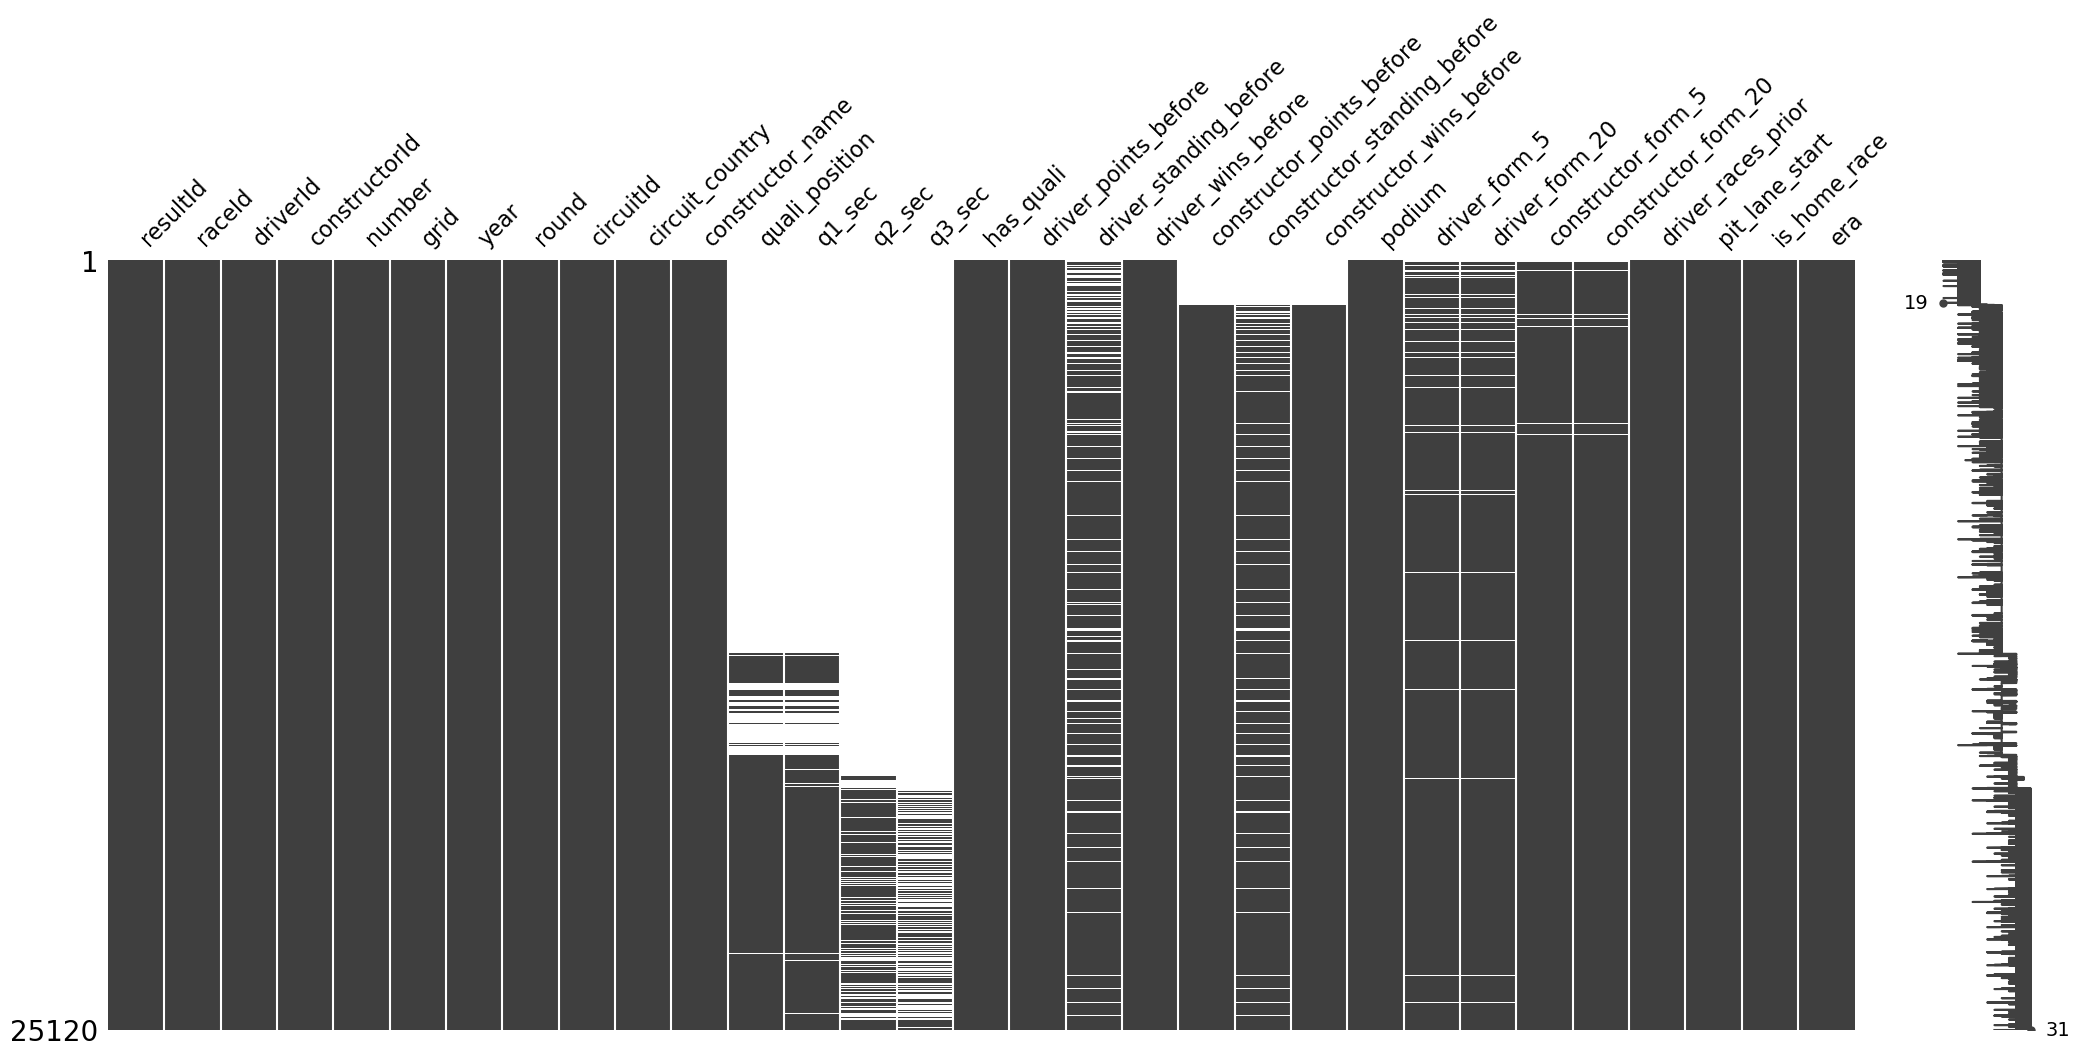

In [214]:
import missingno as msno 
msno.matrix(cleaned_df)

#### Feature Correlations
How certain features affect the `podium` column will be further explored here:

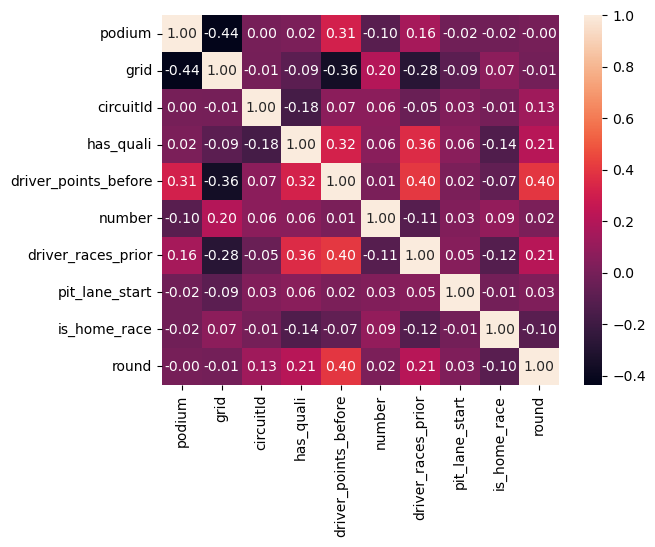

In [215]:
numeric_df = cleaned_df.select_dtypes(include='number')
# numeric_df_2003 = numeric_df[numeric_df['year']>2003]
# numeric_df_2003.head()
# numeric_df_2003.isnull().sum()
clean_num_df = numeric_df.loc[:, numeric_df.notna().all()]
# clean_num_df = numeric_df_2003.loc[:, numeric_df_2003.notna().all()]

mat_corr = clean_num_df[['podium','grid','circuitId','has_quali','driver_points_before','number','driver_races_prior','pit_lane_start','is_home_race','round']].corr()
sns.heatmap(mat_corr, annot=True, fmt='.2f') 
plt.show()

#### Grid Position vs. Podium

*Note: higher grid position is a smaller number ex: 1 is higher than 2*

From the following barplot, it is clear that higher grid positions (1-10) yield higher podium rates than lower grid positions (11-34) with high confidence. A pattern is seen where when the grid position decreases, the podium rate decreases. 
- Therefore `grid` is a valuable feature to include in the set
  
However, it is worth noting that there are a few anomalies where there are lower grid positions yielding higher podium rates but those have lower confidence.

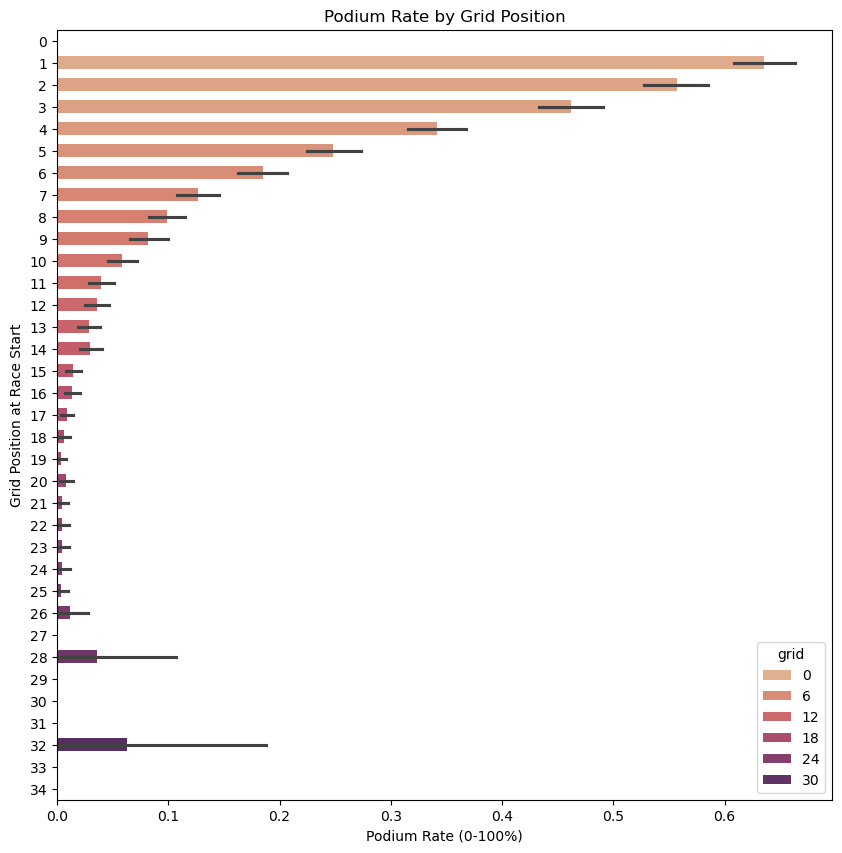

In [216]:
plt.figure(figsize=(10, 10))
sns.barplot(data=cleaned_df, x='podium', y='grid', orient="h", width=0.6, hue="grid",palette='flare') 
plt.title('Podium Rate by Grid Position') 
plt.xlabel("Podium Rate (0-100%)")
plt.ylabel("Grid Position at Race Start")
plt.show()

#### Constructor vs Podium

- Here the `podium` rate per `constructor_name` is plotted to see the relationship between constructors and the number of podium finishes

  - From this plot, it can be noted that some constructors have higher podium rates than others which implies that the constructor can actually affect a driver's probability of ending up in a podium position
- A binary heatmap plot is made to see which constructor names actually carry through to later years to determine if it is a meaningful feature to include in the set

  - From this plot, it is clear that many constructor names do not carry on to more recent years and so it is not reliable to train the model on `constructor_name` for predicting results in modern races. This is because the training set spans many years over which the constructor names change, causing any historical context to be lost.
 
Thus, `constructor_name` will be excluded from the feature set
  

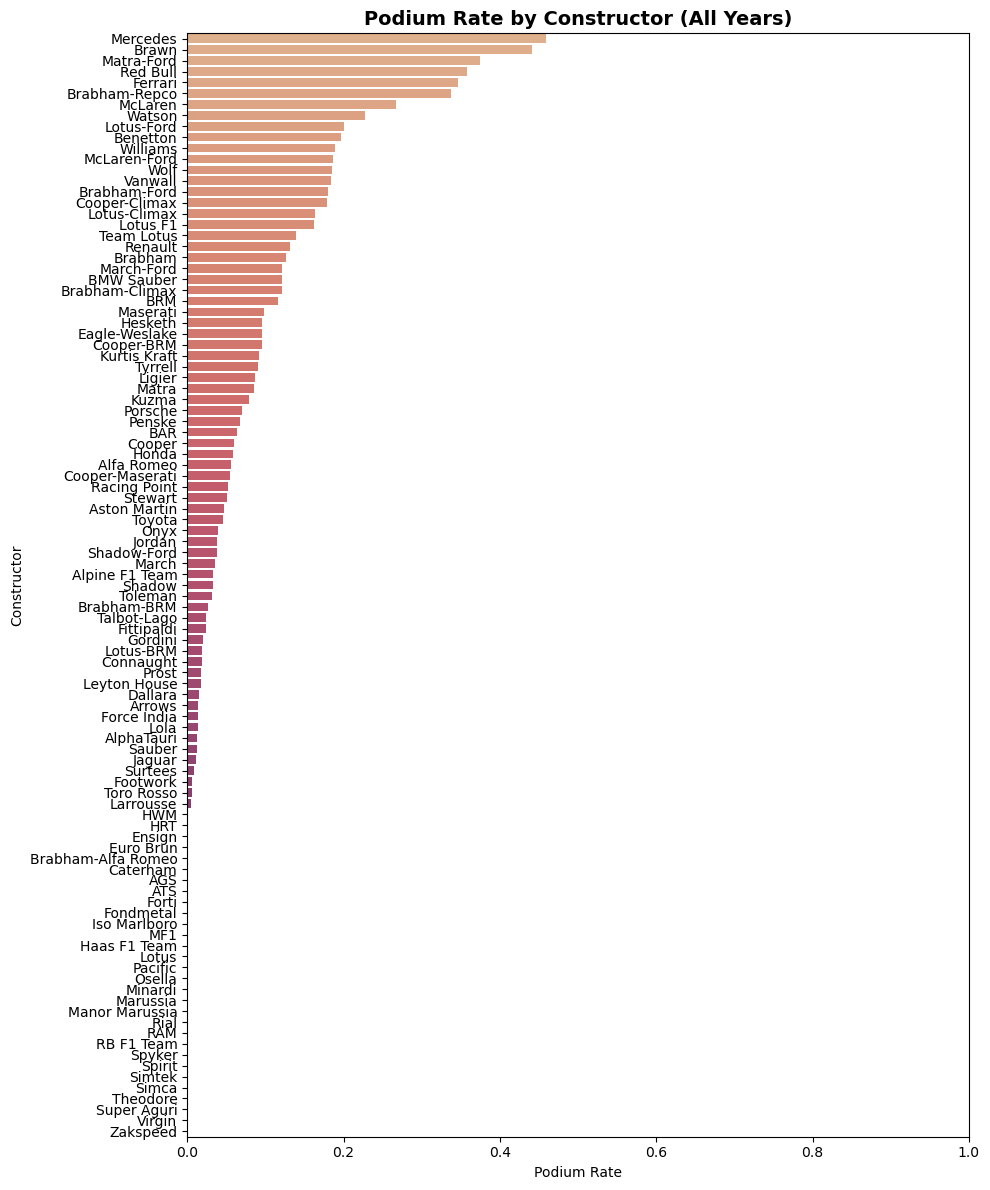

In [217]:
# plt.figure(figsize=(10, 10))
# sns.barplot(data=cleaned_df[cleaned_df['year']>1994], x='podium', y='constructor_name', orient="h", width=0.6, hue="constructor_name",palette='flare') 
# plt.title('Podium Rate by Constructor')
# plt.show()

# 1. Group by constructor and calculate mean podium rate across ALL years
constructor_podium_rate = (
    cleaned_df.groupby('constructor_name')['podium']
    .agg(podium_rate='mean', total_races='count')
    .reset_index()
)

# Optional: Filter for constructors with at least 20 entries to avoid one-off noise
constructor_podium_rate = constructor_podium_rate[constructor_podium_rate['total_races'] >= 20]

# 2. Sort constructors by podium rate in descending order
constructor_podium_rate = constructor_podium_rate.sort_values(by='podium_rate', ascending=False)

# 3. Plot
plt.figure(figsize=(10, 12))
sns.barplot(
    data=constructor_podium_rate,
    x='podium_rate',
    y='constructor_name',
    hue='constructor_name',
    palette='flare',
    legend=False
)

plt.title('Podium Rate by Constructor (All Years)', fontsize=14, fontweight='bold')
plt.xlabel('Podium Rate')
plt.ylabel('Constructor')
plt.xlim(0, 1)  # Sets x-axis from 0% to 100%
plt.tight_layout()
plt.show()

In [218]:
print(cleaned_df['constructor_name'].count())
has_mercedes = cleaned_df['constructor_name'].str.contains('Mercedes', case=False, na=False).any()
print(f"Does it include Mercedes? {has_mercedes}")

25120
Does it include Mercedes? True


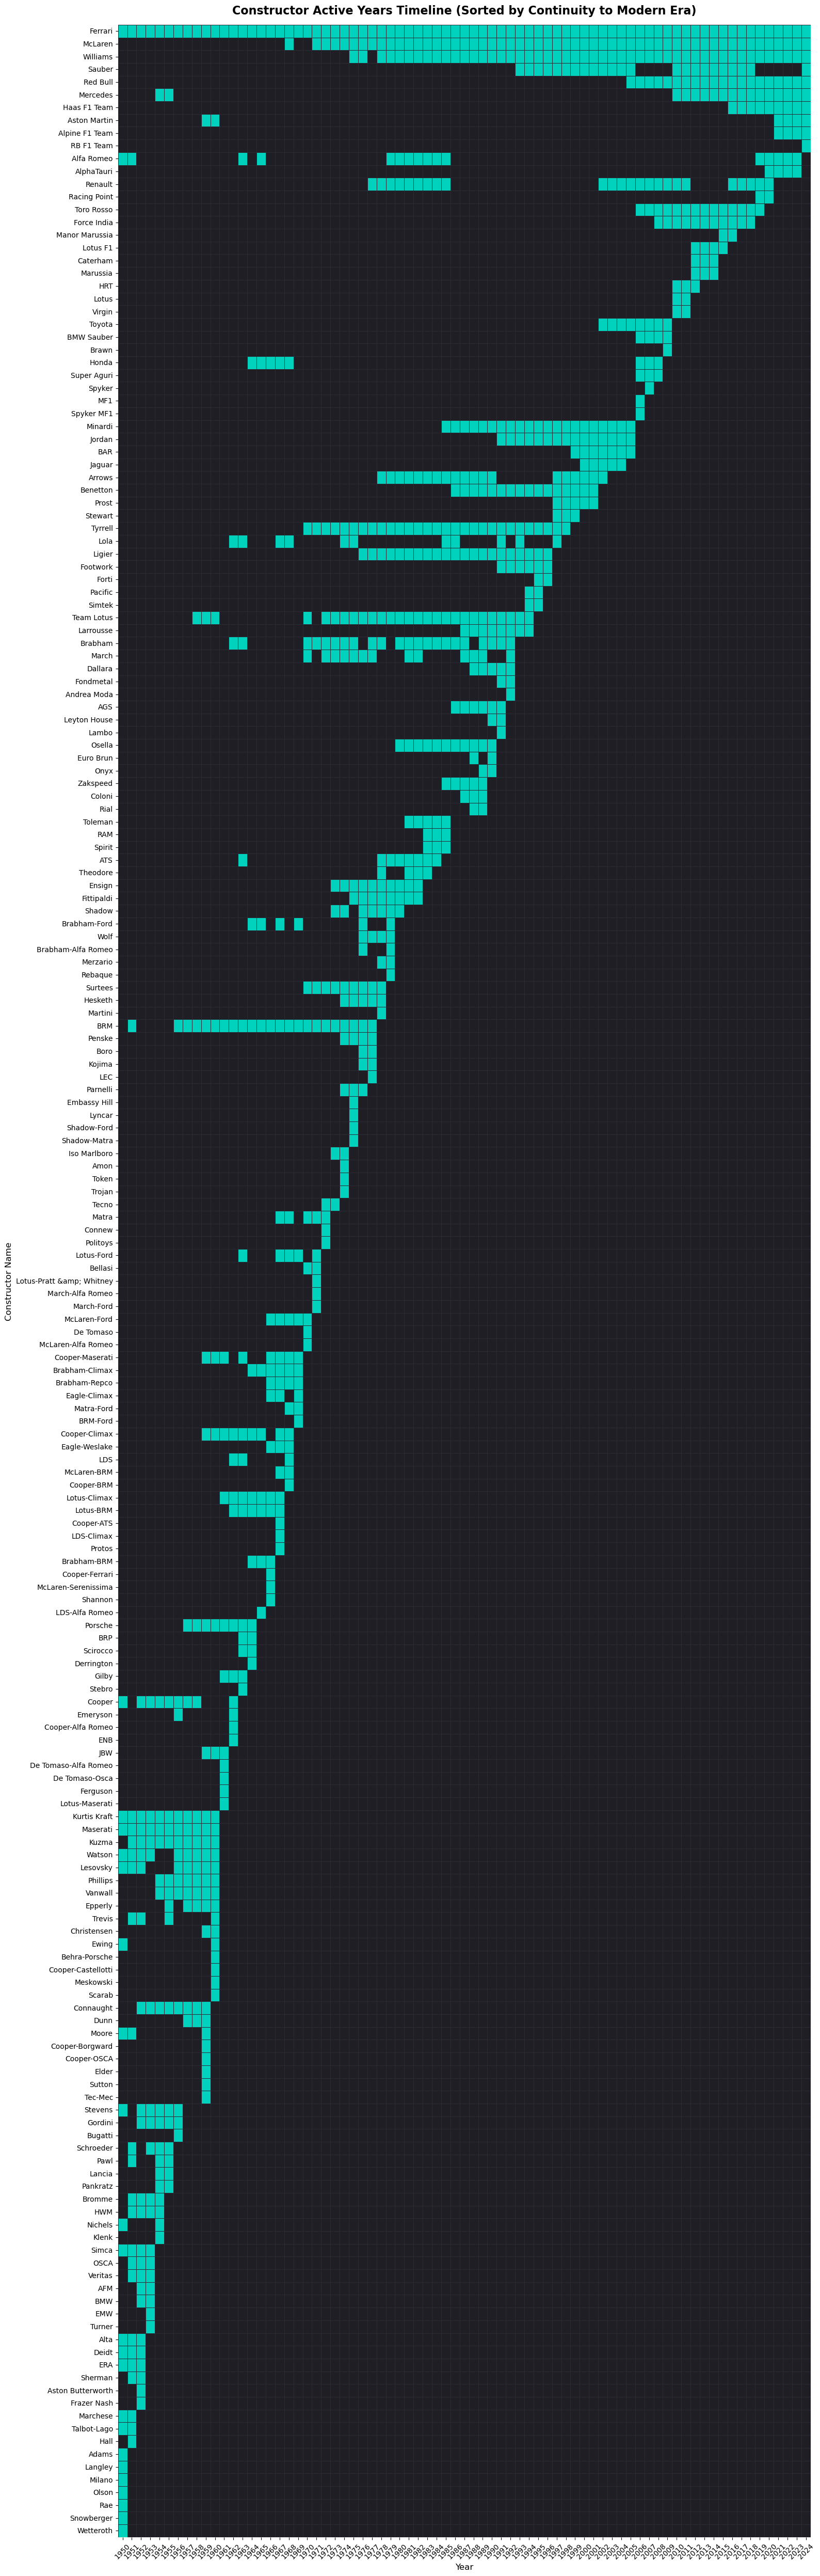

In [219]:
# Create a binary indicator matrix: 1 if active in that year, 0 if not
constructor_timeline = (
    cleaned_df.groupby(['constructor_name', 'year']).size().unstack(fill_value=0)
)
constructor_timeline = (constructor_timeline > 0).astype(int)

# Sort by 'most recent active year' and 'total active years' to bring active modern teams to the top
recent_year = constructor_timeline.apply(
    lambda row: row[row > 0].index.max(), axis=1
)
total_years = constructor_timeline.sum(axis=1)

sorted_index = (
    pd.DataFrame({'max_year': recent_year, 'total_years': total_years})
    .sort_values(by=['max_year', 'total_years'], ascending=[False, False])
    .index
)

constructor_timeline_sorted = constructor_timeline.loc[sorted_index]

# Plot Heatmap
plt.figure(figsize=(16, 50))
sns.heatmap(
    constructor_timeline_sorted,
    cmap=['#1e1e24', '#00d2be'],  # Dark for inactive, Teal for active
    cbar=False,
    linewidths=0.5,
    linecolor='#2b2b36',
)

plt.title(
    'Constructor Active Years Timeline (Sorted by Continuity to Modern Era)',
    fontsize=16,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Constructor Name', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Circuit effect on Podium Probability from Different Grid Positions
**Grid Position to Podium Position Conversion Rate:** how the circuit itself affects drivers' abilities to end up on podium from different grid positions. Plots podium rate from different grid positions for each circuit.

The following plots show that some circuits cause higher podium rates for drivers starting in higher grid positions while others don't give that much of an advantage. So, `circuitId` must be used as a categorical feature alongside `grid` position to help give the model more context for predictions.

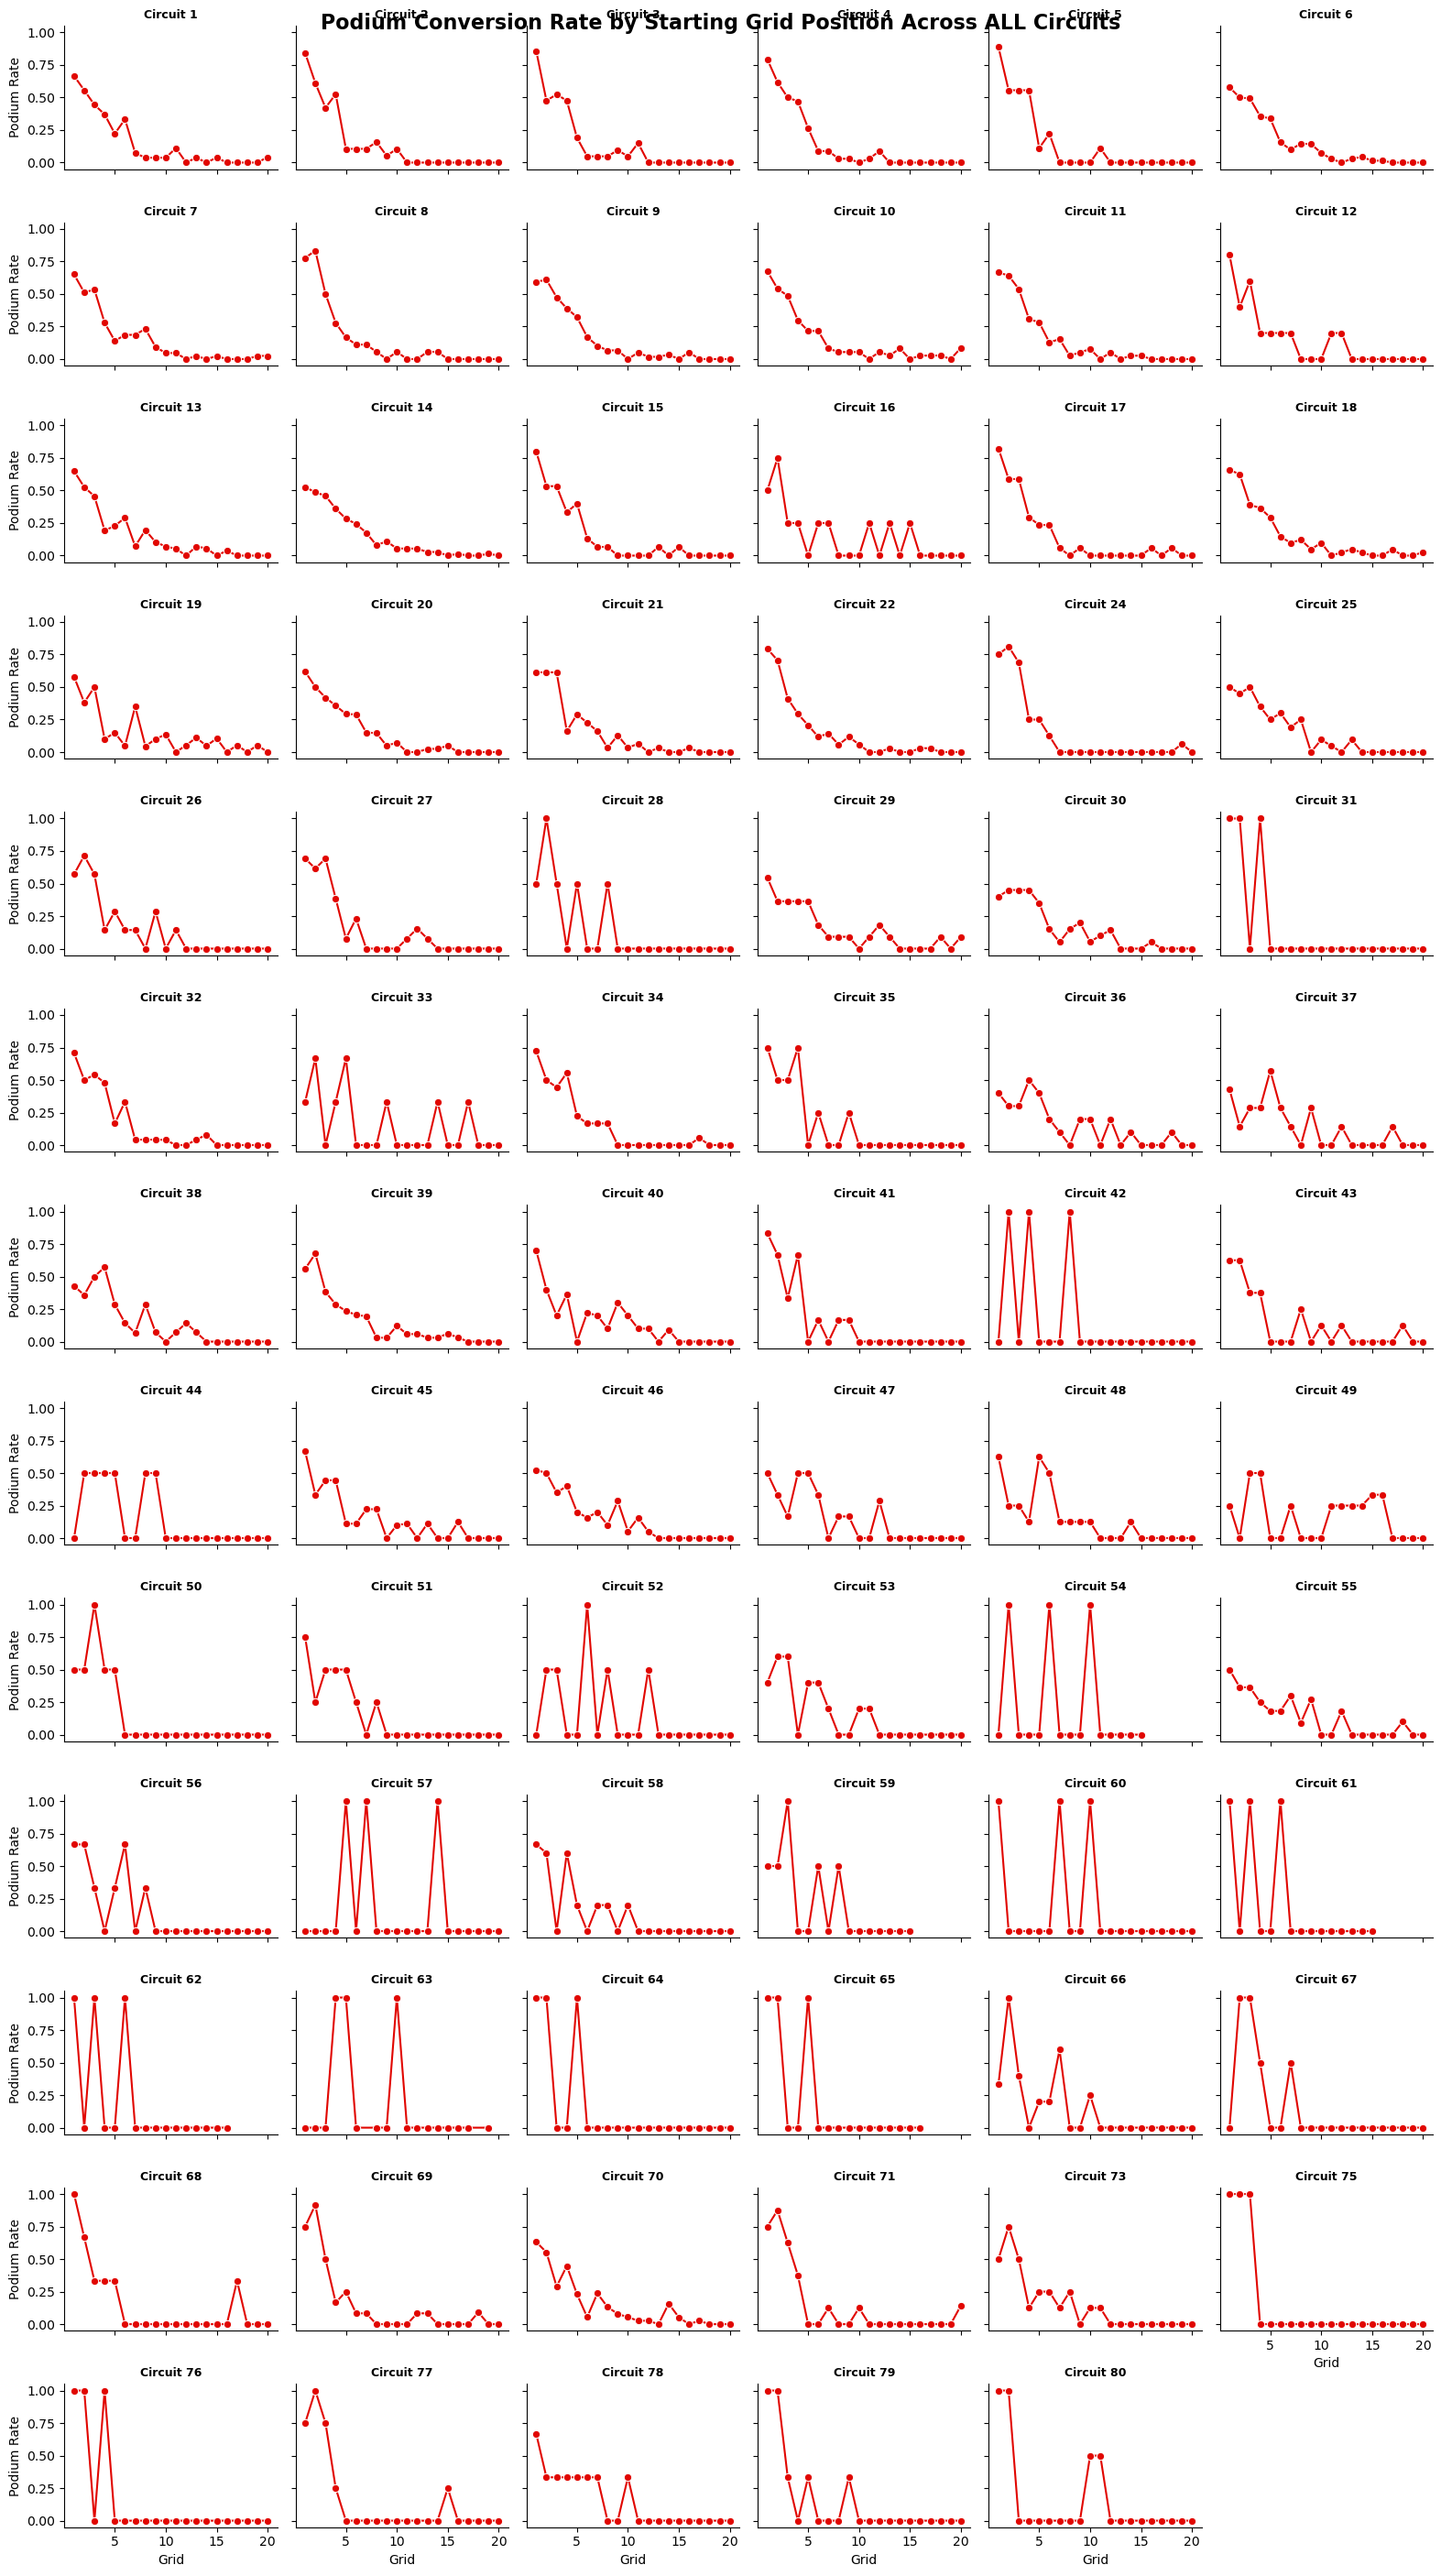

In [220]:
# 1. Filter dataset for starting grid positions 1 to 20 across ALL circuits
grid_10_df = cleaned_df[cleaned_df['grid'].between(1, 20)]
# grid_10_df = cleaned_df


# 2. Calculate average podium rate per circuit per grid position
circuit_grid_rates = (
    grid_10_df.groupby(['circuitId', 'grid'])['podium']
    .mean()
    .reset_index()
)

# Optional: Replace 'circuitId' with 'circuit_country' or circuit name column if available
circuit_col = 'circuitId'

# 3. Create FacetGrid for ALL circuits (6 columns per row)
g = sns.FacetGrid(
    circuit_grid_rates,
    col=circuit_col,
    col_wrap=6,
    height=2.2,
    aspect=1.2,
    sharey=True
)

# Plot podium rate vs grid position for each circuit
g.map_dataframe(
    sns.lineplot,
    x='grid',
    y='podium',
    color='#e10600',
    marker='o',
    linewidth=1.5
)

g.set_axis_labels('Grid', 'Podium Rate')
g.set_titles(col_template='Circuit {col_name}', weight='bold', size=9)
g.fig.subplots_adjust(top=1.0)
g.fig.suptitle('Podium Conversion Rate by Starting Grid Position Across ALL Circuits', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

#### Home Race Advantage vs Podium
Here, the effect of whether the race is a home race to a driver is explored by viewing how it affects podium rate by grid position.

From the following plot, the effect of whether the race is a home race or not does not have a very significant effect on whether the drivers end up on the podium or not. Changes in podium rate are within <= 8% of each other. So `is_home_race` is not an important feature to include in the set.


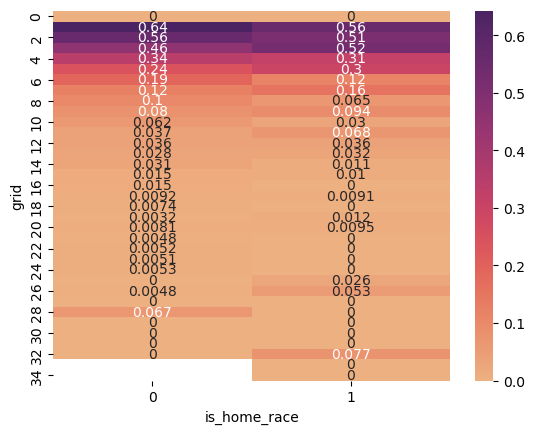

<Figure size 1600x3000 with 0 Axes>

In [221]:
# plot relation of is_home_race to grid position and podium rate
pivot_home = pd.pivot_table(cleaned_df, index="grid", columns="is_home_race", values="podium", aggfunc="mean")
sns.heatmap(pivot_home, annot=True, cmap="flare")
plt.figure(figsize=(16, 30))
plt.show()

#### Driver Experience vs Podium

`driver_form_5`: higher values yield higher `podium` rates. Imputation does not distort the data.

`driver_form_20`: higher values yield higher `podium` rates. Imputation does not distort the data.

`driver_races_prior`: affects `podium` directly. Higher values yield higher `podium` rates.

**Histogram Plots for Driver Form Before Imputation**

The following plot shows the distribution of values of `driver_form_5` and `driver_form_20` before imputation with median values

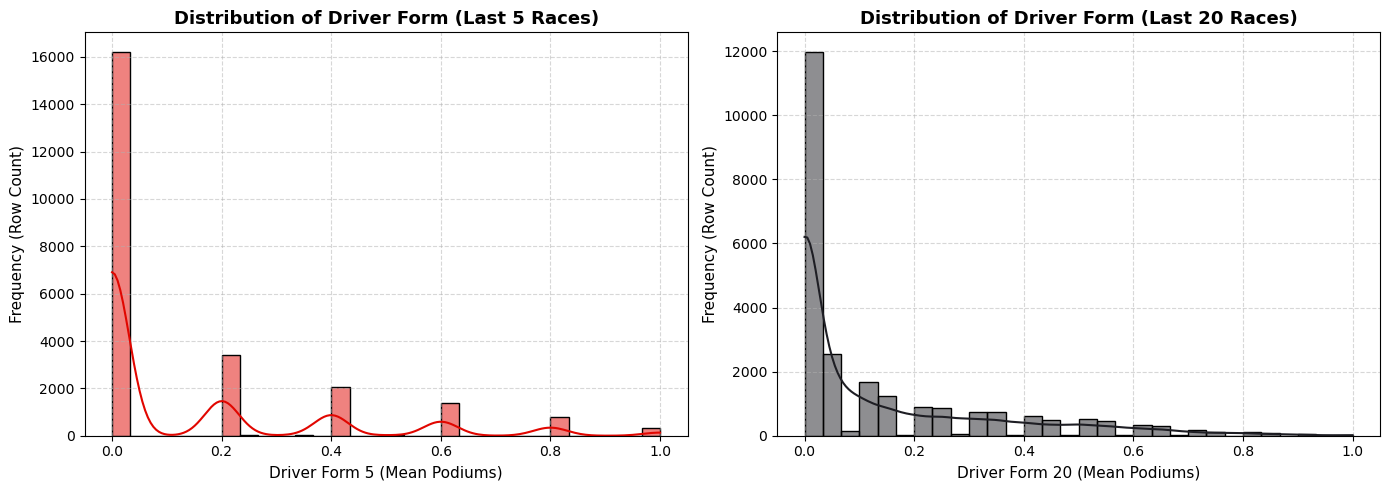

In [222]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram for Driver Form 5
sns.histplot(
    data=cleaned_df,
    x='driver_form_5',
    ax=axes[0],
    color='#e10600',
    bins=30,
    kde=True,
)
axes[0].set_title(
    'Distribution of Driver Form (Last 5 Races)',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel('Driver Form 5 (Mean Podiums)', fontsize=11)
axes[0].set_ylabel('Frequency (Row Count)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Histogram for Driver Form 20
sns.histplot(
    data=cleaned_df,
    x='driver_form_20',
    ax=axes[1],
    color='#1e1e24',
    bins=30,
    kde=True,
)
axes[1].set_title(
    'Distribution of Driver Form (Last 20 Races)',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Driver Form 20 (Mean Podiums)', fontsize=11)
axes[1].set_ylabel('Frequency (Row Count)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Impute Nulls in Driver form with Median**

As stated in the overview, the missing values in `driver_form_5` and `driver_form_20` are imputed with the median to prevent any outliers form affecting the data. It also makes sense since the rows with missing values belong to debuting drivers so they would have 0.0 form instead of the mean which is ~0.13.

In [223]:
# Step 1: Fill nulls with medians
# ---------------------------------------------------------
print(cleaned_df['driver_form_5'].median())
print(cleaned_df['driver_form_20'].median())

0.0
0.05


In [224]:
cleaned_df['driver_form_5'] = cleaned_df['driver_form_5'].fillna(
    cleaned_df['driver_form_5'].median()
)
cleaned_df['driver_form_20'] = cleaned_df['driver_form_20'].fillna(
    cleaned_df['driver_form_20'].median()
)

**Decile Plots to view effect of Driver Form on Podium Rate**

These plots show that driver form does affect the podium rate. A direct relationship is seen where when the driver form increases, so does the rate of podium finishes.

In [225]:
# Step 2: Create Decile Plots (Podium Rate by Form Deciles)
# ---------------------------------------------------------
# Create 10 equal-sized buckets (deciles) for each form metric
cleaned_df['form_5_decile'] = pd.qcut(
    cleaned_df['driver_form_5'], q=10, duplicates='drop'
)
cleaned_df['form_20_decile'] = pd.qcut(
    cleaned_df['driver_form_20'], q=10, duplicates='drop'
)

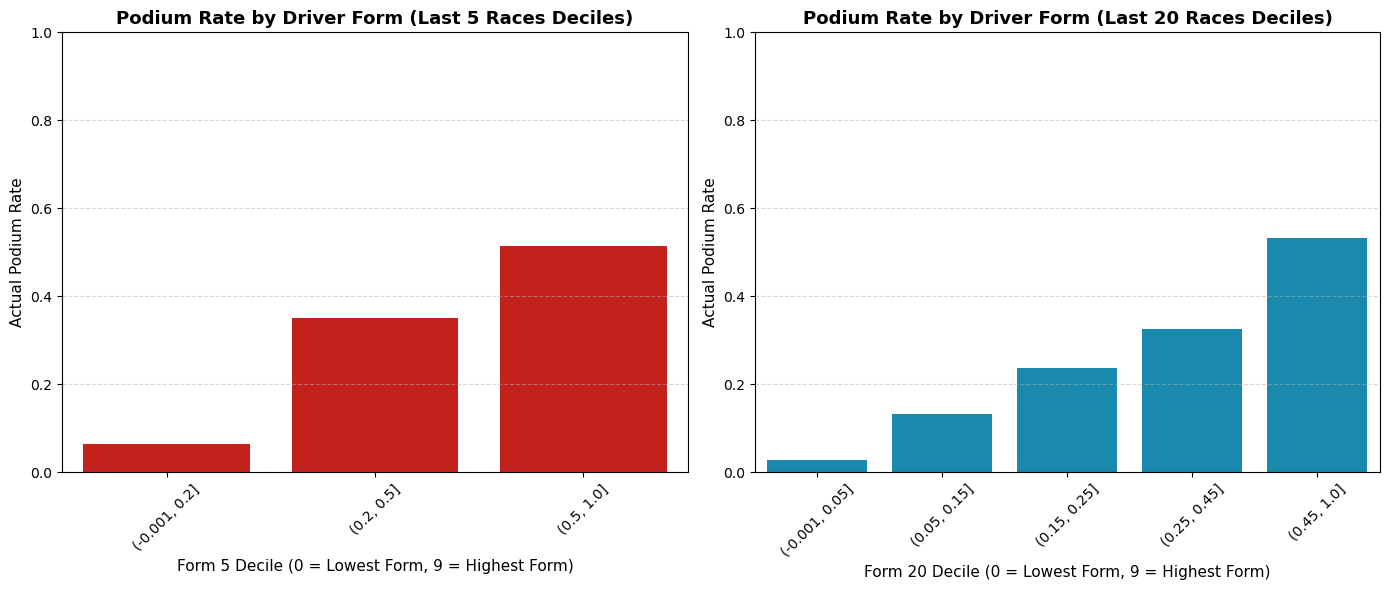

In [226]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot for Driver Form 5
sns.barplot(
    data=cleaned_df,
    x='form_5_decile',
    y='podium',
    ax=axes[0],
    color='#e10600',
    errorbar=None,
)
axes[0].set_title(
    'Podium Rate by Driver Form (Last 5 Races Deciles)',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel(
    'Form 5 Decile (0 = Lowest Form, 9 = Highest Form)', fontsize=11
)
axes[0].set_ylabel('Actual Podium Rate', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylim(0, 1.0)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot for Driver Form 20
sns.barplot(
    data=cleaned_df,
    x='form_20_decile',
    y='podium',
    ax=axes[1],
    color='#0096c7',
    errorbar=None,
)
axes[1].set_title(
    'Podium Rate by Driver Form (Last 20 Races Deciles)',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel(
    'Form 20 Decile (0 = Lowest Form, 9 = Highest Form)', fontsize=11
)
axes[1].set_ylabel('Actual Podium Rate', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, 1.0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Histogram Plots for Driver Form After Imputation**

The following plot shows the distribution of values of `driver_form_5` and `driver_form_20` after imputation with median values.

It is clear to see that imputation did not introduce significant distortion, which means that the driver form features can be safely used in the feature set.

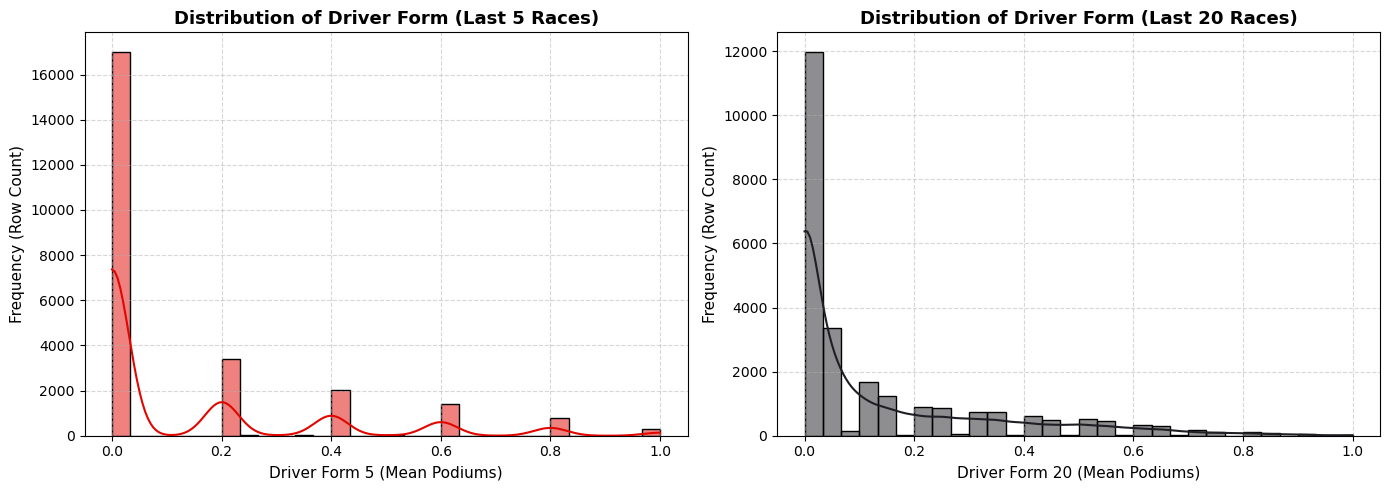

In [227]:
# Step 3: Create Histograms (Distribution of Form Metrics)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram for Driver Form 5
sns.histplot(
    data=cleaned_df,
    x='driver_form_5',
    ax=axes[0],
    color='#e10600',
    bins=30,
    kde=True,
)
axes[0].set_title(
    'Distribution of Driver Form (Last 5 Races)',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel('Driver Form 5 (Mean Podiums)', fontsize=11)
axes[0].set_ylabel('Frequency (Row Count)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Histogram for Driver Form 20
sns.histplot(
    data=cleaned_df,
    x='driver_form_20',
    ax=axes[1],
    color='#1e1e24',
    bins=30,
    kde=True,
)
axes[1].set_title(
    'Distribution of Driver Form (Last 20 Races)',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Driver Form 20 (Mean Podiums)', fontsize=11)
axes[1].set_ylabel('Frequency (Row Count)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Distribution of Previous Number of Races for Podium vs Not**

A bar plot is used to visualize the effect of `driver_races_prior` on the `podium` finishes. It shows that drivers who have participated in a higher total number of races prior to the current race tend to end up on podium more with high confidence. This shows that `driver_races_prior` has a notable effect on `podium`.

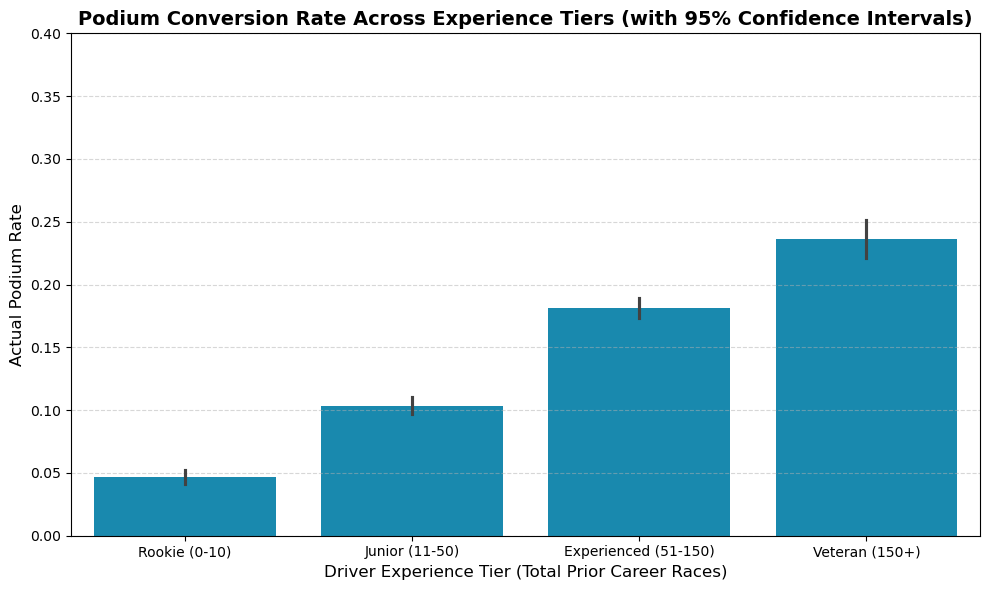

In [228]:
# 1. Group career experience into intuitive buckets
cleaned_df['experience_tier'] = pd.cut(
    cleaned_df['driver_races_prior'],
    bins=[-1, 10, 50, 150, 500],
    labels=['Rookie (0-10)', 'Junior (11-50)', 'Experienced (51-150)', 'Veteran (150+)']
)

# 2. Plot actual podium rate per experience tier with error bars (95% CI)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=cleaned_df,
    x='experience_tier',
    y='podium',
    color='#0096c7',
    errorbar=('ci', 95)  # Shows 95% confidence intervals
)

plt.title('Podium Conversion Rate Across Experience Tiers (with 95% Confidence Intervals)', fontsize=14, fontweight='bold')
plt.xlabel('Driver Experience Tier (Total Prior Career Races)', fontsize=12)
plt.ylabel('Actual Podium Rate', fontsize=12)
plt.ylim(0, 0.4)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Constructor Experience vs Podium

`constructor_form_5`: higher values yield higher `podium` rates. Imputation does not distort the data.

`constructor_form_20`: higher values yield higher `podium` rates. Imputation does not distort the data.

**Histogram Plots for Constructor Form Before Imputation**

The following plot shows the distribution of values of `constructor_form_5` and `constructor_form_20` before imputation with median values

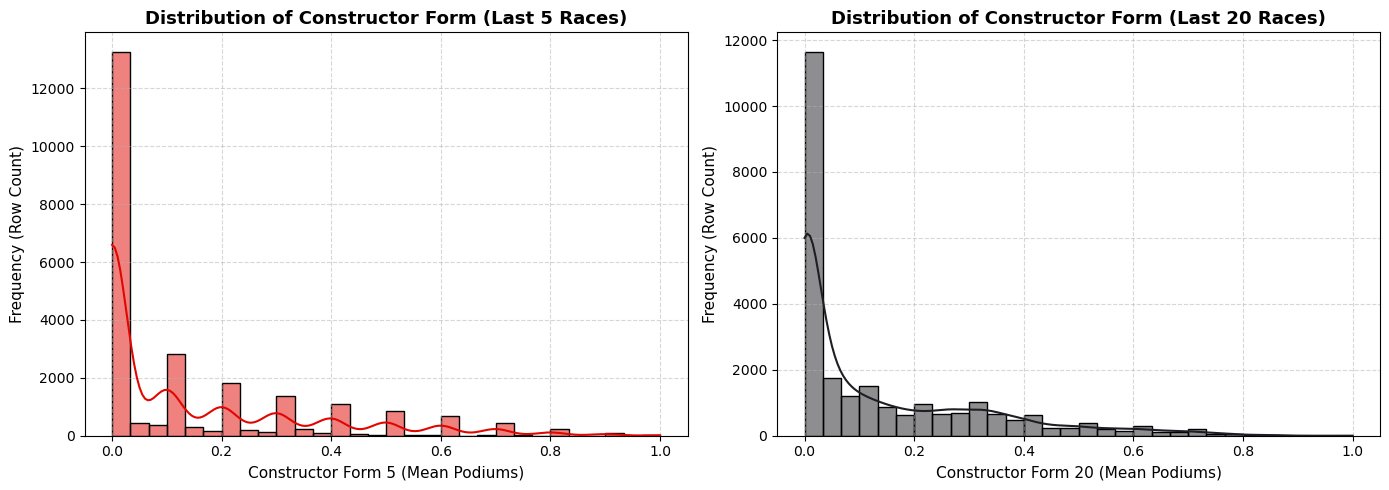

In [229]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram for Constructor Form 5
sns.histplot(
    data=cleaned_df,
    x='constructor_form_5',
    ax=axes[0],
    color='#e10600',
    bins=30,
    kde=True,
)
axes[0].set_title(
    'Distribution of Constructor Form (Last 5 Races)',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel('Constructor Form 5 (Mean Podiums)', fontsize=11)
axes[0].set_ylabel('Frequency (Row Count)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Histogram for Constructor Form 20
sns.histplot(
    data=cleaned_df,
    x='constructor_form_20',
    ax=axes[1],
    color='#1e1e24',
    bins=30,
    kde=True,
)
axes[1].set_title(
    'Distribution of Constructor Form (Last 20 Races)',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Constructor Form 20 (Mean Podiums)', fontsize=11)
axes[1].set_ylabel('Frequency (Row Count)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Impute Nulls in Constructor form with Median**

As stated in the overview, the missing values in `constructor_form_5` and `constructor_form_20` are imputed with the median to prevent any outliers form affecting the data. It also makes sense since the rows with missing values belong to debuting constructors or team name changes which count as new constructors so they would have 0.0 form instead of the mean which is ~0.137.

In [230]:
print(cleaned_df['constructor_form_5'].median())
print(cleaned_df['constructor_form_20'].median())

0.0
0.05


In [231]:
# Step 1: Fill nulls with median (representing team debut / no prior history)
# ---------------------------------------------------------
cleaned_df['constructor_form_5'] = cleaned_df['constructor_form_5'].fillna(cleaned_df['constructor_form_5'].median())
cleaned_df['constructor_form_20'] = cleaned_df['constructor_form_20'].fillna(cleaned_df['constructor_form_20'].median())

**Decile Plots to view effect of Constructor Form on Podium Rate**

These plots show that constructor form does affect the podium rate. A direct relationship is seen where when the constructor form increases, so does the rate of podium finishes.

In [232]:
# Step 2: Create Decile Plots (Podium Rate by Constructor Form Deciles)
# ---------------------------------------------------------
# Create equal-sized buckets (deciles) for each constructor form metric
cleaned_df['constructor_form_5_decile'] = pd.qcut(
    cleaned_df['constructor_form_5'], q=10, duplicates='drop'
)
cleaned_df['constructor_form_20_decile'] = pd.qcut(
    cleaned_df['constructor_form_20'], q=10, duplicates='drop'
)

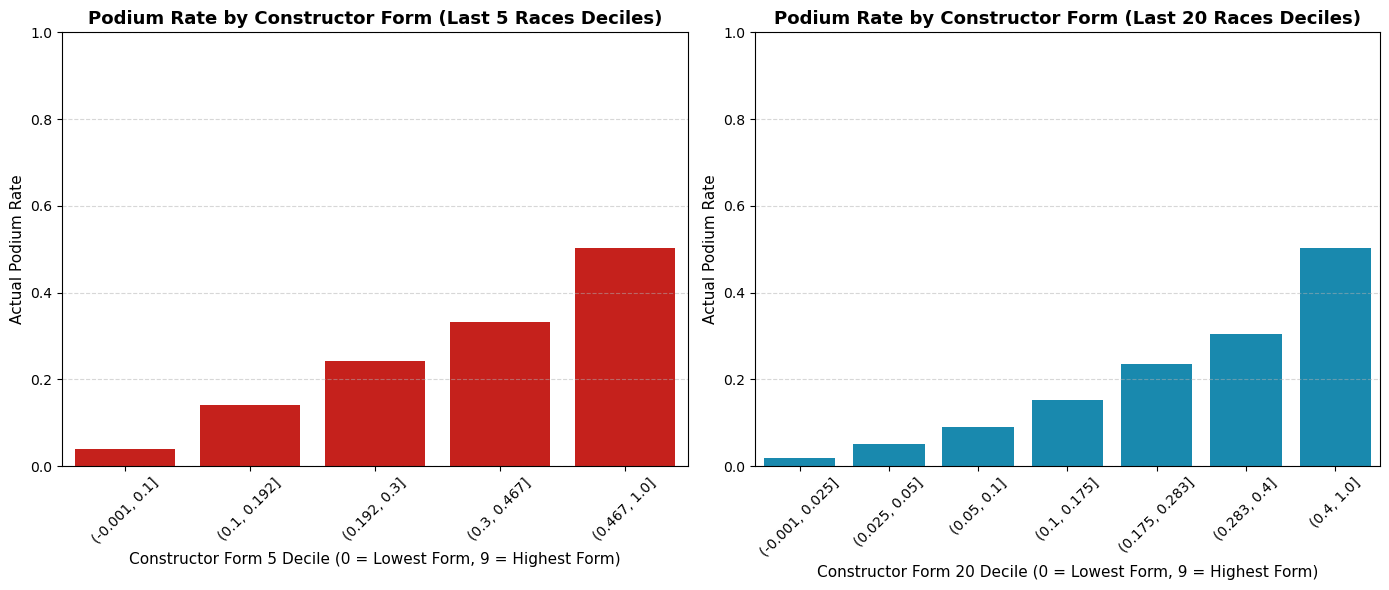

In [233]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot for Constructor Form 5
sns.barplot(
    data=cleaned_df,
    x='constructor_form_5_decile',
    y='podium',
    ax=axes[0],
    color='#e10600',
    errorbar=None,
)
axes[0].set_title(
    'Podium Rate by Constructor Form (Last 5 Races Deciles)',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel(
    'Constructor Form 5 Decile (0 = Lowest Form, 9 = Highest Form)', fontsize=11
)
axes[0].set_ylabel('Actual Podium Rate', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylim(0, 1.0)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot for Constructor Form 20
sns.barplot(
    data=cleaned_df,
    x='constructor_form_20_decile',
    y='podium',
    ax=axes[1],
    color='#0096c7',
    errorbar=None,
)
axes[1].set_title(
    'Podium Rate by Constructor Form (Last 20 Races Deciles)',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel(
    'Constructor Form 20 Decile (0 = Lowest Form, 9 = Highest Form)', fontsize=11
)
axes[1].set_ylabel('Actual Podium Rate', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, 1.0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Histogram Plots for Constructor Form After Imputation**

The following plot shows the distribution of values of `constructor_form_5` and `constructor_form_20` after imputation with median values.

It is clear to see that imputation did not introduce significant distortion, which means that the constructor form features can be safely used in the feature set.

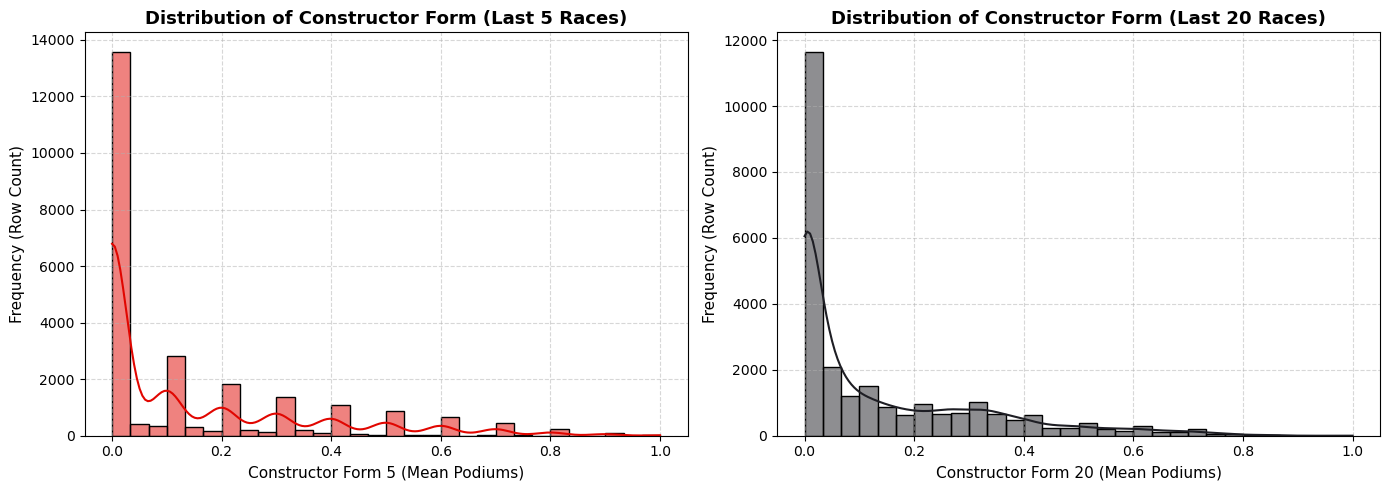

In [234]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram for Constructor Form 5
sns.histplot(
    data=cleaned_df,
    x='constructor_form_5',
    ax=axes[0],
    color='#e10600',
    bins=30,
    kde=True,
)
axes[0].set_title(
    'Distribution of Constructor Form (Last 5 Races)',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel('Constructor Form 5 (Mean Podiums)', fontsize=11)
axes[0].set_ylabel('Frequency (Row Count)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Histogram for Constructor Form 20
sns.histplot(
    data=cleaned_df,
    x='constructor_form_20',
    ax=axes[1],
    color='#1e1e24',
    bins=30,
    kde=True,
)
axes[1].set_title(
    'Distribution of Constructor Form (Last 20 Races)',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Constructor Form 20 (Mean Podiums)', fontsize=11)
axes[1].set_ylabel('Frequency (Row Count)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### Round vs Podium

The effect of `round` on `podium` is explored here.

From the following bar plot and line plot, it can be observed that the `podium` rate across the different rounds of the championship stays relatively flat with very minor increases in later rounds. Therefore, `round` is not significant enough to include in the feature set.

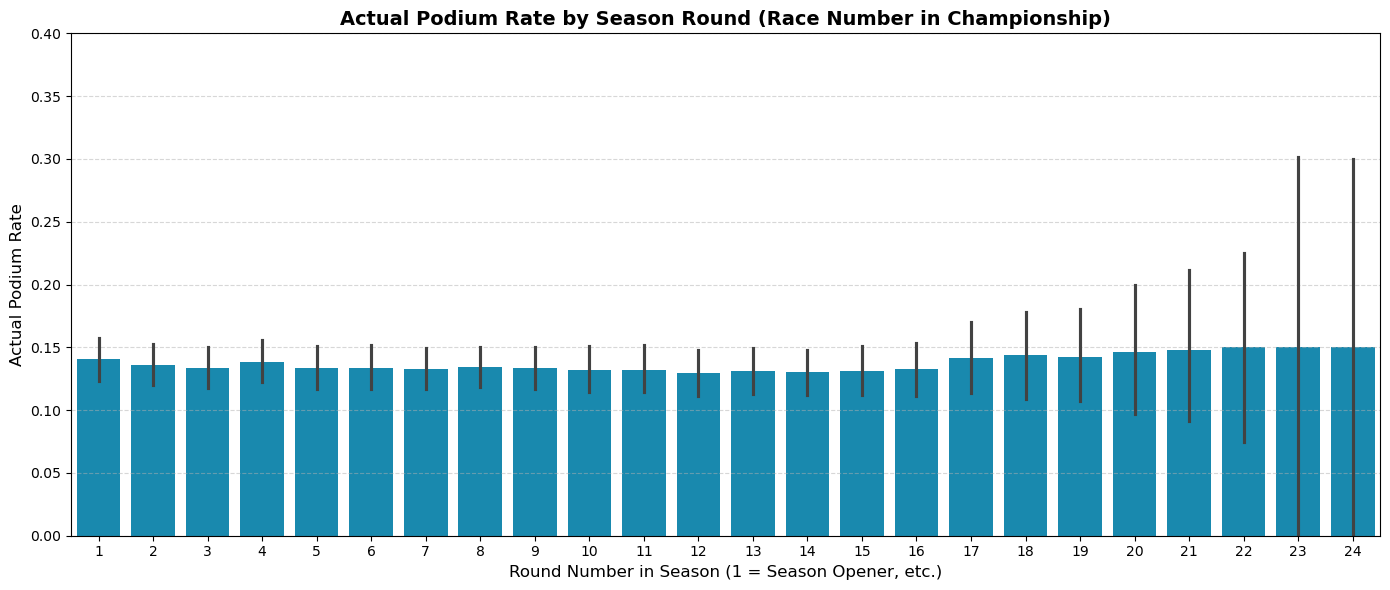

In [235]:
plt.figure(figsize=(14, 6))

# Ensure round is treated appropriately (or grouped if there are too many unique rounds)
# F1 seasons usually range from ~8 to 24 rounds depending on the era
sns.barplot(
    data=cleaned_df,
    x='round',
    y='podium',
    color='#0096c7',
    errorbar=('ci', 95)  # Shows 95% confidence intervals to check for statistical significance
)

plt.title('Actual Podium Rate by Season Round (Race Number in Championship)', fontsize=14, fontweight='bold')
plt.xlabel('Round Number in Season (1 = Season Opener, etc.)', fontsize=12)
plt.ylabel('Actual Podium Rate', fontsize=12)
plt.ylim(0, 0.4)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

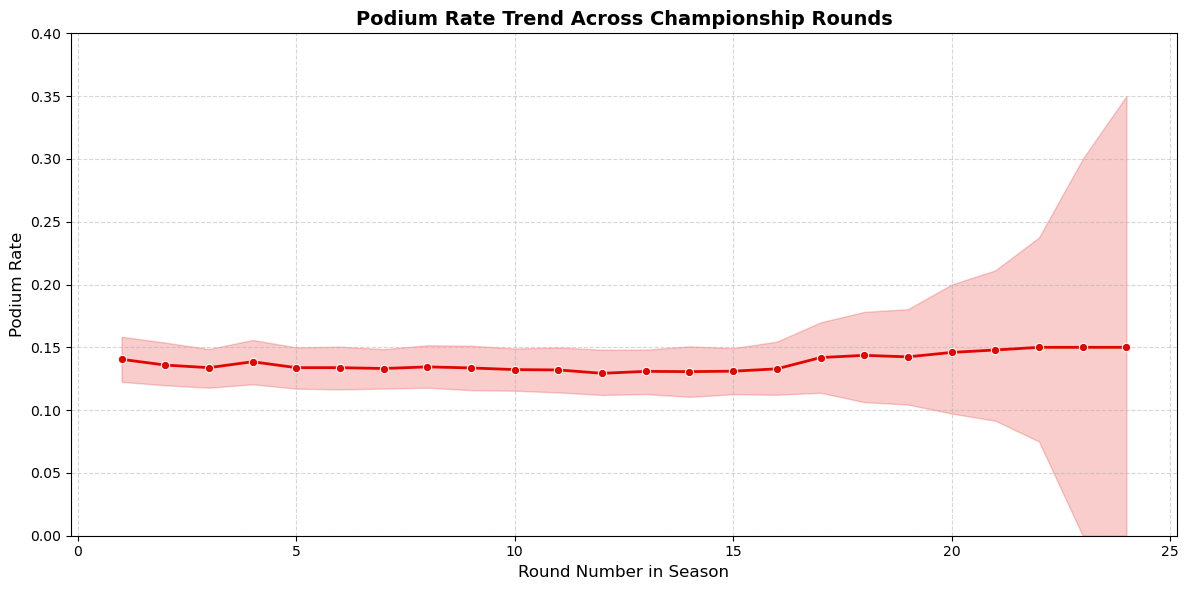

In [236]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=cleaned_df,
    x='round',
    y='podium',
    color='#e10600',
    marker='o',
    linewidth=2,
    errorbar=('ci', 95)
)

plt.title('Podium Rate Trend Across Championship Rounds', fontsize=14, fontweight='bold')
plt.xlabel('Round Number in Season', fontsize=12)
plt.ylabel('Podium Rate', fontsize=12)
plt.ylim(0, 0.4)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### `pit_lane_start` vs `podium`

Below is a plot comparing the podium rate of drivers who started from the pit lane vs. those who started on the grid. It shows that those who start from the pit lane are severely less likely to end up on podium. `pit_lane_start` is important since `grid` does not give information on whether the driver started in the pit lane or not and `quali_position` does not give information on the penalties applied pre-race.

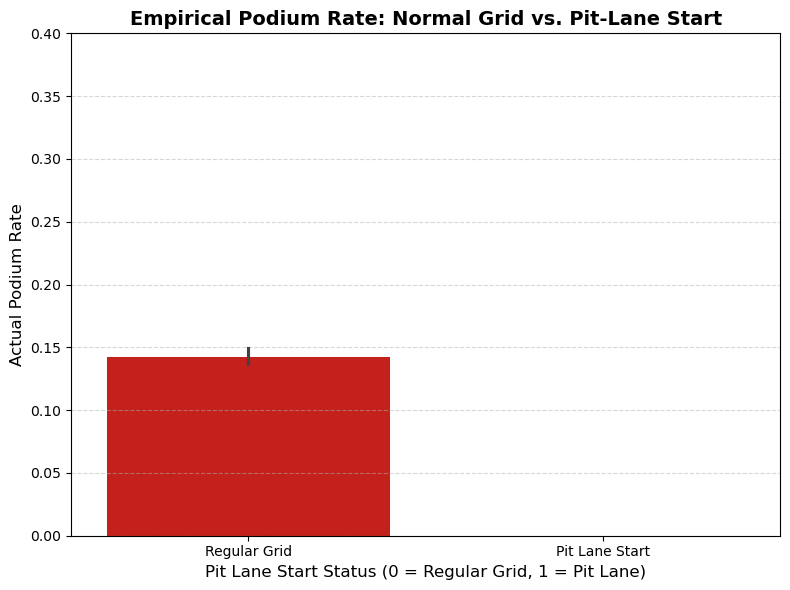

In [237]:
plt.figure(figsize=(8, 6))

# Plot actual podium rate grouped by pit_lane_start flag (0 = Normal Grid, 1 = Pit Lane Start)
sns.barplot(
    data=cleaned_df[cleaned_df['year']>1994],
    x='pit_lane_start',
    y='podium',
    palette=['#e10600', '#6c757d'],
    hue='pit_lane_start',
    legend=False,
    errorbar=('ci', 95)  # Shows 95% confidence intervals
)

plt.title('Empirical Podium Rate: Normal Grid vs. Pit-Lane Start', fontsize=14, fontweight='bold')
plt.xlabel('Pit Lane Start Status (0 = Regular Grid, 1 = Pit Lane)', fontsize=12)
plt.ylabel('Actual Podium Rate', fontsize=12)
plt.xticks([0, 1], ['Regular Grid', 'Pit Lane Start'])
plt.ylim(0, 0.4)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Final Selected Features:
1. `circuitId`
2. `grid`
3. `driver_points_before`
4. `driver_wins_before`
5. `driver_races_prior`
6. `driver_form_5`
7. `driver_form_20`
8. `constructor_form_5` 
9. `constructor_form_20`
10. `year` for temporal split only
11. `podium` target feature

#### Features that cannot be used unless the training year lower bound is changed:
12. `constructor_points_before` only if `year>=1958`
13. `constructor_wins_before` only if `year>=1958`
14. `quali_position` only if `year>=2003`
15. `pit_lane_start` only if `year>=1994`



### Final Feature Selection & Data Splitting Summary

#### 1. Data Splitting & Temporal Constraints Strategy

To prevent data leakage and ensure realistic time-series generalization, the dataset adheres to strict temporal boundaries:

* **The `year` Feature:** Used exclusively to partition the dataset chronologically for training, validation, and testing. It is **excluded** from the training feature set to prevent the model from overfitting to specific calendar years.
* **Full Historical Record Scope (All Years):** The model now leverages the entire historical record across all available Formula 1 seasons. *Note on Temporal Cutoffs:* Restricting data to $\ge 2003$ would ensure complete availability for `quali_position` ($\ge 2003$), `pit_lane_start` ($\ge 1994$), and constructor championship metrics ($\ge 1958$). However, to avoid removing a massive chunk of historical data, lower-bound filters were removed, and features requiring post-1958/1994/2003 cutoffs were excluded instead.
* **Split Structure:** A strict **chronological / walk-forward split** (e.g., Train: pre-2020, Validation: 2020–2021, Test: 2022+) is applied rather than a random split to prevent future information leakage into past predictions.

---

#### 2. Final Selected Features (Retained)

| Feature | Category | Impact on Podium | Justification / EDA Findings |
| --- | --- | --- | --- |
| **`circuitId`** | Categorical | Indirect / Contextual | Captures track shape, length, and geographical properties that dictate grid-to-podium conversion and overtaking viability. |
| **`grid`** | Numeric | High Positive (0.436 corr) | Starting position is a primary determinant; higher grid positions (1–10) yield significantly higher podium conversion rates. |
| **`driver_points_before`** | Numeric | Moderate Positive (0.312 corr) | Indicates driver's seasonal standing and performance momentum prior to the race. |
| **`driver_wins_before`** | Numeric | Moderate Positive (0.367 corr) | Reflects proven race-winning capability within the season. |
| **`driver_races_prior`** | Numeric | Positive (0.157 corr) | Quantifies career experience; higher experience tiers show higher baseline podium rates. |
| **`driver_form_5`** / **`driver_form_20`** | Numeric | High Positive (0.466 / 0.475 corr) | Rolling mean podium rates over past 5/20 races. Missing values at career debuts are imputed with median ($0.0$) to reflect rookie status without distortion. |
| **`constructor_form_5`** / **`constructor_form_20`** | Numeric | High Positive (0.462 / 0.463 corr) | Rolling team form metrics. Missing values at team debuts are imputed with median ($0.0$). |

---

#### Features Excluded Because of Missingness / Temporal Lower Bounds (Pre-1958, Pre-1994, Pre-2003)

| Feature | Category | Impact on Podium | Justification / EDA Findings |
| --- | --- | --- | --- |
| **`quali_position`** | Numeric | High Positive (0.487 corr) | Represents raw one-lap performance independent of race-day grid penalties. Requires $\text{year} \ge 2003$, so it is excluded to preserve full historical record scope. |
| **`pit_lane_start`** | Binary | Severe Negative | Flags back-of-grid penalty starts. Requires $\text{year} \ge 1994$, so it is excluded to maintain all-years data. |
| **`constructor_points_before`** | Numeric | Moderate Positive (0.297 corr) | Captures accumulated team strength. Requires $\text{year} \ge 1958$ (constructor championship inception), so it is excluded. |
| **`constructor_wins_before`** | Numeric | High Positive (0.379 corr) | Highlights dominant constructor packages. Requires $\text{year} \ge 1958$, so it is excluded. |

---

#### 3. Excluded Features & Justifications

* **`podium`:** Used as the **target variable** of the model.
* **`resultId`, `raceId`, `driverId`, `constructorId`:** Excluded as relational database keys; state-based aggregates replace them to prevent historical rebranding confusion across decades and to prevent data leakage.
* **`number`:** Excluded because car numbers are arbitrary identifiers with near-zero correlation with podium finishes ($0.034$ post-2003).
* **`quali_position`, `pit_lane_start`, `constructor_points_before`, `constructor_wins_before`:** Excluded to allow the pipeline to utilize the full historical dataset without cutting rows due to pre-1958, pre-1994, or pre-2003 recording constraints.
* **`constructor_name`:** Excluded because team names and corporate entities evolve over decades, destroying long-term historical context.
* **`q1_sec`, `q2_sec`, `q3_sec`, `has_quali`:** Excluded due to extreme missingness (58% to 85% null rates) and redundancy.
* **`circuit_country`:** Excluded as redundant geographical classification information captured by `circuitId`.
* **`era`:** Excluded because artificial era labels do not generalize to future unseen racing regulations.
* **`is_home_race`:** Excluded because EDA confirmed home-race advantage has a negligible impact ($\le 8\%$ variation) on podium probability.
* **`round`:** Excluded because podium rates remain relatively flat across championship rounds, showing minimal temporal seasonal bias.
* **`driver_standing_before`, `constructor_standing_before`:** Excluded to preserve training rows; points, wins, and rolling form features provide equivalent performance insights without introducing missing value dropouts (they cannot be imputed and if retained, would remove ~3,300 rows of data).


### Data Pre-processing and Feature Engineering
1. The subset of the `model_base.csv` table containing the features selected is created.

*This step is not done since we are using the entire year range: 2. The lower bound is first set to 2003 to avoid the rows where `quali_position`, `constructor_points_before`, `constructor_wins_before`, and `pit_lane_start` are null/missing and the 22 rows with missing values in `quali_position` are removed.* *Since the 22 rows only make up 0.2% of the total rows, removing them will not reduce the amount of training data significantly.*

3. The missing values in `driver_form_5`, `driver_form_20`, `constructor_form_5`, `constructor_form_20` are imputed with the median ~0.0.  

*After imputation, the histograms were not highly affected, i.e. the data was not majorly skewed. Now these rows can still be used without significantly biasing the model's learning*

4. The train/val/test is split done. 
* train: `year <= 2019`
* val: `2020 <= year <= 2021`
* test: `year >= 2022`

*Performing the chronological split first helps avoid data leakage by preventing the model from having access to later years in the train dataset. It also prevents data leakage from global operations on the dataset. (Each global operation will be done on each subset)*

5. The categorical info `circuitId` is one hot encoded.

*One Hot Encoding is used since there is no precendence of certain circuits over others. The circuits are used as categorical info, therefore leaving them as numbers will make the model learn patterns based on their values which doe not make sense in this case*

6. The data is scaled.

*Since the features do not share ranges, it is safer to scale the data to prevent the model from giving features with higher range values higher weights at the cost of other features that have lower range values*

*Fit transform is only used on train, while transform is used on test and val to prevent data leakage*

#### Variables for the model:

These are the final dataset subsets for use in training, validating, and testing the model

* **train:** `X_train_enc`
* **val:** `X_val_enc`
* **test:** `X_test_enc`

In [238]:
# feature selection but with lower bound 2003

# from pathlib import Path
# import numpy as np
# import pandas as pd
# from sklearn.preprocessing import StandardScaler

# SEED = 42
# TRAIN_END, VAL_END = 2019, 2021

# # Find the repository's processed table locally or the corresponding Kaggle input.
# modeling_paths = [
#     Path("data/processed/modeling_base.parquet"),
#     Path("../data/processed/modeling_base.parquet"),
#     Path("/kaggle/working/modeling_base.parquet"),
#     Path("data/processed/modeling_base.csv"),
#     Path("../data/processed/modeling_base.csv"),
#     Path("/kaggle/input/datasets/malikamh/model-base/modeling_base.csv"),
# ]
# modeling_path = next((path for path in modeling_paths if path.exists()), None)
# if modeling_path is None:
#     raise FileNotFoundError(
#         "Could not find the processed modeling base table. Checked: "
#         f"{[str(path) for path in modeling_paths]}"
#     )
# f1_df = (pd.read_parquet(modeling_path, engine="fastparquet") if modeling_path.suffix == ".parquet"
#          else pd.read_csv(modeling_path))
# print("Loaded modeling table:", modeling_path.resolve())

# selected_cols = [
#     "circuitId", "grid", "quali_position", "driver_points_before",
#     "driver_wins_before", "constructor_points_before", "constructor_wins_before",
#     "driver_races_prior", "pit_lane_start", "driver_form_5", "driver_form_20",
#     "constructor_form_5", "constructor_form_20", "year", "podium"
# ]
# final_df = f1_df[selected_cols].copy()
# final_df = final_df.loc[final_df["year"] >= 2003].copy()
# final_df = final_df.dropna(subset=["quali_position"])

# # Form is zero for a driver's or constructor's debut, when there is no prior record.
# form_cols = ["driver_form_5", "driver_form_20", "constructor_form_5", "constructor_form_20"]
# final_df[form_cols] = final_df[form_cols].fillna(0.0)
# if final_df.empty:
#     raise ValueError("No rows remain after filtering to 2003+ and requiring qualifying position.")
# if final_df[selected_cols].isna().any().any():
#     missing = final_df[selected_cols].isna().sum()
#     raise ValueError(f"Unexpected missing values after documented preprocessing: {missing[missing > 0]}")

# # Keep IDs for interpreting outputs; they are never passed to model.fit.
# model_keys = f1_df.loc[final_df.index, ["raceId", "driverId", "year"]].copy()

# # Chronological splits: 2003-2019 train, 2020-2021 validation, 2022+ test.
# train_df = final_df.loc[final_df["year"] <= TRAIN_END].copy()
# val_df = final_df.loc[(final_df["year"] > TRAIN_END) & (final_df["year"] <= VAL_END)].copy()
# test_df = final_df.loc[final_df["year"] > VAL_END].copy()
# if any(part.empty for part in (train_df, val_df, test_df)):
#     raise ValueError("A chronological split is empty; inspect available seasons.")

# # These six variables are the model contract used in the following section.
# X_train = train_df.drop(columns=["podium", "year"])
# y_train = train_df["podium"].astype(int)
# X_val = val_df.drop(columns=["podium", "year"])
# y_val = val_df["podium"].astype(int)
# X_test = test_df.drop(columns=["podium", "year"])
# y_test = test_df["podium"].astype(int)

# # Fit category levels and scaling using training data only.
# X_train_enc = pd.get_dummies(X_train, columns=["circuitId"], dtype=float)
# feature_columns = X_train_enc.columns
# X_val_enc = pd.get_dummies(X_val, columns=["circuitId"], dtype=float).reindex(
#     columns=feature_columns, fill_value=0.0
# )
# X_test_enc = pd.get_dummies(X_test, columns=["circuitId"], dtype=float).reindex(
#     columns=feature_columns, fill_value=0.0
# )
# cols_to_scale = [
#     "grid", "quali_position", "driver_points_before", "driver_wins_before",
#     "constructor_points_before", "constructor_wins_before", "driver_races_prior",
#     "driver_form_5", "driver_form_20", "constructor_form_5", "constructor_form_20"
# ]
# for features in (X_train_enc, X_val_enc, X_test_enc):
#     features[cols_to_scale] = features[cols_to_scale].astype(float)
# scaler = StandardScaler()
# X_train_enc.loc[:, cols_to_scale] = scaler.fit_transform(X_train_enc[cols_to_scale])
# X_val_enc.loc[:, cols_to_scale] = scaler.transform(X_val_enc[cols_to_scale])
# X_test_enc.loc[:, cols_to_scale] = scaler.transform(X_test_enc[cols_to_scale])

# print("Training, validation, and test features are ready.")
# print(f"X_train_enc: {X_train_enc.shape}; y_train: {y_train.shape}")
# print(f"X_val_enc: {X_val_enc.shape}; y_val: {y_val.shape}")
# print(f"X_test_enc: {X_test_enc.shape}; y_test: {y_test.shape}")
# print(f"Year ranges: train {train_df.year.min()}-{train_df.year.max()}, "
#       f"validation {val_df.year.min()}-{val_df.year.max()}, "
#       f"test {test_df.year.min()}-{test_df.year.max()}")

In [239]:
# feature selection with no lower bound year and excluding pit lane start, position, and any constructor data
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

SEED = 42
TRAIN_END, VAL_END = 2019, 2021

# Find the repository's processed table locally or the corresponding Kaggle input.
modeling_paths = [
    Path("data/processed/modeling_base.parquet"),
    Path("../data/processed/modeling_base.parquet"),
    Path("/kaggle/working/modeling_base.parquet"),
    Path("data/processed/modeling_base.csv"),
    Path("../data/processed/modeling_base.csv"),
    Path("/kaggle/input/datasets/malikamh/model-base/modeling_base.csv"),
]
modeling_path = next((path for path in modeling_paths if path.exists()), None)
if modeling_path is None:
    raise FileNotFoundError(
        "Could not find the processed modeling base table. Checked: "
        f"{[str(path) for path in modeling_paths]}"
    )

f1_df = (
    pd.read_parquet(modeling_path, engine="fastparquet")
    if modeling_path.suffix == ".parquet"
    else pd.read_csv(modeling_path)
)
print("Loaded modeling table:", modeling_path.resolve())

# Updated feature set (removed quali_position, pit_lane_start, and all constructor metrics)
selected_cols = [
    "circuitId",
    "grid",
    "driver_points_before",
    "driver_wins_before",
    "driver_races_prior",
    "driver_form_5",
    "driver_form_20",
    "year",
    "podium"
]
final_df = f1_df[selected_cols].copy()

# Year lower bound filter and quali_position dropna removed to use all available years.

# Form is zero for a driver's debut, when there is no prior record.
form_cols = ["driver_form_5", "driver_form_20"]
final_df[form_cols] = final_df[form_cols].fillna(0.0)

if final_df.empty:
    raise ValueError("No rows remain in the dataset.")

if final_df[selected_cols].isna().any().any():
    missing = final_df[selected_cols].isna().sum()
    raise ValueError(f"Unexpected missing values after documented preprocessing: {missing[missing > 0]}")

# Keep IDs for interpreting outputs; they are never passed to model.fit.
model_keys = f1_df.loc[final_df.index, ["raceId", "driverId", "year"]].copy()

# Chronological splits: up to 2019 train, 2020-2021 validation, 2022+ test.
train_df = final_df.loc[final_df["year"] <= TRAIN_END].copy()
val_df = final_df.loc[(final_df["year"] > TRAIN_END) & (final_df["year"] <= VAL_END)].copy()
test_df = final_df.loc[final_df["year"] > VAL_END].copy()

if any(part.empty for part in (train_df, val_df, test_df)):
    raise ValueError("A chronological split is empty; inspect available seasons.")

# Model contract variables
X_train = train_df.drop(columns=["podium", "year"])
y_train = train_df["podium"].astype(int)
X_val = val_df.drop(columns=["podium", "year"])
y_val = val_df["podium"].astype(int)
X_test = test_df.drop(columns=["podium", "year"])
y_test = test_df["podium"].astype(int)

# Fit category levels and scaling using training data only.
X_train_enc = pd.get_dummies(X_train, columns=["circuitId"], dtype=float)
feature_columns = X_train_enc.columns
X_val_enc = pd.get_dummies(X_val, columns=["circuitId"], dtype=float).reindex(
    columns=feature_columns, fill_value=0.0
)
X_test_enc = pd.get_dummies(X_test, columns=["circuitId"], dtype=float).reindex(
    columns=feature_columns, fill_value=0.0
)

# Updated columns to scale matching the trimmed feature set
cols_to_scale = [
    "grid",
    "driver_points_before",
    "driver_wins_before",
    "driver_races_prior",
    "driver_form_5",
    "driver_form_20"
]

for features in (X_train_enc, X_val_enc, X_test_enc):
    features[cols_to_scale] = features[cols_to_scale].astype(float)

scaler = StandardScaler()
X_train_enc.loc[:, cols_to_scale] = scaler.fit_transform(X_train_enc[cols_to_scale])
X_val_enc.loc[:, cols_to_scale] = scaler.transform(X_val_enc[cols_to_scale])
X_test_enc.loc[:, cols_to_scale] = scaler.transform(X_test_enc[cols_to_scale])

print("Training, validation, and test features are ready.")
print(f"X_train_enc: {X_train_enc.shape}; y_train: {y_train.shape}")
print(f"X_val_enc: {X_val_enc.shape}; y_val: {y_val.shape}")
print(f"X_test_enc: {X_test_enc.shape}; y_test: {y_test.shape}")
print(f"Year ranges: train {train_df.year.min()}-{train_df.year.max()}, "
      f"validation {val_df.year.min()}-{val_df.year.max()}, "
      f"test {test_df.year.min()}-{test_df.year.max()}")

Loaded modeling table: C:\Users\malik\Documents\1 Uni\SEM 9\AML\project\the_project\f1-podium-ms1\data\processed\modeling_base.parquet
Training, validation, and test features are ready.
X_train_enc: (22985, 77); y_train: (22985,)
X_val_enc: (779, 77); y_val: (779,)
X_test_enc: (1356, 77); y_test: (1356,)
Year ranges: train 1950-2019, validation 2020-2021, test 2022-2024


In [240]:
final_df.describe()

,circuitId,grid,driver_points_before,driver_wins_before,driver_races_prior,driver_form_5,driver_form_20,year,podium
count,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000,25120.000000
mean,23.842914,11.814291,17.828637,0.329618,67.196457,0.132797,0.130674,1992.182046,0.134475
std,19.281053,6.849031,41.753203,1.103086,69.056807,0.233026,0.198702,20.100758,0.341168
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1950.000000,0.000000
25%,9.000000,6.000000,0.000000,0.000000,14.000000,0.000000,0.000000,1977.000000,0.000000
50%,18.000000,12.000000,3.000000,0.000000,44.000000,0.000000,0.000000,1993.000000,0.000000
75%,34.000000,17.000000,15.000000,0.000000,99.000000,0.200000,0.200000,2010.000000,0.000000
max,80.000000,34.000000,549.000000,18.000000,403.000000,1.000000,1.000000,2024.000000,1.000000


In [241]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25120 entries, 0 to 25119
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   circuitId             25120 non-null  int64  
 1   grid                  25120 non-null  int64  
 2   driver_points_before  25120 non-null  float64
 3   driver_wins_before    25120 non-null  float64
 4   driver_races_prior    25120 non-null  int64  
 5   driver_form_5         25120 non-null  float64
 6   driver_form_20        25120 non-null  float64
 7   year                  25120 non-null  int64  
 8   podium                25120 non-null  int64  
dtypes: float64(4), int64(5)
memory usage: 1.7 MB


## 9. Train and evaluate podium classifiers

The models below use the prepared `X_train_enc`, `X_val_enc`, `X_test_enc`, `y_train`, `y_val`, and `y_test` variables directly. We compare linear logistic regression with a shallow neural network containing two hidden layers (32 and 16 units). Each model's F2 threshold is chosen using validation data only and then held fixed for reporting train, validation, and unseen-test metrics. ROC-AUC and PR-AUC (average precision) use predicted probabilities. The test set is not used for fitting or threshold selection.

In [242]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.neural_network import MLPClassifier

# Guard against accidentally evaluating a missing or non-temporal split.
for split_name, labels in (("train", y_train), ("validation", y_val), ("test", y_test)):
    if set(labels.unique()) != {0, 1}:
        raise ValueError(f"{split_name} split must contain both podium classes.")

models = {
    "Logistic regression": LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=SEED,
    ),
    "Shallow neural network (32, 16)": MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.001,
        max_iter=700,
        random_state=SEED,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=SEED,
    ),
}

splits = {
    "Train": (X_train_enc, y_train),
    "Validation": (X_val_enc, y_val),
    "Unseen test": (X_test_enc, y_test),
}


def choose_f1_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    denominator = precision[:-1] + recall[:-1]
    f1_scores = np.divide(
        2 * precision[:-1] * recall[:-1],
        denominator,
        out=np.zeros_like(denominator),
        where=denominator > 0,
    )
    best_index = int(np.argmax(f1_scores))
    return float(thresholds[best_index]), float(f1_scores[best_index])


metric_rows = []
selected_thresholds = {}
validation_f1 = {}
prediction_frames = []

for model_name, model in models.items():
    # Fit on training data only; use validation probabilities to choose the F1 cutoff.
    model.fit(X_train_enc, y_train)
    validation_probabilities = model.predict_proba(X_val_enc)[:, 1]
    threshold, best_val_f1 = choose_f1_threshold(y_val, validation_probabilities)
    selected_thresholds[model_name] = threshold
    validation_f1[model_name] = best_val_f1

    for split_name, (features, labels) in splits.items():
        probabilities = model.predict_proba(features)[:, 1]
        predictions = (probabilities >= threshold).astype(int)
        metric_rows.append({
            "Model": model_name,
            "Split": split_name,
            "ROC-AUC": roc_auc_score(labels, probabilities),
            "PR-AUC (average precision)": average_precision_score(labels, probabilities),
            "F1": f1_score(labels, predictions, zero_division=0),
            "Precision": precision_score(labels, predictions, zero_division=0),
            "Recall": recall_score(labels, predictions, zero_division=0),
            "Threshold": threshold,
        })

        racer_predictions = model_keys.loc[
            labels.index, ["raceId", "driverId", "year"]
        ].copy()
        racer_predictions["split"] = split_name
        racer_predictions["actual_podium"] = labels.to_numpy()
        racer_predictions["podium_probability"] = probabilities
        racer_predictions["predicted_podium"] = predictions
        racer_predictions["decision_threshold"] = threshold
        racer_predictions["model"] = model_name
        prediction_frames.append(racer_predictions)

evaluation_results = (
    pd.DataFrame(metric_rows)
    .set_index(["Model", "Split"])
    .sort_index()
)
threshold_results = pd.DataFrame({
    "Validation-selected threshold": pd.Series(selected_thresholds),
    "Validation F1": pd.Series(validation_f1),
})
predictions_df = pd.concat(prediction_frames).sort_index()

print("Model metrics (F1 threshold chosen on validation):")
display(evaluation_results.round(4))
print("Validation-selected thresholds:")
display(threshold_results.round(4))


Model metrics (F1 threshold chosen on validation):


ROC-AUC  \
Model                           Split                  
Logistic regression             Train         0.8942   
                                Unseen test   0.9204   
                                Validation    0.9157   
Random Forest                   Train         0.9200   
                                Unseen test   0.9297   
                                Validation    0.9182   
Shallow neural network (32, 16) Train         0.9396   
                                Unseen test   0.8844   
                                Validation    0.8828   

                                             PR-AUC (average precision)  \
Model                           Split                                     
Logistic regression             Train                            0.5585   
                                Unseen test                      0.6553   
                                Validation                       0.7159   
Random Forest                   Train                            0.6507   
                                Unseen test                      0.6818   
                                Validation                       0.7234   
Shallow neural network (32, 16) Train                            0.7297   
                                Unseen test                      0.5538   
                                Validation                       0.6702   

                                                 F1  Precision  Recall  \
Model                           Split                                    
Logistic regression             Train        0.5469     0.5646  0.5303   
                                Unseen test  0.6316     0.5923  0.6765   
                                Validation   0.6862     0.6721  0.7009   
Random Forest                   Train        0.6133     0.5892  0.6395   
                                Unseen test  0.6497     0.5730  0.7500   
                                Validation   0.7016     0.6641  0.7436   
Shallow neural network (32, 16) Train        0.6225     0.7542  0.5299   
                                Unseen test  0.5670     0.5978  0.5392   
                                Validation   0.6840     0.6930  0.6752   

                                             Threshold  
Model                           Split                   
Logistic regression             Train           0.3870  
                                Unseen test     0.3870  
                                Validation      0.3870  
Random Forest                   Train           0.3414  
                                Unseen test     0.3414  
                                Validation      0.3414  
Shallow neural network (32, 16) Train           0.5398  
                                Unseen test     0.5398  
                                Validation      0.5398

Validation-selected thresholds:


,Validation-selected threshold,Validation F1
Logistic regression,0.3870,0.6862
"Shallow neural network (32, 16)",0.5398,0.6840
Random Forest,0.3414,0.7016


In [243]:
print([col for col in X_train.columns if 'grid' in col or 'qual' in col])

['grid']


In [244]:
# made for when lower bound was 2003 and quali_position and pit_lane_start and constructor features were available
# Accept raw, unscaled feature rows with the same columns as X_train.
# def predict_podium_for_racers(model_name, racer_features):
#     """Return podium probabilities/classes for pre-race engineered feature rows."""
#     if model_name not in models:
#         raise ValueError(f"Unknown model {model_name!r}; choose from {list(models)}.")
#     if not isinstance(racer_features, pd.DataFrame):
#         raise TypeError("racer_features must be a pandas DataFrame.")

#     missing = [column for column in X_train.columns if column not in racer_features.columns]
#     if missing:
#         raise ValueError(f"Missing required pre-race features: {missing}")

#     features = racer_features.loc[:, X_train.columns].copy()
#     form_columns = [
#         "driver_form_5", "driver_form_20",
#         "constructor_form_5", "constructor_form_20",
#     ]
#     features[form_columns] = features[form_columns].fillna(0.0)

#     # Impute remaining missing values using training data only.
#     for column in features.columns:
#         if not features[column].isna().any():
#             continue
#         if column == "circuitId":
#             features[column] = features[column].fillna(X_train["circuitId"].mode()[0])
#         elif pd.api.types.is_numeric_dtype(X_train[column]):
#             features[column] = features[column].fillna(X_train[column].median())

#     encoded = pd.get_dummies(features, columns=["circuitId"], dtype=float).reindex(
#         columns=feature_columns, fill_value=0.0
#     )
#     encoded[cols_to_scale] = scaler.transform(encoded[cols_to_scale].astype(float))

#     probabilities = models[model_name].predict_proba(encoded)[:, 1]
#     threshold = selected_thresholds[model_name]
#     return pd.DataFrame({
#         "podium_probability": probabilities,
#         "predicted_podium": (probabilities >= threshold).astype(int),
#         "decision_threshold": threshold,
#     }, index=racer_features.index)

In [245]:
# for training on entire dataset with no lower bound year and excluding pit lane start, position, and any constructor data
def predict_podium_for_racers(model_name, racer_features):
    """Return podium probabilities/classes for pre-race engineered feature rows."""
    if model_name not in models:
        raise ValueError(f"Unknown model {model_name!r}; choose from {list(models)}.")
    if not isinstance(racer_features, pd.DataFrame):
        raise TypeError("racer_features must be a pandas DataFrame.")
        
    missing = [column for column in X_train.columns if column not in racer_features.columns]
    if missing:
        raise ValueError(f"Missing required pre-race features: {missing}")
        
    features = racer_features.loc[:, X_train.columns].copy()
    
    # Updated to only include driver form columns (constructor forms removed)
    form_columns = [
        "driver_form_5", 
        "driver_form_20",
    ]
    features[form_columns] = features[form_columns].fillna(0.0)
    
    # Impute remaining missing values using training data only.
    for column in features.columns:
        if not features[column].isna().any():
            continue
        if column == "circuitId":
            features[column] = features[column].fillna(X_train["circuitId"].mode()[0])
        elif pd.api.types.is_numeric_dtype(X_train[column]):
            features[column] = features[column].fillna(X_train[column].median())
            
    encoded = pd.get_dummies(features, columns=["circuitId"], dtype=float).reindex(
        columns=feature_columns, 
        fill_value=0.0
    )
    
    # Updated to match the trimmed cols_to_scale from your new preprocessing script
    cols_to_scale = [
        "grid",
        "driver_points_before",
        "driver_wins_before",
        "driver_races_prior",
        "driver_form_5",
        "driver_form_20"
    ]
    
    encoded[cols_to_scale] = scaler.transform(encoded[cols_to_scale].astype(float))
    
    probabilities = models[model_name].predict_proba(encoded)[:, 1]
    threshold = selected_thresholds[model_name]
    
    return pd.DataFrame({
        "podium_probability": probabilities,
        "predicted_podium": (probabilities >= threshold).astype(int),
        "decision_threshold": threshold,
    }, index=racer_features.index)

In [246]:
# when lower bound year was 2003
# model_name = "Random Forest"

# # Case A: complete record
# complete_record = X_test.iloc[[0]].copy()
# print("Case A — Complete record:")
# display(predict_podium_for_racers(model_name, complete_record))

# # Case B: partially missing record (cast to float first so numpy/pandas allows NaN)
# partial_record = X_test.iloc[[0]].copy()
# partial_record["grid"] = partial_record["grid"].astype(float)
# partial_record["quali_position"] = partial_record["quali_position"].astype(float)

# partial_record.loc[:, ["grid", "quali_position"]] = np.nan

# print("Case B — Partially missing record (grid and quali_position imputed):")
# display(predict_podium_for_racers(model_name, partial_record))

In [247]:
# for no lower bound year and excluding pit lane start, position, and any constructor data
model_name = "Random Forest"

# Case A: complete record
complete_record = X_test.iloc[[0]].copy()
print("Case A — Complete record:")
display(predict_podium_for_racers(model_name, complete_record))

# Case B: partially missing record (using active features like grid and driver_points_before)
partial_record = X_test.iloc[[0]].copy()
partial_record["grid"] = partial_record["grid"].astype(float)
partial_record["driver_points_before"] = partial_record["driver_points_before"].astype(float)
partial_record.loc[:, ["grid", "driver_points_before"]] = np.nan

print("Case B — Partially missing record (grid and driver_points_before imputed):")
display(predict_podium_for_racers(model_name, partial_record))

Case A — Complete record:


,podium_probability,predicted_podium,decision_threshold
23764,0.398248,1,0.341401


Case B — Partially missing record (grid and driver_points_before imputed):


,podium_probability,predicted_podium,decision_threshold
23764,0.283908,0,0.341401


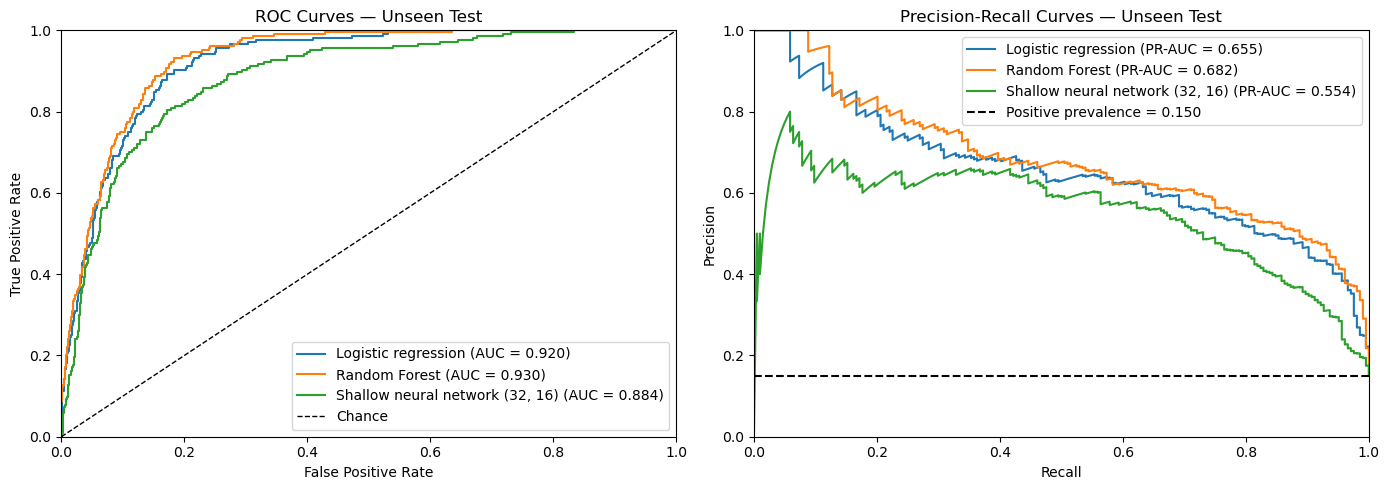

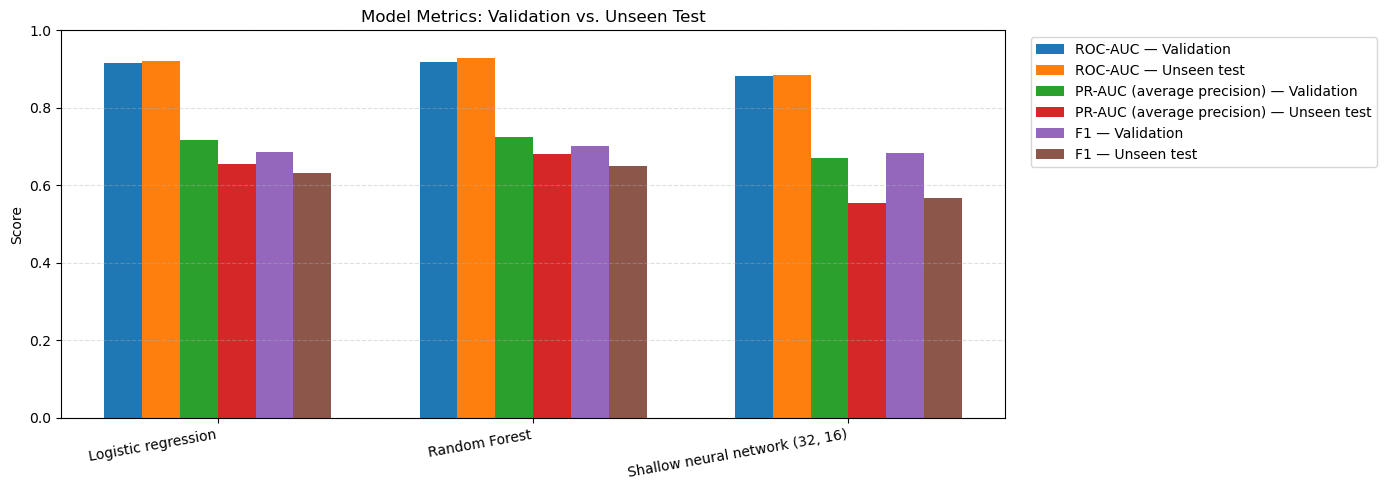

In [248]:
# no need to change because of lower year bound and feature set change
from sklearn.metrics import roc_curve

model_order = [
    "Logistic regression",
    "Random Forest",
    "Shallow neural network (32, 16)",
]
colors = {
    "Logistic regression": "tab:blue",
    "Random Forest": "tab:orange",
    "Shallow neural network (32, 16)": "tab:green",
}

# ROC and precision-recall curves on the unseen test set
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in model_order:
    probabilities = models[name].predict_proba(X_test_enc)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    roc_auc = roc_auc_score(y_test, probabilities)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} (AUC = {roc_auc:.3f})")

    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    pr_auc = average_precision_score(y_test, probabilities)
    axes[1].plot(recall, precision, color=colors[name], label=f"{name} (PR-AUC = {pr_auc:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Chance")
axes[0].set(title="ROC Curves — Unseen Test", xlabel="False Positive Rate",
            ylabel="True Positive Rate", xlim=(0, 1), ylim=(0, 1))
axes[0].legend()

prevalence = y_test.mean()
axes[1].axhline(prevalence, color="black", linestyle="--",
                label=f"Positive prevalence = {prevalence:.3f}")
axes[1].set(title="Precision-Recall Curves — Unseen Test",
            xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
axes[1].legend()

plt.tight_layout()
plt.show()


# Grouped bars: each model has one bar for each metric/split combination
metrics = ["ROC-AUC", "PR-AUC (average precision)", "F1"]
splits_to_plot = ["Validation", "Unseen test"]
series = [(metric, split) for metric in metrics for split in splits_to_plot]

x = np.arange(len(model_order))
bar_width = 0.12
offsets = (np.arange(len(series)) - (len(series) - 1) / 2) * bar_width

fig, ax = plt.subplots(figsize=(14, 5))
for i, (metric, split) in enumerate(series):
    values = [
        evaluation_results.loc[(name, split), metric]
        for name in model_order
    ]
    ax.bar(
        x + offsets[i],
        values,
        width=bar_width,
        label=f"{metric} — {split}",
    )

ax.set_xticks(x)
ax.set_xticklabels(model_order, rotation=10, ha="right")
ax.set_ylabel("Score")
ax.set_title("Model Metrics: Validation vs. Unseen Test")
ax.set_ylim(0, 1)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

,Model,Removed group,Columns removed,Validation Δ PR-AUC,Validation Δ F1,Test Δ PR-AUC,Test Δ F1
0,Logistic regression,Circuit features,71,-0.0023,-0.0047,-0.0039,0.0785
1,Logistic regression,Form features,2,0.0461,0.0242,0.0469,0.0179
2,Logistic regression,Grid,1,0.0535,-0.0080,0.0911,0.0819
3,Logistic regression,Standings & Experience,3,-0.0044,-0.0051,-0.0005,0.1268
4,Random Forest,Circuit features,71,0.0493,0.0125,-0.0028,-0.0183
5,Random Forest,Form features,2,0.0329,0.0213,0.0185,0.0092
6,Random Forest,Grid,1,0.0675,0.0185,0.1114,0.1027
7,Random Forest,Standings & Experience,3,-0.0341,-0.0072,0.0111,-0.0126
8,"Shallow neural network (32, 16)",Circuit features,71,-0.0552,-0.0096,-0.0955,-0.0585
9,"Shallow neural network (32, 16)",Form features,2,0.1068,0.0973,-0.0044,0.0046


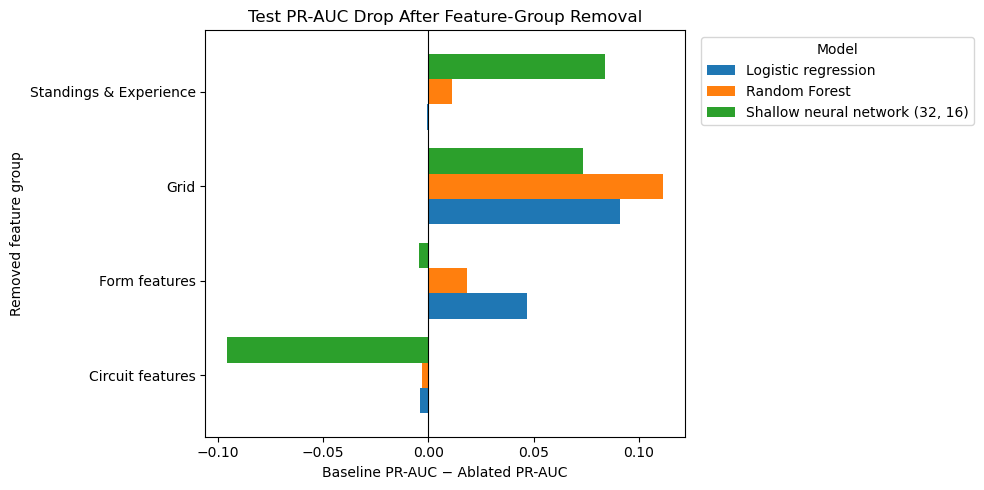

In [249]:
from sklearn.base import clone

# Build non-overlapping feature groups from the encoded training columns.
# feature_groups = {
#     "Form features": [
#         col for col in X_train_enc.columns if "form" in col.lower()
#     ],
#     "Grid & Qualifying": [
#         col for col in X_train_enc.columns
#         if "grid" in col.lower() or "quali" in col.lower()
#     ],
#     "Standings & Experience": [
#         col for col in X_train_enc.columns
#         if any(token in col.lower() for token in ("standings", "points", "wins"))
#     ],
#     "Circuit features": [
#         col for col in X_train_enc.columns if col.startswith("circuitId_")
#     ],
# }

# Build non-overlapping feature groups from the encoded training columns.
# changed to reflect lower year bound and accordingly new feature set
# with no lower bound year and excluding pit lane start, position, and any constructor data
feature_groups = {
    "Form features": [
        col for col in X_train_enc.columns if "form" in col.lower()
    ],
    "Grid": [
        col for col in X_train_enc.columns if "grid" in col.lower()
    ],
    "Standings & Experience": [
        col for col in X_train_enc.columns if any(token in col.lower() for token in ("standings", "points", "wins", "races_prior"))
    ],
    "Circuit features": [
        col for col in X_train_enc.columns if col.startswith("circuitId_")
    ],
}

# Baseline metrics, using validation-selected F1 thresholds.
baseline = {}
for model_name, model in models.items():
    val_prob = model.predict_proba(X_val_enc)[:, 1]
    test_prob = model.predict_proba(X_test_enc)[:, 1]
    threshold, _ = choose_f1_threshold(y_val, val_prob)

    baseline[model_name] = {
        "val_pr_auc": average_precision_score(y_val, val_prob),
        "val_f1": f1_score(y_val, val_prob >= threshold, zero_division=0),
        "test_pr_auc": average_precision_score(y_test, test_prob),
        "test_f1": f1_score(y_test, test_prob >= threshold, zero_division=0),
    }

# Refit cloned models after removing each feature group.
ablation_rows = []
for group_name, columns_to_drop in feature_groups.items():
    if not columns_to_drop:
        print(f"Skipping {group_name}: no matching columns.")
        continue

    X_train_abl = X_train_enc.drop(columns=columns_to_drop)
    X_val_abl = X_val_enc.drop(columns=columns_to_drop)
    X_test_abl = X_test_enc.drop(columns=columns_to_drop)

    for model_name, original_model in models.items():
        ablated_model = clone(original_model)
        ablated_model.fit(X_train_abl, y_train)

        val_prob = ablated_model.predict_proba(X_val_abl)[:, 1]
        test_prob = ablated_model.predict_proba(X_test_abl)[:, 1]
        threshold, _ = choose_f1_threshold(y_val, val_prob)

        val_pr_auc = average_precision_score(y_val, val_prob)
        val_f1 = f1_score(y_val, val_prob >= threshold, zero_division=0)
        test_pr_auc = average_precision_score(y_test, test_prob)
        test_f1 = f1_score(y_test, test_prob >= threshold, zero_division=0)

        base = baseline[model_name]
        ablation_rows.append({
            "Model": model_name,
            "Removed group": group_name,
            "Columns removed": len(columns_to_drop),
            "Validation Δ PR-AUC": base["val_pr_auc"] - val_pr_auc,
            "Validation Δ F1": base["val_f1"] - val_f1,
            "Test Δ PR-AUC": base["test_pr_auc"] - test_pr_auc,
            "Test Δ F1": base["test_f1"] - test_f1,
        })

ablation_results = (
    pd.DataFrame(ablation_rows)
    .sort_values(["Model", "Removed group"])
    .reset_index(drop=True)
)

display(ablation_results.round(4))

# Horizontal bars show test PR-AUC drop; positive values indicate degradation.
plot_data = ablation_results.pivot(
    index="Removed group", columns="Model", values="Test Δ PR-AUC"
)
ax = plot_data.plot(kind="barh", figsize=(10, 5), width=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    title="Test PR-AUC Drop After Feature-Group Removal",
    xlabel="Baseline PR-AUC − Ablated PR-AUC",
    ylabel="Removed feature group",
)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()